# Deteksi Ujaran Kebencian Multi-Label Bahasa Indonesia

Notebook tunggal untuk seluruh penelitian: data, preprocessing, metode, eksperimen, evaluasi, uji statistik, dan analisis kesalahan. Dataset: Ibrohim & Budi (2019), 12 label ujaran kebencian dan bahasa kasar dari Twitter.

**Pertanyaan penelitian**
- **RQ1.** Bagaimana kinerja empat keluarga algoritma (Bayesian, SVM, Ensemble Tree, ANN) pada 12 label bila dievaluasi dengan metrik yang tepat untuk data tidak seimbang?
- **RQ2.** Apakah class weighting, MLSMOTE, dan tuning ambang per label memperbaiki kinerja, terutama di label minoritas?
- **RQ3.** Apakah perbedaan antar algoritma signifikan secara statistik?
- **RQ4.** Seberapa jauh model bisa digeneralisasi ke korpus lain (IndoToxic2024)?

**Daftar isi**
1. Konfigurasi dan setup
2. Komponen metode (label, preprocessing, TF-IDF, MLSMOTE, model, strategi multi-label, tuning, metrik, statistik)
3. Data dan EDA
4. Preprocessing dan deduplikasi
5. Pembagian 5 fold
6. Cek MLSMOTE di data asli
7. Grid eksperimen model klasik
8. IndoBERTweet (pembanding batas atas, butuh GPU)
9. Evaluasi dan uji statistik
10. Explainability dan analisis kesalahan
11. Eksperimen lanjutan (post-processing hierarki, ML-ROS, fitur karakter, precision/recall minoritas, transformer v2, pemilihan ambang)
12. Uji lintas korpus ke IndoToxic2024 (RQ4)

**Cara menjalankan.** Jalankan semua sel dari atas. Bagian yang mahal (grid dan IndoBERTweet) **bisa dilanjutkan**: run yang sudah tercatat di `results/experiments.csv` dilewati, jadi notebook aman dijalankan ulang. Model GPU (XGBoost, MLP, IndoBERTweet) otomatis memakai CUDA bila tersedia.

**Aturan anti kebocoran data.** TF-IDF, MLSMOTE, pemilihan hyperparameter, dan pemilihan ambang hanya memakai data latih tiap fold. Data uji fold luar tidak pernah dipakai untuk memilih apa pun.

## 1. Konfigurasi dan setup

In [1]:
# ==== KONFIGURASI (ubah di sini saja) ====
RANDOM_STATE = 42
RESULTS_CSV = "experiments.csv"   # satu baris per run (konfigurasi x fold)
RUN_GRID = True                   # jalankan grid model klasik (resume otomatis)
RUN_GPU_MODELS = None             # XGBoost & MLP. None = otomatis (True bila ada GPU)
RUN_BERT = None                   # IndoBERTweet. None = otomatis (True bila ada GPU)
BERT_MODEL = "indolem/indobertweet-base-uncased"
BERT_FALLBACK = "indobenchmark/indobert-base-p1"
N_JOBS_CPU = None                 # None = otomatis (jumlah CPU - 1, maks 4)
DATA_REPO = "https://github.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection"

In [2]:
import os, sys, json, math, random, re, subprocess, time
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "iterative-stratification", "scikit-posthocs",
                    "xgboost>=2.0"], check=True)

ROOT = Path.cwd()
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
RES, FIG = ROOT / "results", ROOT / "figures"
for p in [RAW, PROC, RES, FIG, RES / "preds"]:
    p.mkdir(parents=True, exist_ok=True)

if not (RAW / "re_dataset.csv").exists():   # unduh dataset bila belum ada
    tmp = ROOT / "data" / "_src"
    if not tmp.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", DATA_REPO, str(tmp)], check=True)
    for f in ["re_dataset.csv", "new_kamusalay.csv", "abusive.csv", "citation.bib"]:
        (RAW / f).write_bytes((tmp / f).read_bytes())

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "-"
except ImportError:
    DEVICE, GPU_NAME = "cpu", "- (torch tidak terpasang)"
if RUN_GPU_MODELS is None:
    RUN_GPU_MODELS = DEVICE == "cuda"
if RUN_BERT is None:
    RUN_BERT = DEVICE == "cuda"
if N_JOBS_CPU is None:
    N_JOBS_CPU = max(1, min(4, (os.cpu_count() or 2) - 1))
print(f"ROOT={ROOT} | device={DEVICE} ({GPU_NAME}) | model GPU={RUN_GPU_MODELS} | IndoBERTweet={RUN_BERT} | CPU paralel={N_JOBS_CPU}")

ROOT=C:\Users\RXD\Downloads\ML Projek | device=cuda (NVIDIA GeForce RTX 4060 Laptop GPU) | model GPU=True | IndoBERTweet=True | CPU paralel=4


## 2. Komponen metode
Semua komponen ditulis sebagai fungsi atau kelas di bagian ini, lalu dipakai oleh bagian data, eksperimen, dan evaluasi.

### 2.1 Label dan aturan hierarki
Aturan diverifikasi langsung dari data: jika HS = 0 semua label HS_* bernilai 0. Jika HS = 1, tweet punya tepat satu target, tepat satu tingkat, dan minimal satu kategori. HS_Other tidak pernah muncul bersama kategori spesifik. Abusive berdiri sendiri.

In [3]:
import numpy as np

LABELS = [
    "HS", "Abusive",
    "HS_Individual", "HS_Group",
    "HS_Religion", "HS_Race", "HS_Physical", "HS_Gender", "HS_Other",
    "HS_Weak", "HS_Moderate", "HS_Strong",
]
IDX = {name: i for i, name in enumerate(LABELS)}

TARGETS = ["HS_Individual", "HS_Group"]
SPECIFIC_CATS = ["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender"]
OTHER_CAT = "HS_Other"
LEVELS = ["HS_Weak", "HS_Moderate", "HS_Strong"]
HS_CHILDREN = TARGETS + SPECIFIC_CATS + [OTHER_CAT] + LEVELS


def hierarchy_violations(Y: np.ndarray) -> dict:
    """Hitung jumlah baris yang melanggar tiap aturan hierarki.

    Y: matriks biner (n_sampel, 12) dengan urutan kolom = LABELS.
    """
    Y = np.asarray(Y).astype(int)
    hs = Y[:, IDX["HS"]]
    child = Y[:, [IDX[c] for c in HS_CHILDREN]].sum(axis=1)
    tgt = Y[:, [IDX[c] for c in TARGETS]].sum(axis=1)
    lvl = Y[:, [IDX[c] for c in LEVELS]].sum(axis=1)
    spec = Y[:, [IDX[c] for c in SPECIFIC_CATS]].sum(axis=1)
    oth = Y[:, IDX[OTHER_CAT]]
    is_hs = hs == 1
    out = {
        "hs0_but_child1": int(((hs == 0) & (child > 0)).sum()),
        "hs1_target_not_exactly_one": int((is_hs & (tgt != 1)).sum()),
        "hs1_level_not_exactly_one": int((is_hs & (lvl != 1)).sum()),
        "hs1_no_category": int((is_hs & (spec + oth == 0)).sum()),
        "other_with_specific": int(((oth == 1) & (spec > 0)).sum()),
    }
    out["any_violation_rows"] = int(violation_mask(Y).sum())
    return out


def violation_mask(Y: np.ndarray) -> np.ndarray:
    """Mask boolean: baris mana yang melanggar minimal satu aturan."""
    Y = np.asarray(Y).astype(int)
    hs = Y[:, IDX["HS"]]
    child = Y[:, [IDX[c] for c in HS_CHILDREN]].sum(axis=1)
    tgt = Y[:, [IDX[c] for c in TARGETS]].sum(axis=1)
    lvl = Y[:, [IDX[c] for c in LEVELS]].sum(axis=1)
    spec = Y[:, [IDX[c] for c in SPECIFIC_CATS]].sum(axis=1)
    oth = Y[:, IDX[OTHER_CAT]]
    is_hs = hs == 1
    return (
        ((hs == 0) & (child > 0))
        | (is_hs & (tgt != 1))
        | (is_hs & (lvl != 1))
        | (is_hs & (spec + oth == 0))
        | ((oth == 1) & (spec > 0))
    )


def repair_labelset(y: np.ndarray, scores: np.ndarray, seed_y: np.ndarray) -> np.ndarray:
    """Perbaiki satu label set agar konsisten dengan hierarki.

    y      : label set hasil aturan ranking MLSMOTE (biner, panjang 12).
    scores : frekuensi tiap label di antara seed + tetangga (dipakai untuk
             memilih label saat harus memilih satu dari satu grup).
    seed_y : label set seed. Dipakai sebagai pemecah seri, sehingga
             hasil perbaikan cenderung mengikuti seed.

    Aturan:
    1. Jika ada label HS_* = 1, maka HS = 1.
    2. Jika HS = 0, semua HS_* = 0.
    3. Jika HS = 1: target dan tingkat dipaksa tepat satu (skor tertinggi,
       seri dipecah oleh seed). Kategori minimal satu. Jika HS_Other muncul
       bersama kategori spesifik, pilih sisi dengan skor tertinggi.
    """
    y = np.asarray(y).astype(int).copy()
    scores = np.asarray(scores, dtype=float)
    seed_y = np.asarray(seed_y).astype(int)
    tie = scores + 0.5 * seed_y  # seed menang saat seri

    child_idx = [IDX[c] for c in HS_CHILDREN]
    if y[child_idx].sum() > 0:
        y[IDX["HS"]] = 1
    if y[IDX["HS"]] == 0:
        y[child_idx] = 0
        return y

    def pick_one(group):
        gi = [IDX[c] for c in group]
        best = gi[int(np.argmax(tie[gi]))]
        y[gi] = 0
        y[best] = 1

    pick_one(TARGETS)
    pick_one(LEVELS)

    spec_i = [IDX[c] for c in SPECIFIC_CATS]
    oth_i = IDX[OTHER_CAT]
    has_spec = y[spec_i].sum() > 0
    has_oth = y[oth_i] == 1
    if has_spec and has_oth:
        if tie[oth_i] > tie[spec_i].max():
            y[spec_i] = 0
        else:
            y[oth_i] = 0
    elif not has_spec and not has_oth:
        pick_one(SPECIFIC_CATS + [OTHER_CAT])
    return y

### 2.2 Preprocessing
Lowercase, hapus token USER/URL/RT, hapus emoji yang tersimpan sebagai teks `\xf0\x9f...`, tangani reduplikasi (`kita2` menjadi `kita kita`), hapus angka dan tanda baca, rapikan huruf berulang, lalu normalisasi slang dengan kamus alay bawaan dataset. **Tanpa stemming dan tanpa stopword removal** (mengikuti Hana dkk. 2020 dan Hendrawan dkk. 2020).

In [4]:
import re
from pathlib import Path

import numpy as np
import pandas as pd


# Pola noise yang ditemukan di re_dataset.csv
_RE_ESCAPED_BYTES = re.compile(r"\\x[0-9a-fA-F]{2}")      # emoji tersimpan sebagai teks "\xf0\x9f..."
_RE_ESCAPED_NL = re.compile(r"\\n")                          # newline tersimpan sebagai teks "\n"
_RE_SPECIAL_TOKENS = re.compile(r"\b(?:user|url|rt)\b")
_RE_HTTP = re.compile(r"https?://\S+|www\.\S+")
_RE_HTML_ENT = re.compile(r"&[a-z]+;")
_RE_REDUP = re.compile(r"\b([a-z]{2,})2(?![0-9])")
_RE_DIGIT = re.compile(r"[0-9]+")
_RE_NON_ALPHA = re.compile(r"[^a-z\s]")
_RE_REPEAT = re.compile(r"([a-z])\1{2,}")                    # "bangeeett" -> "banget"
_RE_SPACES = re.compile(r"\s+")


def load_raw(path: str | Path) -> pd.DataFrame:
    """Load re_dataset.csv. File memakai encoding latin-1 (utf-8 gagal)."""
    try:
        df = pd.read_csv(path, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding="latin-1")
    missing = [c for c in ["Tweet"] + LABELS if c not in df.columns]
    if missing:
        raise ValueError(f"Kolom hilang: {missing}")
    return df


def load_kamus(path: str | Path) -> dict:
    """Load new_kamusalay.csv (tanpa header: kata_alay, kata_baku)."""
    kamus = pd.read_csv(path, encoding="latin-1", header=None, names=["alay", "baku"])
    kamus = kamus.dropna().drop_duplicates("alay", keep="first")
    return dict(zip(kamus["alay"].str.strip(), kamus["baku"].str.strip()))


def clean_text(text: str) -> str:
    """Tahap cleaning (sebelum normalisasi slang)."""
    t = str(text)
    t = _RE_ESCAPED_BYTES.sub(" ", t)
    t = _RE_ESCAPED_NL.sub(" ", t)
    t = t.lower()
    t = _RE_HTTP.sub(" ", t)
    t = _RE_HTML_ENT.sub(" ", t)
    t = _RE_SPECIAL_TOKENS.sub(" ", t)
    t = _RE_REDUP.sub(r"\1 \1", t)        # "kita2" -> "kita kita", "lucu2an" -> "lucu lucuan"
    t = _RE_DIGIT.sub("", t)              # angka dihapus tanpa memecah kata: "g30spki" -> "gspki"
    t = _RE_NON_ALPHA.sub(" ", t)        # hapus tanda baca, simbol, sisa byte non-ASCII
    t = _RE_REPEAT.sub(r"\1", t)
    t = _RE_SPACES.sub(" ", t).strip()
    return t


def normalize_slang(text: str, kamus: dict) -> str:
    """Ganti kata alay per token. Hasil kamus bisa berisi lebih dari satu kata."""
    return " ".join(kamus.get(tok, tok) for tok in text.split())


def build_preprocessor(kamus: dict, use_stemming: bool = False, use_stopwords: bool = False):
    """Kembalikan fungsi preprocess(text) sesuai konfigurasi.

    Stemming/stopword hanya untuk ablation (Gap 6), default False.
    """
    stemmer = None
    stopwords = set()
    if use_stemming or use_stopwords:
        try:
            from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
            from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
        except ImportError as e:  # pragma: no cover
            raise ImportError("Install dulu: pip install Sastrawi") from e
        if use_stemming:
            stemmer = StemmerFactory().create_stemmer()
        if use_stopwords:
            stopwords = set(StopWordRemoverFactory().get_stop_words())

    def preprocess(text: str) -> str:
        t = normalize_slang(clean_text(text), kamus)
        if stopwords:
            t = " ".join(w for w in t.split() if w not in stopwords)
        if stemmer is not None:
            t = stemmer.stem(t)
        return t

    return preprocess


def deduplicate(df: pd.DataFrame, text_col: str = "text_clean") -> tuple[pd.DataFrame, dict]:
    """Hapus duplikat berdasarkan teks bersih.

    - Duplikat dengan label identik: simpan satu.
    - Duplikat dengan label berbeda (konflik anotasi): buang semuanya, karena
      tidak ada dasar untuk memilih label yang benar.
    - Baris dengan teks kosong setelah cleaning: buang.

    Alasan: duplikat yang tersebar di fold latih dan uji menyebabkan
    kebocoran data (model "menghafal" teks yang sama).
    """
    n0 = len(df)
    empty = df[text_col].str.len() == 0
    df = df[~empty]
    n_label_variants = df.groupby(text_col)[LABELS].nunique().max(axis=1)
    conflict_texts = set(n_label_variants[n_label_variants > 1].index)
    is_conflict = df[text_col].isin(conflict_texts)
    df_ok = df[~is_conflict]
    dup_same = df_ok.duplicated(text_col, keep="first")
    df_out = df_ok[~dup_same].reset_index(drop=True)
    report = {
        "rows_raw": n0,
        "rows_empty_after_clean": int(empty.sum()),
        "conflicting_texts": len(conflict_texts),
        "rows_dropped_conflict": int(is_conflict.sum()),
        "rows_dropped_same_label_dup": int(dup_same.sum()),
        "rows_final": len(df_out),
    }
    return df_out, report


def mask_abusive(text: str, abusive_words: set) -> str:
    """Samarkan kata kasar untuk ditampilkan di paper, contoh: 'bego' -> 'b**o'."""
    out = []
    for w in str(text).split():
        core = re.sub(r"[^a-zA-Z]", "", w).lower()
        if core in abusive_words and len(core) > 2:
            out.append(w[0] + "*" * (len(w) - 2) + w[-1])
        else:
            out.append(w)
    return " ".join(out)


def load_abusive(path: str | Path) -> set:
    return set(pd.read_csv(path, encoding="latin-1")["ABUSIVE"].str.strip().str.lower())


def label_matrix(df: pd.DataFrame) -> np.ndarray:
    return df[LABELS].to_numpy(dtype=int)

### 2.3 TF-IDF dengan pemilihan fitur deterministik
`TfidfVectorizer(max_features=5000)` di scikit-learn memilih fitur dengan sort yang tidak stabil. Di data ini ada ratusan term dengan frekuensi sama di batas 5.000 (di fold 0: 921 term berfrekuensi 6, hanya 202 yang masuk), sehingga hasil bisa berbeda antar mesin sampai 0,014 macro F1. Kelas di bawah memakai kriteria yang sama (frekuensi term di data latih) dengan pemecah seri alfabet, sehingga hasil reprodusibel.

In [5]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


class StableTfidfVectorizer(BaseEstimator, TransformerMixin):
    def __init__(self, ngram_range=(1, 2), max_features=5000, sublinear_tf=True, min_df=1, analyzer="word"):
        self.analyzer = analyzer
        self.ngram_range = ngram_range
        self.max_features = max_features
        self.sublinear_tf = sublinear_tf
        self.min_df = min_df

    def fit(self, texts, y=None):
        cv = CountVectorizer(ngram_range=self.ngram_range, min_df=self.min_df, analyzer=self.analyzer)
        counts = cv.fit_transform(texts)
        terms = cv.get_feature_names_out()
        tf = np.asarray(counts.sum(axis=0)).ravel()
        order = np.lexsort((terms, -tf))          # frekuensi menurun, seri -> alfabet
        keep = order[: self.max_features] if self.max_features else order
        vocab = sorted(terms[keep].tolist())
        self.vec_ = TfidfVectorizer(ngram_range=self.ngram_range, sublinear_tf=self.sublinear_tf,
                                    analyzer=self.analyzer, vocabulary=vocab).fit(texts)
        return self

    def transform(self, texts):
        return self.vec_.transform(texts)

    def fit_transform(self, texts, y=None):
        return self.fit(texts).transform(texts)

    def get_feature_names_out(self):
        return self.vec_.get_feature_names_out()

### 2.4 MLSMOTE (Charte dkk., 2015)
Implementasi mengikuti Algorithm 1 dan 2 di paper asli: label minoritas = IRLbl > MeanIR (MeanIR dihitung sekali), tetangga dicari di dalam minBag, fitur sintetis = interpolasi seed dan tetangga acak, label sintetis memakai strategi ranking (frekuensi > (k+1)/2). Tambahan: opsi perbaikan hierarki label (`repair_fn`) dan pencarian tetangga yang deterministik.

In [6]:
from typing import Callable, Optional

import numpy as np
import scipy.sparse as sp
from sklearn.metrics.pairwise import euclidean_distances


def irlbl(Y: np.ndarray) -> np.ndarray:
    """Imbalance ratio per label. Label tanpa instance positif diberi inf."""
    counts = np.asarray(Y).sum(axis=0).astype(float)
    with np.errstate(divide="ignore"):
        return np.where(counts > 0, counts.max() / counts, np.inf)


def mean_ir(Y: np.ndarray) -> float:
    r = irlbl(Y)
    return float(r[np.isfinite(r)].mean())


class MLSMOTE:
    """MLSMOTE sesuai Charte dkk. (2015).

    Parameter
    ---------
    k : int, default 5 (nilai default di paper).
    threshold : 'strict' -> frekuensi > (k+1)/2 (rumus Algorithm 2).
                'half'   -> frekuensi >= (k+1)/2 (teks paper).
    repair_fn : fungsi (y, scores, seed_y) -> y untuk menjaga konsistensi
                label. None berarti tanpa perbaikan (MLSMOTE murni).
    random_state : int.
    """

    def __init__(self, k: int = 5, threshold: str = "strict",
                 repair_fn: Optional[Callable] = None,
                 random_state: int = 42):
        if threshold not in {"strict", "half"}:
            raise ValueError("threshold harus 'strict' atau 'half'")
        self.k = k
        self.threshold = threshold
        self.repair_fn = repair_fn
        self.random_state = random_state

    def fit_resample(self, X, Y):
        rng = np.random.default_rng(self.random_state)
        is_sparse = sp.issparse(X)
        X = sp.csr_matrix(X, dtype=np.float64) if is_sparse else np.asarray(X, dtype=np.float64)
        Y = np.asarray(Y).astype(np.int8)
        n_labels = Y.shape[1]

        m_ir = mean_ir(Y)  # dihitung sekali (Algorithm 1)
        X_parts, Y_parts = [X], [Y]
        cur_counts = Y.sum(axis=0).astype(float)

        self.stats_ = {
            "mean_ir": m_ir,
            "irlbl_before": irlbl(Y).tolist(),
            "processed_labels": [],
            "n_synthetic": 0,
            "n_repaired": 0,
            "n_skipped_small_bag": 0,
        }

        for lbl in range(n_labels):
            # IRLbl dihitung ulang di awal siklus tiap label
            with np.errstate(divide="ignore"):
                ir_now = cur_counts.max() / cur_counts[lbl] if cur_counts[lbl] > 0 else np.inf
            if not (ir_now > m_ir) or not np.isfinite(ir_now):
                continue

            X_all = sp.vstack(X_parts, format="csr") if is_sparse else np.vstack(X_parts)
            Y_all = np.vstack(Y_parts)
            bag = np.where(Y_all[:, lbl] == 1)[0]
            if len(bag) < 2:
                self.stats_["n_skipped_small_bag"] += 1
                continue

            Xb, Yb = X_all[bag], Y_all[bag]
            k_eff = min(self.k, len(bag) - 1)
            # Tetangga terdekat yang deterministik antar mesin: jarak dibulatkan
            # (menghapus selisih floating point di digit terakhir), lalu seri
            # dipecah secara stabil berdasarkan indeks.
            D = np.round(euclidean_distances(Xb), 9)
            np.fill_diagonal(D, np.inf)
            nbr = np.argsort(D, axis=1, kind="stable")[:, :k_eff]

            new_X, new_Y = [], []
            n_rep = 0
            for i in range(len(bag)):
                neigh = list(nbr[i])
                ref = neigh[rng.integers(len(neigh))]
                gap = rng.random()
                xs = Xb[i] + gap * (Xb[ref] - Xb[i])

                counts = Yb[i].astype(int) + Yb[neigh].sum(axis=0)
                half = (k_eff + 1) / 2.0
                ys = (counts > half) if self.threshold == "strict" else (counts >= half)
                ys = ys.astype(np.int8)
                if self.repair_fn is not None:
                    fixed = np.asarray(self.repair_fn(ys, counts, Yb[i])).astype(np.int8)
                    if not np.array_equal(fixed, ys):
                        n_rep += 1
                    ys = fixed
                new_X.append(xs)
                new_Y.append(ys)

            Xn = sp.vstack(new_X, format="csr") if is_sparse else np.vstack(new_X)
            Yn = np.vstack(new_Y).astype(np.int8)
            X_parts.append(Xn)
            Y_parts.append(Yn)
            cur_counts += Yn.sum(axis=0)
            self.stats_["processed_labels"].append(int(lbl))
            self.stats_["n_synthetic"] += len(new_Y)
            self.stats_["n_repaired"] += n_rep

        X_out = sp.vstack(X_parts, format="csr") if is_sparse else np.vstack(X_parts)
        Y_out = np.vstack(Y_parts).astype(int)
        self.stats_["irlbl_after"] = irlbl(Y_out).tolist()
        self.stats_["mean_ir_after"] = mean_ir(Y_out)
        return X_out, Y_out

### 2.5 Model dasar
- **Bayesian:** Complement NB. **SVM:** LinearSVC. **Ensemble Tree:** XGBoost (CUDA bila ada). **ANN:** MLP PyTorch (CUDA bila ada). Random Forest hanya untuk pembanding baseline (LP).
- Hyperparameter tetap ada di `BASE_PARAMS`. Kandidat tuning (dipilih lewat validasi dalam) ada di `TUNING_GRID`.
- Kondisi `weight`: CNB memakai sample_weight seimbang, LinearSVC `class_weight="balanced"`, XGBoost `scale_pos_weight`, MLP `pos_weight` di BCE loss.
- **Strategi multi-label:** Binary Relevance (BR), Classifier Chain (CC, urutan rantai = urutan label), Label Powerset (LP, hanya pembanding baseline).

In [7]:
import numpy as np
import scipy.sparse as sp

_DEVICE = None


def torch_device() -> str:
    global _DEVICE
    if _DEVICE is None:
        try:
            import torch
            _DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
        except ImportError:
            _DEVICE = "cpu"
    return _DEVICE


class TorchMLPBinary:
    def __init__(self, hidden=256, dropout=0.3, lr=1e-3, weight_decay=1e-5, batch_size=128,
                 max_epochs=30, patience=3, val_fraction=0.1, pos_weight_balanced=False,
                 random_state=42):
        self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
        self.batch_size, self.max_epochs, self.patience = batch_size, max_epochs, patience
        self.val_fraction, self.pos_weight_balanced = val_fraction, pos_weight_balanced
        self.random_state = random_state

    def _batches(self, X, idx, torch, dev):
        for s in range(0, len(idx), self.batch_size):
            b = idx[s:s + self.batch_size]
            xb = X[b]
            xb = xb.toarray() if sp.issparse(xb) else np.asarray(xb)
            yield b, torch.from_numpy(xb.astype(np.float32)).to(dev, non_blocking=True)

    def fit(self, X, y):
        import torch
        from torch import nn
        dev = torch_device()
        torch.manual_seed(self.random_state)
        if dev == "cuda":
            torch.cuda.manual_seed_all(self.random_state)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        rng = np.random.default_rng(self.random_state)
        X = sp.csr_matrix(X, dtype=np.float32)
        y = np.asarray(y).astype(np.float32)

        # split validasi internal secara stratified
        pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        nvp = max(1, int(round(len(pos) * self.val_fraction)))
        nvn = max(1, int(round(len(neg) * self.val_fraction)))
        vp, vn = rng.permutation(pos)[:nvp], rng.permutation(neg)[:nvn]
        va = np.concatenate([vp, vn])
        tr = np.setdiff1d(np.arange(len(y)), va)

        d = X.shape[1]
        self.model_ = nn.Sequential(nn.Linear(d, self.hidden), nn.ReLU(), nn.Dropout(self.dropout),
                                    nn.Linear(self.hidden, 1)).to(dev)
        pw = None
        if self.pos_weight_balanced:
            npos = max(y[tr].sum(), 1.0)
            pw = torch.tensor([(len(tr) - npos) / npos], device=dev)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
        opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        yt = torch.from_numpy(y).to(dev)

        best, best_state, bad = np.inf, None, 0
        for epoch in range(self.max_epochs):
            self.model_.train()
            perm = rng.permutation(tr)
            for b, xb in self._batches(X, perm, torch, dev):
                opt.zero_grad(set_to_none=True)
                loss = loss_fn(self.model_(xb).squeeze(1), yt[b])
                loss.backward()
                opt.step()
            self.model_.eval()
            with torch.no_grad():
                tot = 0.0
                for b, xb in self._batches(X, va, torch, dev):
                    tot += loss_fn(self.model_(xb).squeeze(1), yt[b]).item() * len(b)
                vloss = tot / len(va)
            if vloss < best - 1e-4:
                best, bad = vloss, 0
                best_state = {k: v.detach().clone() for k, v in self.model_.state_dict().items()}
            else:
                bad += 1
                if bad >= self.patience:
                    break
        if best_state is not None:
            self.model_.load_state_dict(best_state)
        self.n_epochs_ = epoch + 1
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        import torch
        dev = torch_device()
        X = sp.csr_matrix(X, dtype=np.float32)
        self.model_.eval()
        out = []
        with torch.no_grad():
            for _, xb in self._batches(X, np.arange(X.shape[0]), torch, dev):
                out.append(torch.sigmoid(self.model_(xb).squeeze(1)).float().cpu().numpy())
        p = np.concatenate(out)
        return np.column_stack([1 - p, p])

In [8]:
import numpy as np
import scipy.sparse as sp
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight


RANDOM_STATE = 42

BASE_PARAMS = {
    "cnb": {"alpha": 1.0},
    "svm": {"C": 1.0, "max_iter": 5000, "random_state": RANDOM_STATE},
    "xgb": {"n_estimators": 300, "learning_rate": 0.1, "max_depth": 6, "subsample": 0.8,
            "colsample_bytree": 0.5, "min_child_weight": 1, "tree_method": "hist",
            "random_state": RANDOM_STATE, "n_jobs": 4, "verbosity": 0},
    "mlp": {"hidden": 256, "dropout": 0.3, "lr": 1e-3, "weight_decay": 1e-5, "batch_size": 128,
            "max_epochs": 30, "patience": 3, "val_fraction": 0.1, "random_state": RANDOM_STATE},
    # Hanya untuk LP: replikasi baseline Ibrohim & Budi (2019), RFDT + LP
    "rf": {"n_estimators": 100, "random_state": RANDOM_STATE, "n_jobs": -1},
}

# Ruang pencarian kecil untuk tuning lewat validasi dalam (dipilih berdasarkan macro F1)
TUNING_GRID = {
    "cnb": [{"alpha": a} for a in (0.1, 0.3, 1.0)],
    "svm": [{"C": c} for c in (0.1, 0.3, 1.0, 3.0)],
    "xgb": [{}],      # hanya ambang yang di-tuning (biaya komputasi)
    "mlp": [{}],      # hanya ambang yang di-tuning (biaya komputasi)
    "rf": [{}],
}

ALGO_FAMILY = {"cnb": "Bayesian", "svm": "SVM", "xgb": "Ensemble Tree", "mlp": "ANN",
               "rf": "Ensemble Tree", "bert": "Transformer"}
ALGO_NAME = {"cnb": "Complement NB", "svm": "LinearSVC", "xgb": "XGBoost", "mlp": "MLP",
             "rf": "Random Forest", "bert": "IndoBERTweet", "lgbm": "LightGBM (v1)"}


def xgb_device() -> str:
    return "cuda" if torch_device() == "cuda" else "cpu"


def make_estimator(algo: str, weight: bool, y: np.ndarray | None = None, override: dict | None = None):
    p = dict(BASE_PARAMS[algo])
    p.update(override or {})
    if algo == "cnb":
        return ComplementNB(**p)
    if algo == "svm":
        if weight:
            p["class_weight"] = "balanced"
        return LinearSVC(**p)
    if algo == "xgb":
        from xgboost import XGBClassifier
        if weight and y is not None:
            pos = max(int(y.sum()), 1)
            p["scale_pos_weight"] = (len(y) - pos) / pos
        return XGBClassifier(device=xgb_device(), **p)
    if algo == "mlp":
        return TorchMLPBinary(pos_weight_balanced=weight, **p)
    if algo == "rf":
        return RandomForestClassifier(**p)
    raise ValueError(algo)


def _fit_binary(algo: str, X, y: np.ndarray, weight: bool, override: dict | None = None):
    """Latih satu model biner. Label konstan di data latih ditangani khusus."""
    if y.min() == y.max():
        return ("const", int(y[0]))
    est = make_estimator(algo, weight, y, override)
    if algo == "xgb":
        X = sp.csr_matrix(X, dtype=np.float32)
    if weight and algo == "cnb":
        est.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        est.fit(X, y)
    return est


def _score_binary(model, X) -> np.ndarray:
    if isinstance(model, tuple):
        return np.full(X.shape[0], 1.0 if model[1] == 1 else -1.0)
    if isinstance(model, LinearSVC):
        return model.decision_function(X)
    if model.__class__.__name__ == "XGBClassifier":
        X = sp.csr_matrix(X, dtype=np.float32)
    return model.predict_proba(X)[:, 1] - 0.5


class BinaryRelevance:
    def __init__(self, algo: str, weight: bool, override: dict | None = None):
        self.algo, self.weight, self.override = algo, weight, override

    def fit(self, X, Y):
        self.models_ = [_fit_binary(self.algo, X, Y[:, j], self.weight, self.override)
                        for j in range(Y.shape[1])]
        return self

    def decision(self, X, thresholds=None) -> np.ndarray:
        s = np.column_stack([_score_binary(m, X) for m in self.models_])
        return s if thresholds is None else s - np.asarray(thresholds)[None, :]


class ClassifierChainW:
    """Classifier chain dengan dukungan bobot dan ambang per label."""

    def __init__(self, algo: str, weight: bool, override: dict | None = None):
        self.algo, self.weight, self.override = algo, weight, override

    @staticmethod
    def _aug(X, Yprev):
        if Yprev.shape[1] == 0:
            return sp.csr_matrix(X)
        return sp.hstack([sp.csr_matrix(X), sp.csr_matrix(Yprev.astype(np.float64))], format="csr")

    def fit(self, X, Y):
        self.models_ = [_fit_binary(self.algo, self._aug(X, Y[:, :j]), Y[:, j], self.weight, self.override)
                        for j in range(Y.shape[1])]
        return self

    def raw_score(self, j: int, X, preds_prev: np.ndarray) -> np.ndarray:
        return _score_binary(self.models_[j], self._aug(X, preds_prev))

    def decision(self, X, thresholds=None) -> np.ndarray:
        n, L = X.shape[0], len(self.models_)
        t = np.zeros(L) if thresholds is None else np.asarray(thresholds)
        out = np.zeros((n, L))
        preds = np.zeros((n, L), dtype=int)
        for j in range(L):
            s = self.raw_score(j, X, preds[:, :j]) - t[j]
            out[:, j] = s
            preds[:, j] = (s > 0).astype(int)
        return out


class LabelPowerset:
    """LP: tiap kombinasi label = satu kelas. Hanya untuk pembanding baseline.
    Algoritma: cnb, svm, rf. (LightGBM multikelas tidak stabil di v1.)"""

    def __init__(self, algo: str, weight: bool = False, override: dict | None = None):
        self.algo, self.weight, self.override = algo, weight, override

    def fit(self, X, Y):
        keys = ["".join(map(str, r)) for r in Y]
        self.classes_, y = np.unique(keys, return_inverse=True)
        self.codes_ = np.array([[int(c) for c in k] for k in self.classes_])
        p = dict(BASE_PARAMS[self.algo]); p.update(self.override or {})
        est = {"cnb": ComplementNB, "svm": LinearSVC, "rf": RandomForestClassifier}[self.algo](**p)
        est.fit(X, y)
        self.est_ = est
        return self

    def decision(self, X, thresholds=None) -> np.ndarray:
        Y = self.codes_[self.est_.predict(X)]
        return np.where(Y == 1, 1.0, -1.0)


STRATEGIES = {"br": BinaryRelevance, "cc": ClassifierChainW, "lp": LabelPowerset}

### 2.6 Tuning lewat validasi dalam
Di dalam data latih tiap fold luar, 15% dipisah sebagai validasi dalam. Hyperparameter kecil dan ambang per label dipilih di sana (pada CC, ambang dipilih berurutan mengikuti rantai), lalu model dilatih ulang di seluruh data latih fold luar.

In [9]:
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import f1_score


INNER_VAL_SIZE = 0.15


def inner_split(Y: np.ndarray, seed: int = 42):
    msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=INNER_VAL_SIZE, random_state=seed)
    return next(msss.split(np.zeros(len(Y)), Y))


def best_threshold(y: np.ndarray, s: np.ndarray) -> float:
    """Ambang yang memaksimalkan F1. Seri dipecah ke ambang yang paling dekat 0."""
    if y.sum() == 0:
        return 0.0
    cand = np.unique(np.concatenate([np.quantile(s, np.linspace(0.01, 0.99, 99)), [0.0]]))
    best_f, best_t = -1.0, 0.0
    for t in cand:
        f = f1_score(y, (s > t).astype(int), zero_division=0)
        if f > best_f + 1e-12 or (abs(f - best_f) <= 1e-12 and abs(t) < abs(best_t)):
            best_f, best_t = f, float(t)
    return best_t


def tune_thresholds(model, X_val, Y_val) -> np.ndarray:
    L = Y_val.shape[1]
    if isinstance(model, ClassifierChainW):
        t = np.zeros(L)
        preds = np.zeros_like(Y_val)
        for j in range(L):
            s = model.raw_score(j, X_val, preds[:, :j])
            t[j] = best_threshold(Y_val[:, j], s)
            preds[:, j] = (s > t[j]).astype(int)
        return t
    S = model.decision(X_val)
    return np.array([best_threshold(Y_val[:, j], S[:, j]) for j in range(L)])


def select_on_inner(algo, strategy, condition, texts_tr, Y_tr, tfidf_params, resample_fn, vec_factory=None):
    """Kembalikan (override_terbaik, ambang_terbaik, log_kandidat).
    vec_factory: fungsi tanpa argumen yang mengembalikan vectorizer baru (default TF-IDF kata)."""
    i_tr, i_va = inner_split(Y_tr)
    vec = vec_factory() if vec_factory is not None else TfidfVectorizer(**tfidf_params)
    Xi = vec.fit_transform(texts_tr.iloc[i_tr])
    Xv = vec.transform(texts_tr.iloc[i_va])
    Yi, Yv = Y_tr[i_tr], Y_tr[i_va]
    if resample_fn is not None:
        Xi, Yi = resample_fn(Xi, Yi)
    log, best = [], None
    for override in TUNING_GRID[algo]:
        m = STRATEGIES[strategy](algo, weight=(condition == "weight"), override=override).fit(Xi, Yi)
        if strategy == "lp":
            t = np.zeros(Y_tr.shape[1])
        else:
            t = tune_thresholds(m, Xv, Yv)
        pv = (m.decision(Xv, t) > 0).astype(int)
        f = f1_score(Yv, pv, average="macro", zero_division=0)
        log.append({"override": override, "inner_macro_f1": round(float(f), 4)})
        if best is None or f > best[0]:
            best = (f, override, t)
    return best[1], best[2], log

### 2.7 Metrik
Akurasi Jaccard per dokumen sama dengan Persamaan 1 di Ibrohim & Budi (2019), jadi bisa dibandingkan dengan baseline 66,12%. Dokumen tanpa label yang diprediksi tanpa label dianggap benar (0/0 = 1).

In [10]:
import numpy as np
from sklearn.metrics import (f1_score, hamming_loss, jaccard_score,
                             precision_recall_fscore_support, accuracy_score)


MINORITY = ["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender", "HS_Strong"]


def evaluate(Y_true: np.ndarray, Y_pred: np.ndarray) -> dict:
    Y_true = np.asarray(Y_true).astype(int)
    Y_pred = np.asarray(Y_pred).astype(int)
    p, r, f, s = precision_recall_fscore_support(Y_true, Y_pred, average=None, zero_division=0)
    out = {
        "macro_f1": f1_score(Y_true, Y_pred, average="macro", zero_division=0),
        "micro_f1": f1_score(Y_true, Y_pred, average="micro", zero_division=0),
        "minority_macro_f1": float(np.mean([f[LABELS.index(l)] for l in MINORITY])),
        "hamming_loss": hamming_loss(Y_true, Y_pred),
        "jaccard_acc": jaccard_score(Y_true, Y_pred, average="samples", zero_division=1),
        "subset_acc": accuracy_score(Y_true, Y_pred),
        "pred_hierarchy_violation_rate": float(violation_mask(Y_pred).mean()),
    }
    for j, lbl in enumerate(LABELS):
        out[f"f1__{lbl}"] = f[j]
        out[f"p__{lbl}"] = p[j]
        out[f"r__{lbl}"] = r[j]
    return out

### 2.8 Uji statistik
Wilcoxon berpasangan, corrected resampled t-test (Nadeau & Bengio, 2003), koreksi Holm, serta Friedman + Nemenyi (Demšar, 2006).

In [11]:
import numpy as np
import pandas as pd
from scipy import stats


def corrected_resampled_ttest(a, b, n_train: int, n_test: int) -> dict:
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b
    k = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return {"t": 0.0, "p": 1.0}
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return {"t": float(t), "p": float(p)}


def wilcoxon_paired(a, b) -> dict:
    a, b = np.asarray(a, float), np.asarray(b, float)
    if np.allclose(a, b):
        return {"stat": 0.0, "p": 1.0}
    r = stats.wilcoxon(a, b, zero_method="wilcox")
    return {"stat": float(r.statistic), "p": float(r.pvalue)}


def holm(pvals) -> np.ndarray:
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


def friedman_nemenyi(M: pd.DataFrame) -> dict:
    """M: baris = blok (label), kolom = metode, nilai = skor (lebih tinggi lebih baik)."""
    import scikit_posthocs as skp
    chi2, p = stats.friedmanchisquare(*[M[c].to_numpy() for c in M.columns])
    nem = skp.posthoc_nemenyi_friedman(M.to_numpy())
    nem.index = nem.columns = M.columns
    avg_rank = M.rank(axis=1, ascending=False).mean().to_dict()
    return {"chi2": float(chi2), "p": float(p), "nemenyi": nem, "avg_rank": avg_rank}

### 2.9 Runner eksperimen
Satu run = (algoritma, strategi, kondisi, tuned, fold). Hasil ditambahkan ke `results/experiments.csv`, skor prediksi ke `results/preds/`. Run yang sudah ada dilewati.

In [12]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed


TFIDF_PARAMS = {"ngram_range": (1, 2), "max_features": 5000, "sublinear_tf": True}
CONDITIONS = ["none", "weight", "mlsmote", "mlsmote_raw"]
GPU_ALGOS = {"xgb", "mlp"}


def config_id(algo, strategy, condition, tuned=False):
    return f"{algo}__{strategy}__{condition}" + ("__tuned" if tuned else "")


def load_inputs(root: Path):
    data = pd.read_csv(root / "data" / "processed" / "data_clean.csv", keep_default_na=False)
    folds = json.loads((root / "results" / "folds.json").read_text())
    return data, folds


def make_resampler(condition):
    if not condition.startswith("mlsmote"):
        return None
    repair = repair_labelset if condition == "mlsmote" else None

    def _fn(X, Y):
        sm = MLSMOTE(k=5, threshold="strict", repair_fn=repair, random_state=42)
        Xr, Yr = sm.fit_resample(X, Y)
        _fn.stats = {"n_synthetic": sm.stats_["n_synthetic"], "n_repaired": sm.stats_["n_repaired"]}
        return Xr, Yr
    _fn.stats = {}
    return _fn


def run_experiment(root: Path, algo, strategy, condition, tuned, fold_id, data, folds) -> dict:
    id2row = pd.Series(np.arange(len(data)), index=data["id"])
    f = folds[fold_id]
    tr = id2row[f["train_ids"]].to_numpy()
    te = id2row[f["test_ids"]].to_numpy()
    Y = data[LABELS].to_numpy(dtype=int)
    texts = data["text_clean"]
    resample = make_resampler(condition)

    t0 = time.time()
    override, thresholds, tune_log = None, None, []
    if tuned:
        override, thresholds, tune_log = select_on_inner(
            algo, strategy, condition, texts.iloc[tr].reset_index(drop=True), Y[tr], TFIDF_PARAMS, resample)
    t_tune = time.time() - t0

    vec = TfidfVectorizer(**TFIDF_PARAMS)
    X_tr = vec.fit_transform(texts.iloc[tr])          # fit HANYA di train
    X_te = vec.transform(texts.iloc[te])
    Y_tr = Y[tr]
    if resample is not None:
        X_tr, Y_tr = resample(X_tr, Y_tr)             # HANYA di train

    model = STRATEGIES[strategy](algo, weight=(condition == "weight"), override=override)
    t1 = time.time()
    model.fit(X_tr, Y_tr)
    train_time = time.time() - t1
    scores = model.decision(X_te, thresholds)
    Y_pred = (scores > 0).astype(int)

    row = {"config": config_id(algo, strategy, condition, tuned), "algo": algo, "strategy": strategy,
           "condition": condition, "tuned": bool(tuned), "fold": fold_id,
           "n_train": X_tr.shape[0], "n_test": len(te), "device": torch_device() if algo in GPU_ALGOS else "cpu",
           "train_time_s": round(train_time, 2), "tune_time_s": round(t_tune, 2),
           "total_time_s": round(time.time() - t0, 2),
           "n_synthetic": resample.stats.get("n_synthetic", 0) if resample else 0,
           "n_repaired": resample.stats.get("n_repaired", 0) if resample else 0,
           "override": json.dumps(override or {}),
           "thresholds": json.dumps([round(float(x), 4) for x in thresholds]) if thresholds is not None else "",
           "inner_log": json.dumps(tune_log)}
    row.update(evaluate(Y[te], Y_pred))

    pdir = root / "results" / "preds"
    pdir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(pdir / f"{row['config']}__f{fold_id}.npz",
                        test_ids=np.asarray(f["test_ids"]), scores=scores.astype(np.float32))
    return row


def build_grid(algos, strategies, conditions, tuned=(False,), n_folds=5):
    return [(a, s, c, t, k) for a in algos for s in strategies for c in conditions
            for t in tuned for k in range(n_folds)]


def _append(out: Path, rows):
    df = pd.DataFrame(rows)
    if out.exists():
        old_cols = pd.read_csv(out, nrows=0).columns.tolist()
        df = df.reindex(columns=old_cols)
    df.to_csv(out, mode="a", header=not out.exists(), index=False)


def run_grid(root: Path, grid: list, n_jobs_cpu: int = 2, csv_name: str = RESULTS_CSV, verbose=True):
    root = Path(root)
    out = root / "results" / csv_name
    done = set()
    if out.exists():
        prev = pd.read_csv(out)
        done = set(zip(prev.config, prev.fold))
    todo = [g for g in grid if (config_id(*g[:4]), g[4]) not in done]
    if verbose:
        print(f"Total {len(grid)} run, selesai {len(grid) - len(todo)}, sisa {len(todo)} | device GPU: {torch_device()}",
              flush=True)
    if not todo:
        return pd.read_csv(out)
    data, folds = load_inputs(root)

    def _job(g):
        return run_experiment(root, *g, data=data, folds=folds)

    def _log(rows):
        _append(out, rows)
        if verbose:
            for r in rows:
                print(f"{r['config']:<30} f{r['fold']} macroF1={r['macro_f1']:.3f} minF1={r['minority_macro_f1']:.3f} "
                      f"jacc={r['jaccard_acc']:.3f} {r['total_time_s']:.0f}s [{r['device']}]", flush=True)

    cpu = [g for g in todo if g[0] not in GPU_ALGOS]
    gpu = [g for g in todo if g[0] in GPU_ALGOS]
    batch = max(n_jobs_cpu, 1) * 2
    for i in range(0, len(cpu), batch):
        _log(Parallel(n_jobs=n_jobs_cpu)(delayed(_job)(g) for g in cpu[i:i + batch]))
    for g in gpu:            # GPU: satu per satu
        _log([_job(g)])
    return pd.read_csv(out)

### 2.10 Cek cepat komponen
Pengganti unit test: memastikan komponen penting bekerja sebelum eksperimen dijalankan.

In [13]:
# 1) TF-IDF: seri dipecah alfabet dan tidak tergantung urutan dokumen
_docs = ["bb aa cc", "cc bb aa", "dd ee", "ee dd", "zz yy"]
_v1 = StableTfidfVectorizer(ngram_range=(1, 1), max_features=3).fit(_docs)
_v2 = StableTfidfVectorizer(ngram_range=(1, 1), max_features=3).fit(_docs[::-1])
assert list(_v1.get_feature_names_out()) == ["aa", "bb", "cc"] == list(_v2.get_feature_names_out())

# 2) Aturan hierarki: perbaikan label menghasilkan label set yang konsisten
_y = np.zeros(len(LABELS), dtype=int); _y[IDX["HS_Gender"]] = 1
_s = np.zeros(len(LABELS)); _s[IDX["HS_Group"]] = 2; _s[IDX["HS_Strong"]] = 3
assert hierarchy_violations(repair_labelset(_y, _s, np.zeros(len(LABELS)))[None, :])["any_violation_rows"] == 0

# 3) Ambang hasil tuning tidak pernah lebih buruk dari ambang default di data yang sama
from sklearn.metrics import f1_score as _f1
_rng = np.random.default_rng(0); _yy = (_rng.random(500) < 0.1).astype(int)
_ss = _yy * 0.3 + _rng.normal(0, 0.2, 500) - 0.4
assert _f1(_yy, (_ss > best_threshold(_yy, _ss)).astype(int)) >= _f1(_yy, (_ss > 0).astype(int))

# 4) Uji statistik
np.testing.assert_allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])
print("Semua cek komponen lolos.")

Semua cek komponen lolos.


## 3. Data dan EDA

### 1. Load data mentah

In [14]:
raw = load_raw(RAW / "re_dataset.csv")
kamus = load_kamus(RAW / "new_kamusalay.csv")
abusive_words = load_abusive(RAW / "abusive.csv")
print("Jumlah baris mentah:", len(raw))
print("Kolom:", raw.columns.tolist())
print("Entri kamus alay:", len(kamus), "| kata abusive:", len(abusive_words))
raw.assign(Tweet=raw.Tweet.map(lambda t: mask_abusive(t, abusive_words))).head()

Jumlah baris mentah: 13169
Kolom: ['Tweet', 'HS', 'Abusive', 'HS_Individual', 'HS_Group', 'HS_Religion', 'HS_Race', 'HS_Physical', 'HS_Gender', 'HS_Other', 'HS_Weak', 'HS_Moderate', 'HS_Strong']
Entri kamus alay: 15167 | kata abusive: 125


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatian gue. loe lantas remehkan perhatian yg gue kasih khusus ke elo. basic...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?edan s***p gue bergaul dengan cigax jifla calis sama siapa noh licew j...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap percaya pada Tuhan padahal aku selalu jatuh berkali-kali. Kadang aku meras...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU S***T TAPI DILIAT DARI MANA ITU AKU',0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum c****g kapir udah keliatan dongoknya dari awal tambah d****k lagi hahahah',1,1,0,1,1,0,0,0,0,0,1,0


### 2. EDA

### 2.1 Jumlah dan persentase per label
Label dengan proporsi < 5% ditandai minoritas. IRLbl dan MeanIR mengikuti definisi Charte dkk. (2015) dan menentukan label mana yang akan diproses MLSMOTE.

In [15]:
Y_raw = label_matrix(raw)
counts = pd.DataFrame({
    "label": LABELS,
    "jumlah": Y_raw.sum(axis=0),
})
counts["persen"] = (counts["jumlah"] / len(raw) * 100).round(2)
counts["minoritas_<5%"] = counts["persen"] < 5
counts["IRLbl"] = irlbl(Y_raw).round(2)
MEANIR = mean_ir(Y_raw)
counts["IRLbl>MeanIR"] = counts["IRLbl"] > MEANIR
counts = counts.sort_values("jumlah", ascending=False).reset_index(drop=True)
counts.to_csv(RES / "eda_label_counts.csv", index=False)
print(f"MeanIR = {MEANIR:.2f}")
counts

MeanIR = 6.40


,label,jumlah,persen,minoritas_<5%,IRLbl,IRLbl>MeanIR
0,HS,5561,42.23,False,1.00,False
1,Abusive,5043,38.29,False,1.10,False
2,HS_Other,3740,28.40,False,1.49,False
3,HS_Individual,3575,27.15,False,1.56,False
4,HS_Weak,3383,25.69,False,1.64,False
5,HS_Group,1986,15.08,False,2.80,False
6,HS_Moderate,1705,12.95,False,3.26,False
7,HS_Religion,793,6.02,False,7.01,True
8,HS_Race,566,4.30,True,9.83,True
9,HS_Strong,473,3.59,True,11.76,True


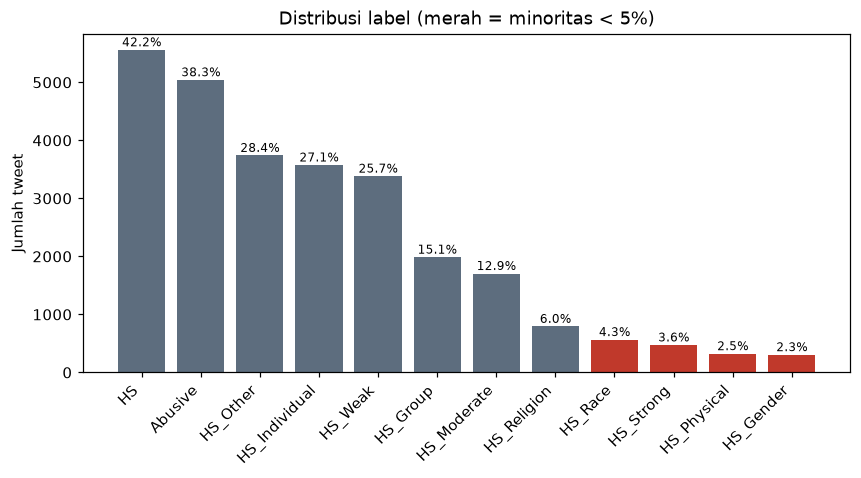

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#c0392b" if m else "#5d6d7e" for m in counts["minoritas_<5%"]]
ax.bar(counts["label"], counts["jumlah"], color=colors)
for i, (n, p) in enumerate(zip(counts["jumlah"], counts["persen"])):
    ax.text(i, n + 60, f"{p:.1f}%", ha="center", fontsize=8)
ax.set_ylabel("Jumlah tweet")
ax.set_title("Distribusi label (merah = minoritas < 5%)")
plt.xticks(rotation=45, ha="right")
fig.savefig(FIG / "eda_label_distribution.png")
plt.show()

### 2.2 Label cardinality, label density, dan kombinasi label

In [17]:
n_per_tweet = Y_raw.sum(axis=1)
card = n_per_tweet.mean()
dens = card / Y_raw.shape[1]
combos = pd.Series(["".join(map(str, r)) for r in Y_raw])
summary = pd.DataFrame({
    "metrik": ["jumlah_tweet", "label_cardinality", "label_density", "jumlah_kombinasi_label_unik",
               "kombinasi_muncul_sekali"],
    "nilai": [len(raw), round(card, 3), round(dens, 3), combos.nunique(),
              int((combos.value_counts() == 1).sum())],
})
summary.to_csv(RES / "eda_multilabel_summary.csv", index=False)
display(summary)
dist = pd.Series(n_per_tweet).value_counts().sort_index().rename_axis("jumlah_label").reset_index(name="jumlah_tweet")
dist.to_csv(RES / "eda_labels_per_tweet.csv", index=False)
dist

,metrik,nilai
0,jumlah_tweet,13169.000
1,label_cardinality,2.085
2,label_density,0.174
3,jumlah_kombinasi_label_unik,57.000
4,kombinasi_muncul_sekali,13.000


,jumlah_label,jumlah_tweet
0,0,5860
1,1,1748
2,4,2208
3,5,3251
4,6,95
5,7,7


### 2.3 Co-occurrence antar label

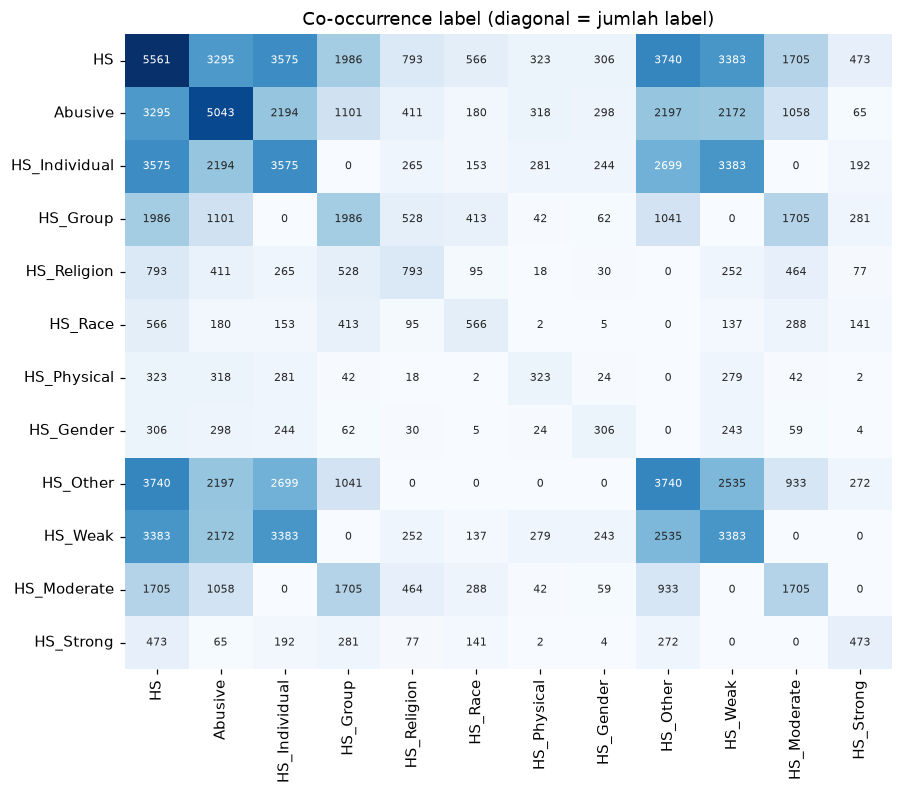

In [18]:
co = pd.DataFrame(Y_raw.T @ Y_raw, index=LABELS, columns=LABELS)
co.to_csv(RES / "eda_cooccurrence.csv")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 7})
ax.set_title("Co-occurrence label (diagonal = jumlah label)")
fig.savefig(FIG / "eda_cooccurrence.png")
plt.show()

### 2.4 Validasi konsistensi hierarki label
Aturan yang dicek: HS=0 berarti semua HS_* = 0. Jika HS=1, harus tepat satu target, tepat satu tingkat, dan minimal satu kategori. HS_Other tidak boleh muncul bersama kategori spesifik.

In [19]:
viol = hierarchy_violations(Y_raw)
pd.Series(viol).to_frame("jumlah_baris").to_csv(RES / "eda_hierarchy_check.csv")
hs = raw[raw.HS == 1]
cat_cols = ["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender", "HS_Other"]
print("Pelanggaran hierarki:", viol)
print("Jumlah kategori per tweet HS:", hs[cat_cols].sum(axis=1).value_counts().sort_index().to_dict())

Pelanggaran hierarki: {'hs0_but_child1': 0, 'hs1_target_not_exactly_one': 0, 'hs1_level_not_exactly_one': 0, 'hs1_no_category': 0, 'other_with_specific': 0, 'any_violation_rows': 0}
Jumlah kategori per tweet HS: {1: 5401, 2: 153, 3: 7}


### 2.5 Panjang tweet (setelah cleaning) per kelas HS

n_char                                              n_word              \
     count   mean   std  min   25%   50%    75%    max   count  mean   std   
HS                                                                           
0   7608.0  107.2  71.3  0.0  48.0  91.0  160.0  283.0  7608.0  17.1  11.2   
1   5561.0   86.8  53.8  0.0  45.0  79.0  115.0  268.0  5561.0  14.3   8.9   

                                
    min  25%   50%   75%   max  
HS                              
0   0.0  8.0  15.0  25.0  54.0  
1   0.0  8.0  13.0  19.0  50.0

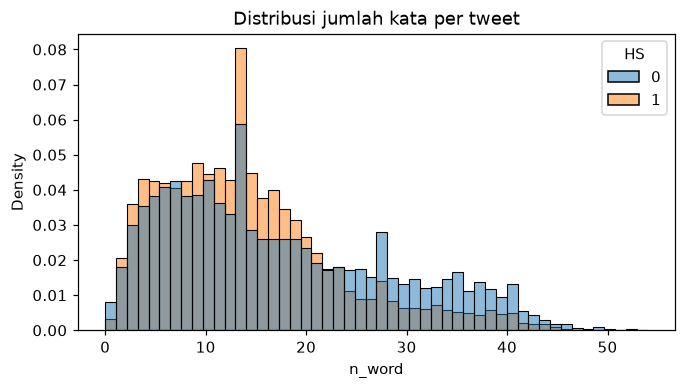

In [20]:
raw["text_clean_tmp"] = raw.Tweet.map(clean_text)
raw["n_char"] = raw.text_clean_tmp.str.len()
raw["n_word"] = raw.text_clean_tmp.str.split().str.len()
length = raw.groupby("HS")[["n_char", "n_word"]].describe().round(1)
length.to_csv(RES / "eda_length_by_hs.csv")
display(length)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=raw, x="n_word", hue="HS", bins=50, stat="density", common_norm=False, ax=ax)
ax.set_title("Distribusi jumlah kata per tweet")
fig.savefig(FIG / "eda_length_hist.png")
plt.show()

## 4. Preprocessing dan deduplikasi

### 3. Preprocessing
Lowercase, hapus token USER/URL/RT, hapus emoji yang tersimpan sebagai teks `\xf0\x9f...`, hapus `\n`, angka, dan tanda baca, lalu rapikan huruf berulang dan normalisasi slang. **Tanpa stemming dan tanpa stopword removal.**

In [21]:
preprocess = build_preprocessor(kamus, use_stemming=False, use_stopwords=False)
raw["text_clean"] = raw.Tweet.map(preprocess)

ex_idx = raw.sample(5, random_state=RANDOM_STATE).index
examples = pd.DataFrame({
    "asli": raw.loc[ex_idx, "Tweet"],
    "setelah_cleaning": raw.loc[ex_idx, "Tweet"].map(clean_text),
    "setelah_normalisasi": raw.loc[ex_idx, "text_clean"],
}).apply(lambda col: col.map(lambda t: mask_abusive(t, abusive_words)))
examples.to_csv(RES / "eda_preprocessing_examples.csv", index=False)
examples

,asli,setelah_cleaning,setelah_normalisasi
4847,Usir Dubes Myanmar dr Negri ini. Ksh peringatan ummat Budha di neg kita agar mrk menghimbau utk menghentikan penyiks...,usir dubes myanmar dr negri ini ksh peringatan ummat budha di neg kita agar mrk menghimbau utk menghentikan penyiksa...,usir duta besar myanmar dari negeri ini kasih peringatan umat buddha di tawar kita agar mereka mengimbau untuk mengh...
6178,"USER Ancaman bom dari mata s****, juga lucu2an ya... ?\n\n#LUCULUCUAN'",ancaman bom dari mata s***t juga lucu lucuan ya luculucuan,ancaman bom dari mata s***t juga lucu lucuan ya lucu lucuan
4894,Pria Belanda Ini Jadi Mualaf Usai Ikuti Perjalanan Islam Nusantara Oleh NU di Eropa,pria belanda ini jadi mualaf usai ikuti perjalanan islam nusantara oleh nu di eropa,pria belanda ini jadi mualaf usai ikuti perjalanan islam nusantara oleh nu di eropa
5790,USER J****k j*****',j****k j****k,j****k j****k
11539,USER Eh nurull kuliah dimana? Jurusan apa? Ha bahasa mandarin? Berarti kerja sama dong sama k*****s ? Wah masih saud...,eh nurull kuliah dimana jurusan apa ha bahasa mandarin berarti kerja sama dong sama k*****s wah masih saudaraan dong...,eh nurul kuliah dimana jurusan apa apa bahasa mandarin berarti kerja sama dong sama k*****s wah masih bersaudara don...


### 3.1 Deduplikasi
Duplikat yang tersebar di fold latih dan uji membuat skor terlalu optimis. Aturan: duplikat dengan label identik disimpan satu, duplikat dengan label berbeda (konflik anotasi) dibuang semua, teks kosong setelah cleaning dibuang. **Angka `rows_final` inilah yang dilaporkan di paper.**

In [22]:
data, dedup_report = deduplicate(raw[["Tweet", "text_clean"] + LABELS])
data.insert(0, "id", np.arange(len(data)))
pd.Series(dedup_report).to_frame("nilai").to_csv(RES / "eda_dedup_report.csv")
display(pd.Series(dedup_report).to_frame("nilai"))
assert hierarchy_violations(label_matrix(data))["any_violation_rows"] == 0

final_counts = pd.DataFrame({"label": LABELS, "jumlah_final": label_matrix(data).sum(axis=0)})
final_counts["persen_final"] = (final_counts.jumlah_final / len(data) * 100).round(2)
final_counts.to_csv(RES / "eda_label_counts_final.csv", index=False)
data.to_csv(PROC / "data_clean.csv", index=False)
print("Disimpan:", PROC / "data_clean.csv", data.shape)
final_counts

,nilai
rows_raw,13169
rows_empty_after_clean,46
conflicting_texts,39
rows_dropped_conflict,84
rows_dropped_same_label_dup,266
rows_final,12773


Disimpan: C:\Users\RXD\Downloads\ML Projek\data\processed\data_clean.csv (12773, 15)


,label,jumlah_final,persen_final
0,HS,5379,42.11
1,Abusive,4864,38.08
2,HS_Individual,3446,26.98
3,HS_Group,1933,15.13
4,HS_Religion,761,5.96
5,HS_Race,552,4.32
6,HS_Physical,305,2.39
7,HS_Gender,294,2.30
8,HS_Other,3625,28.38
9,HS_Weak,3255,25.48


## 5. Pembagian 5 fold (iterative stratification)

### 4. Pembuatan 5 fold (iterative stratification)
`MultilabelStratifiedKFold` (Sechidis dkk., 2011), `shuffle=True`, `random_state=42`. File `results/folds.json` menyimpan **id** baris, bukan posisi, supaya aman walau urutan file berubah.

> Jika `folds.json` sudah ada, sel ini **memuat** file itu dan tidak membuat ulang. Hapus file secara manual hanya jika sudah disepakati tim.

In [23]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

FOLDS_PATH = RES / "folds.json"
Y = label_matrix(data)
ids = data["id"].to_numpy()

if FOLDS_PATH.exists():
    folds = json.loads(FOLDS_PATH.read_text())
    print("folds.json sudah ada, dimuat ulang (tidak dibuat ulang).")
else:
    mskf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    folds = [{"fold": f, "train_ids": ids[tr].tolist(), "test_ids": ids[te].tolist()}
             for f, (tr, te) in enumerate(mskf.split(np.zeros(len(Y)), Y))]
    FOLDS_PATH.write_text(json.dumps(folds))
    print("folds.json dibuat.")

# Validasi: tiap id muncul tepat sekali di test, train dan test tidak beririsan
all_test = np.concatenate([f["test_ids"] for f in folds])
assert len(all_test) == len(set(all_test)) == len(data)
for f in folds:
    assert not set(f["train_ids"]) & set(f["test_ids"])
    assert len(f["train_ids"]) + len(f["test_ids"]) == len(data)
print("Validasi fold OK. Ukuran test per fold:", [len(f["test_ids"]) for f in folds])

folds.json sudah ada, dimuat ulang (tidak dibuat ulang).
Validasi fold OK. Ukuran test per fold: [2555, 2555, 2554, 2555, 2554]


In [24]:
id2row = pd.Series(np.arange(len(data)), index=data["id"])
rows = []
for f in folds:
    te = id2row[f["test_ids"]].to_numpy()
    r = {"fold": f["fold"], "n_test": len(te)}
    r.update({lbl: int(Y[te, j].sum()) for j, lbl in enumerate(LABELS)})
    rows.append(r)
fold_dist = pd.DataFrame(rows).set_index("fold")
fold_dist.to_csv(RES / "folds_label_distribution.csv")
display(fold_dist)
pct = fold_dist[LABELS].div(fold_dist.n_test, axis=0) * 100
print("Selisih maks-min proporsi label antar fold (poin persen):")
(pct.max() - pct.min()).round(2).to_frame("range_pp").T

,n_test,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
fold,,,,,,,,,,,,,
0,2555,1077,973,690,387,152,111,61,59,720,651,333,93
1,2555,1072,972,686,386,152,110,61,59,716,651,328,93
2,2554,1079,973,692,387,153,110,61,59,741,651,334,94
3,2555,1075,973,689,386,152,111,61,59,721,651,331,93
4,2554,1076,973,689,387,152,110,61,58,727,651,331,94


Selisih maks-min proporsi label antar fold (poin persen):


,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
range_pp,0.29,0.05,0.25,0.05,0.04,0.04,0.0,0.04,0.99,0.01,0.24,0.04


## 6. Cek MLSMOTE di data asli (data latih fold 0)
Membandingkan MLSMOTE murni (sesuai paper) dengan MLSMOTE + perbaikan hierarki. TF-IDF dan MLSMOTE hanya di-fit di data latih fold 0.

In [25]:
import time

data = pd.read_csv(PROC / "data_clean.csv", keep_default_na=False)
folds = json.loads((RES / "folds.json").read_text())
id2row = pd.Series(np.arange(len(data)), index=data["id"])
Y = data[LABELS].to_numpy(dtype=int)

f0 = folds[0]
tr = id2row[f0["train_ids"]].to_numpy()

# TF-IDF di-fit HANYA di data latih fold 0
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
X_tr = vec.fit_transform(data.text_clean.iloc[tr])
Y_tr = Y[tr]
print("X_tr:", X_tr.shape)

X_tr: (10218, 5000)


In [26]:
results = {}
for name, repair in [("mlsmote_murni", None), ("mlsmote_repair", repair_labelset)]:
    t0 = time.time()
    sm = MLSMOTE(k=5, threshold="strict", repair_fn=repair, random_state=RANDOM_STATE)
    Xr, Yr = sm.fit_resample(X_tr, Y_tr)
    s = sm.stats_
    syn_viol = hierarchy_violations(Yr[len(tr):])
    results[name] = {"detik": round(time.time() - t0, 2), "n_train_awal": len(tr),
                     "n_sintetis": s["n_synthetic"], "n_diperbaiki": s["n_repaired"],
                     "sintetis_melanggar_hierarki": syn_viol["any_violation_rows"],
                     "label_diproses": ", ".join(LABELS[i] for i in s["processed_labels"])}
    results[name + "_stats"] = s
    results[name + "_Y"] = Yr

summary = pd.DataFrame({k: v for k, v in results.items() if not k.endswith(("_stats", "_Y"))}).T
summary.to_csv(RES / "mlsmote_fold0_summary.csv")
print("MeanIR (fold 0 train):", round(results["mlsmote_murni_stats"]["mean_ir"], 2))
summary

MeanIR (fold 0 train): 6.42


,detik,n_train_awal,n_sintetis,n_diperbaiki,sintetis_melanggar_hierarki,label_diproses
mlsmote_murni,0.37,10218,2063,0,321,"HS_Religion, HS_Race, HS_Physical, HS_Gender, HS_Strong"
mlsmote_repair,0.49,10218,2095,292,0,"HS_Religion, HS_Race, HS_Physical, HS_Gender, HS_Strong"


In [27]:
rows = []
for j, lbl in enumerate(LABELS):
    rows.append({
        "label": lbl,
        "jumlah_awal": int(Y_tr[:, j].sum()),
        "jumlah_murni": int(results["mlsmote_murni_Y"][:, j].sum()),
        "jumlah_repair": int(results["mlsmote_repair_Y"][:, j].sum()),
        "IRLbl_awal": round(results["mlsmote_murni_stats"]["irlbl_before"][j], 2),
        "IRLbl_murni": round(results["mlsmote_murni_stats"]["irlbl_after"][j], 2),
        "IRLbl_repair": round(results["mlsmote_repair_stats"]["irlbl_after"][j], 2),
    })
before_after = pd.DataFrame(rows)
before_after.to_csv(RES / "mlsmote_fold0_label_counts.csv", index=False)
before_after

,label,jumlah_awal,jumlah_murni,jumlah_repair,IRLbl_awal,IRLbl_murni,IRLbl_repair
0,HS,4302,6365,6397,1.00,1.00,1.00
1,Abusive,3891,4802,4802,1.11,1.33,1.33
2,HS_Individual,2756,3516,3606,1.56,1.81,1.77
3,HS_Group,1546,2637,2791,2.78,2.41,2.29
4,HS_Religion,609,1500,1508,7.06,4.24,4.24
5,HS_Race,441,1182,1254,9.76,5.38,5.10
6,HS_Physical,244,542,542,17.63,11.74,11.80
7,HS_Gender,235,490,490,18.31,12.99,13.06
8,HS_Other,2905,3069,3070,1.48,2.07,2.08
9,HS_Weak,2604,3259,3361,1.65,1.95,1.90


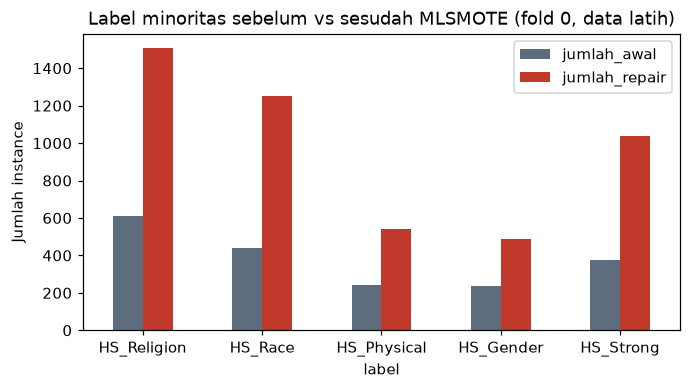

In [28]:
m = before_after.set_index("label")[["jumlah_awal", "jumlah_repair"]]
m = m.loc[["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender", "HS_Strong"]]
ax = m.plot.bar(figsize=(7, 3.5), color=["#5d6d7e", "#c0392b"])
ax.set_title("Label minoritas sebelum vs sesudah MLSMOTE (fold 0, data latih)")
ax.set_ylabel("Jumlah instance")
plt.xticks(rotation=0)
plt.savefig(FIG / "mlsmote_fold0_before_after.png")
plt.show()

### Catatan untuk tim
- Satu kali jalan MLSMOTE (sesuai paper) hanya menambah satu sampel sintetis per instance minoritas per label. Rasio imbalance turun, tetapi label seperti HS_Gender masih minoritas. Ini perilaku algoritma asli, bukan bug.
- Pada versi murni, sebagian sampel sintetis melanggar hierarki label (lihat kolom `sintetis_melanggar_hierarki`). Usulan: grid utama memakai versi **repair**, dan angka pelanggaran versi murni dilaporkan di paper sebagai temuan.
- Hal ini perlu diputuskan tim sebelum grid eksperimen dijalankan.

## 7. Grid eksperimen model klasik

| Faktor | Level |
|---|---|
| Algoritma | Complement NB, LinearSVC, XGBoost, MLP |
| Strategi | BR, CC. LP hanya pembanding baseline (CNB, LinearSVC, Random Forest) |
| Imbalance | `none`, `weight`, `mlsmote` (+ perbaikan hierarki), `mlsmote_raw` (ablation) |
| Tuning | `fixed` dan `tuned` (hyperparameter kecil + ambang per label dari validasi dalam) |
| Validasi | 5-fold iterative stratification, seed 42 |

Total 265 run. Model CPU berjalan paralel, model GPU berjalan berurutan.

In [29]:
ALGOS = ["cnb", "svm"] + (["xgb", "mlp"] if RUN_GPU_MODELS else [])
grid = []
grid += build_grid(ALGOS, ["br", "cc"], ["none", "weight", "mlsmote"], tuned=(False, True))
grid += build_grid(["cnb", "svm", "rf"], ["lp"], ["none"], tuned=(False,))
grid += build_grid(["cnb", "svm"], ["br"], ["mlsmote_raw"], tuned=(False,))
if not RUN_GPU_MODELS:
    print("XGBoost dan MLP dilewati (RUN_GPU_MODELS=False). Hasil yang sudah ada di CSV tetap dipakai.")
print("Jumlah run di grid:", len(grid))
display(pd.DataFrame({k: [v] for k, v in BASE_PARAMS.items()}).T.rename(columns={0: "hyperparameter tetap"}))
pd.Series(TUNING_GRID, name="kandidat tuning").to_frame()

Jumlah run di grid: 265


,hyperparameter tetap
cnb,{'alpha': 1.0}
svm,"{'C': 1.0, 'max_iter': 5000, 'random_state': 42}"
xgb,"{'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.5, 'min_child_we..."
mlp,"{'hidden': 256, 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 1e-05, 'batch_size': 128, 'max_epochs': 30, 'patience':..."
rf,"{'n_estimators': 100, 'random_state': 42, 'n_jobs': -1}"


,kandidat tuning
cnb,"[{'alpha': 0.1}, {'alpha': 0.3}, {'alpha': 1.0}]"
svm,"[{'C': 0.1}, {'C': 0.3}, {'C': 1.0}, {'C': 3.0}]"
xgb,[{}]
mlp,[{}]
rf,[{}]


In [30]:
if RUN_GRID:
    res = run_grid(ROOT, grid, n_jobs_cpu=N_JOBS_CPU, csv_name=RESULTS_CSV, verbose=False)
    print("Baris di", RESULTS_CSV, ":", len(res))

Baris di experiments.csv : 285


## 8. IndoBERTweet (pembanding batas atas)
Fine-tuning `indolem/indobertweet-base-uncased` multi-label dengan fold yang sama. 15% data latih dipakai untuk early stopping dan pemilihan ambang. Satu model menghasilkan dua baris: ambang default (`bert__mo__<kondisi>`) dan ambang hasil tuning (`...__tuned`). Kondisi `weight` = BCE dengan `pos_weight`. Transformer bukan fokus penelitian, perannya untuk memposisikan model ringan. Bagian ini dilewati bila tidak ada GPU.

In [31]:
def set_seed(s=42):
    import torch
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def load_model_and_tokenizer(args, n_labels):
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    for name in (args.model, args.fallback_model):
        try:
            tok = AutoTokenizer.from_pretrained(name)
            model = AutoModelForSequenceClassification.from_pretrained(
                name, num_labels=n_labels, problem_type="multi_label_classification")
            return model, tok, name
        except Exception as e:
            print(f"Gagal memuat {name}: {e!r}", flush=True)
    raise RuntimeError("Tidak ada model yang bisa dimuat")


def auto_batch(dev):
    import torch
    if dev != "cuda":
        return 16
    vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
    return 32 if vram >= 10 else 16 if vram >= 6 else 8


def predict(model, enc, idx, bs, dev):
    import torch
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]
            bt = torch.as_tensor(b)
            batch = {k: v[bt].to(dev) for k, v in enc.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                logits = model(**batch).logits
            out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)


def run_fold(args, data, folds, fold_id, condition, dev, done):
    import torch
    from sklearn.metrics import f1_score
    from torch import nn
    from transformers import get_linear_schedule_with_warmup

    cfg_plain = f"bert__mo__{condition}"
    if (cfg_plain, fold_id) in done and (cfg_plain + "__tuned", fold_id) in done:
        print(f"lewati {cfg_plain} f{fold_id} (sudah ada)", flush=True)
        return
    set_seed(42)
    id2row = pd.Series(np.arange(len(data)), index=data["id"])
    f = folds[fold_id]
    tr = id2row[f["train_ids"]].to_numpy()
    te = id2row[f["test_ids"]].to_numpy()
    Y = data[LABELS].to_numpy(dtype=np.float32)
    i_tr, i_va = inner_split(Y[tr].astype(int))
    tr_in, va_in = tr[i_tr], tr[i_va]

    model, tok, model_name = load_model_and_tokenizer(args, len(LABELS))
    model.to(dev)
    enc = tok(list(data.text_clean), truncation=True, max_length=args.max_len, padding="max_length",
              return_tensors="pt")
    enc = {k: v for k, v in enc.items() if k in ("input_ids", "attention_mask", "token_type_ids")}
    bs = args.batch or auto_batch(dev)
    Yt = torch.from_numpy(Y)

    pw = None
    if condition == "weight":
        pos = Y[tr_in].sum(0).clip(min=1)
        pw = torch.tensor((len(tr_in) - pos) / pos, device=dev)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=0.01)
    steps = math.ceil(len(tr_in) / bs) * args.epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))

    t0 = time.time()
    best_f, best_state, bad = -1, None, 0
    rng = np.random.default_rng(42)
    for ep in range(args.epochs):
        model.train()
        perm = rng.permutation(tr_in)
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            bt = torch.as_tensor(b)
            batch = {k: v[bt].to(dev) for k, v in enc.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), Yt[bt].to(dev))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        pv = predict(model, enc, va_in, bs * 2, dev)
        fv = f1_score(Y[va_in].astype(int), (pv > 0.5).astype(int), average="macro", zero_division=0)
        print(f"  {cfg_plain} f{fold_id} epoch {ep + 1}: val macroF1={fv:.4f} ({(time.time() - t0) / 60:.1f} menit)",
              flush=True)
        if fv > best_f + 1e-4:
            best_f, bad = fv, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad > args.patience - 1:
                break
    model.load_state_dict(best_state)
    train_time = time.time() - t0

    pv = predict(model, enc, va_in, bs * 2, dev) - 0.5
    thr = np.array([best_threshold(Y[va_in, j].astype(int), pv[:, j]) for j in range(len(LABELS))])
    pt = predict(model, enc, te, bs * 2, dev) - 0.5

    out_csv = ROOT / "results" / args.csv
    pdir = ROOT / "results" / "preds"; pdir.mkdir(parents=True, exist_ok=True)
    rows = []
    for tuned, scores in [(False, pt), (True, pt - thr[None, :])]:
        cfg = cfg_plain + ("__tuned" if tuned else "")
        row = {"config": cfg, "algo": "bert", "strategy": "mo", "condition": condition, "tuned": tuned,
               "fold": fold_id, "n_train": len(tr_in), "n_test": len(te), "device": dev,
               "train_time_s": round(train_time, 1), "tune_time_s": 0.0, "total_time_s": round(time.time() - t0, 1),
               "n_synthetic": 0, "n_repaired": 0, "override": json.dumps({"model": model_name, "batch": bs,
                                                                          "epochs_run": ep + 1, "lr": args.lr}),
               "thresholds": json.dumps([round(float(x), 4) for x in thr]) if tuned else "",
               "inner_log": json.dumps({"best_val_macro_f1": round(best_f, 4)})}
        row.update(evaluate(Y[te].astype(int), (scores > 0).astype(int)))
        rows.append(row)
        np.savez_compressed(pdir / f"{cfg}__f{fold_id}.npz",
                            test_ids=np.asarray(data["id"].to_numpy()[te]), scores=scores.astype(np.float32))
    _append(out_csv, rows)
    for r in rows:
        print(f"{r['config']:<26} f{fold_id} macroF1={r['macro_f1']:.4f} minF1={r['minority_macro_f1']:.4f} "
              f"jacc={r['jaccard_acc']:.4f}", flush=True)
    del model
    if dev == "cuda":
        torch.cuda.empty_cache()

In [32]:
BERT_CFG = SimpleNamespace(model=BERT_MODEL, fallback_model=BERT_FALLBACK, max_len=128, epochs=4, lr=2e-5,
                           batch=0, patience=1, csv=RESULTS_CSV)
if RUN_BERT:
    data_b, folds_b = load_inputs(ROOT)
    prev = pd.read_csv(RES / RESULTS_CSV) if (RES / RESULTS_CSV).exists() else pd.DataFrame(columns=["config", "fold"])
    done = set(zip(prev.config, prev.fold))
    for cond in ["none", "weight"]:
        for k in range(5):
            run_fold(BERT_CFG, data_b, folds_b, k, cond, DEVICE, done)
else:
    print("IndoBERTweet dilewati (tidak ada GPU atau RUN_BERT=False).")

lewati bert__mo__none f0 (sudah ada)


lewati bert__mo__none f1 (sudah ada)


lewati bert__mo__none f2 (sudah ada)


lewati bert__mo__none f3 (sudah ada)


lewati bert__mo__none f4 (sudah ada)


lewati bert__mo__weight f0 (sudah ada)


lewati bert__mo__weight f1 (sudah ada)


lewati bert__mo__weight f2 (sudah ada)


lewati bert__mo__weight f3 (sudah ada)


lewati bert__mo__weight f4 (sudah ada)


## 9. Evaluasi dan uji statistik

### Desain uji statistik
- Fold CV tidak independen (data latih tumpang tindih), jadi fold **tidak** dipakai sebagai blok Friedman.
- **RQ2** (imbalance dan tuning ambang): Wilcoxon berpasangan pada F1 per label (12 pasang, rata-rata 5 fold) + corrected resampled t-test (Nadeau & Bengio, 2003) pada macro F1 per fold. Koreksi Holm dalam tiap keluarga uji.
- **RQ3** (antar algoritma): Friedman dengan 12 label sebagai blok, post-hoc Nemenyi, diagram critical difference.
- Keterbatasan: label tidak sepenuhnya independen karena hierarki.

In [33]:
import scikit_posthocs as skp

res = pd.read_csv(RES / "experiments.csv")
incomplete = res.groupby("config").fold.nunique()
incomplete = incomplete[incomplete < 5]
if len(incomplete):
    print("PERINGATAN, konfigurasi belum lengkap 5 fold (diabaikan):", incomplete.to_dict())
    res = res[~res.config.isin(incomplete.index)]
res["tuning"] = np.where(res.tuned, "tuned", "fixed")
F1COLS = [f"f1__{l}" for l in LABELS]
ALGOS = [a for a in ["cnb", "svm", "xgb", "mlp"] if a in res.algo.unique()]
HAS_BERT = "bert" in res.algo.unique()
KEY = ["algo", "strategy", "condition", "tuning"]
print(res.shape, res.config.nunique(), "konfigurasi | IndoBERTweet:", HAS_BERT)

(285, 61) 57 konfigurasi | IndoBERTweet: True


### 1. Tabel utama (rata-rata ± std 5 fold)

In [34]:
metrics = ["macro_f1", "micro_f1", "minority_macro_f1", "jaccard_acc", "hamming_loss", "pred_hierarchy_violation_rate", "total_time_s"]
g = res.groupby(KEY)[metrics]
mean, std = g.mean(), g.std()
main = (mean.round(4).astype(str) + " ± " + std.round(4).astype(str)).reset_index()
main["algo"] = main.algo.map(ALGO_NAME)
main.to_csv(RES / "table_main.csv", index=False)
mean.round(4).to_csv(RES / "table_main_mean.csv"); std.round(4).to_csv(RES / "table_main_std.csv")
top = mean.reset_index().sort_values("macro_f1", ascending=False)
top["algo"] = top.algo.map(ALGO_NAME)
top.head(15).round(4)

,algo,strategy,condition,tuning,macro_f1,micro_f1,minority_macro_f1,jaccard_acc,hamming_loss,pred_hierarchy_violation_rate,total_time_s
3,IndoBERTweet,mo,weight,tuned,0.7332,0.7887,0.6797,0.7810,0.0760,0.1368,256.880
1,IndoBERTweet,mo,none,tuned,0.7037,0.7900,0.5977,0.7955,0.0745,0.1064,257.320
2,IndoBERTweet,mo,weight,fixed,0.6981,0.7686,0.6093,0.7621,0.0888,0.2413,256.860
35,LinearSVC,br,none,tuned,0.6840,0.7456,0.6334,0.7153,0.0918,0.2528,9.146
41,LinearSVC,cc,none,tuned,0.6830,0.7454,0.6379,0.7598,0.0921,0.0258,9.326
43,LinearSVC,cc,weight,tuned,0.6779,0.7458,0.6231,0.7599,0.0921,0.0289,10.030
56,XGBoost,cc,weight,tuned,0.6767,0.7376,0.6352,0.7602,0.0929,0.0211,25.078
39,LinearSVC,cc,mlsmote,tuned,0.6753,0.7415,0.6244,0.7580,0.0920,0.0188,10.756
37,LinearSVC,br,weight,tuned,0.6741,0.7422,0.6109,0.7059,0.0945,0.2745,9.650
32,LinearSVC,br,mlsmote,tuned,0.6729,0.7381,0.6201,0.6986,0.0946,0.2771,10.064


### 2. F1 per label

In [35]:
per_label = res.groupby(KEY)[F1COLS].mean()
per_label.columns = LABELS
per_label.round(4).to_csv(RES / "table_f1_per_label.csv")
best_per_algo = mean.reset_index().sort_values("macro_f1", ascending=False).groupby("algo").head(1)
rows = []
for _, r in best_per_algo.iterrows():
    k = (r.algo, r.strategy, r.condition, r.tuning)
    rows.append(pd.Series(per_label.loc[k], name=f"{ALGO_NAME[r.algo]} | {r.strategy.upper()} | {r.condition} | {r.tuning}"))
best_tbl = pd.DataFrame(rows).round(3)
best_tbl.to_csv(RES / "table_f1_per_label_best_per_algo.csv")
best_tbl

,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
IndoBERTweet | MO | weight | tuned,0.865,0.881,0.755,0.708,0.716,0.752,0.523,0.585,0.798,0.741,0.654,0.822
LinearSVC | BR | none | tuned,0.827,0.885,0.706,0.631,0.641,0.716,0.532,0.509,0.754,0.682,0.556,0.769
XGBoost | CC | weight | tuned,0.812,0.875,0.691,0.617,0.672,0.720,0.507,0.552,0.748,0.670,0.532,0.725
MLP | CC | mlsmote | fixed,0.813,0.851,0.694,0.609,0.616,0.692,0.456,0.394,0.734,0.670,0.530,0.692
Complement NB | BR | weight | tuned,0.807,0.837,0.681,0.585,0.568,0.601,0.382,0.366,0.730,0.656,0.506,0.610
Random Forest | LP | none | fixed,0.675,0.782,0.618,0.430,0.347,0.405,0.324,0.241,0.677,0.594,0.335,0.691


### 3. Grafik

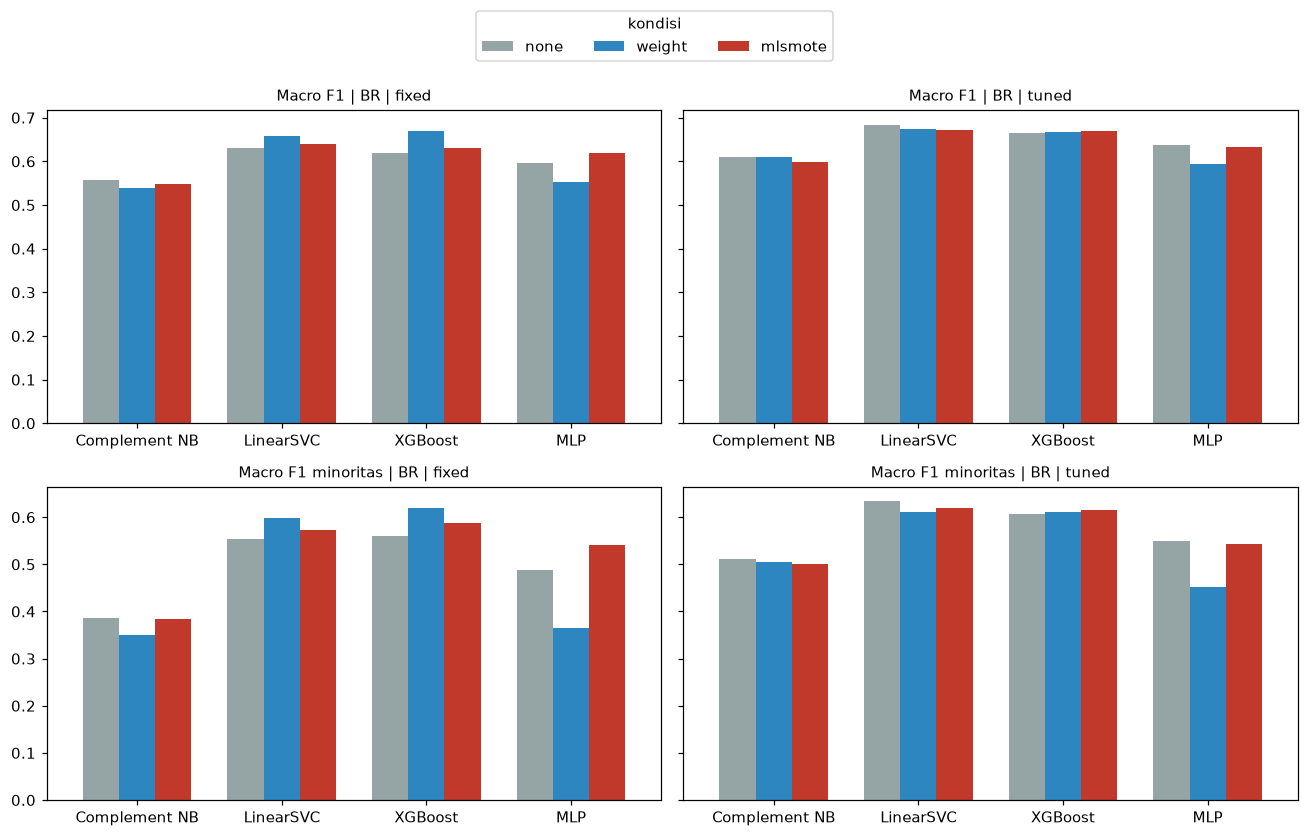

In [36]:
COND = ["none", "weight", "mlsmote"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey="row")
pal = ["#95a5a6", "#2e86c1", "#c0392b"]
for i, metric in enumerate(["macro_f1", "minority_macro_f1"]):
    for j, tun in enumerate(["fixed", "tuned"]):
        ax = axes[i, j]
        sub = mean.reset_index()
        sub = sub[(sub.strategy == "br") & (sub.tuning == tun) & sub.condition.isin(COND)]
        pv = sub.pivot(index="algo", columns="condition", values=metric).reindex(index=ALGOS, columns=COND)
        pv.index = pv.index.map(ALGO_NAME)
        pv.plot.bar(ax=ax, color=pal, width=0.75, legend=False)
        ax.set_title(f"{'Macro F1' if i == 0 else 'Macro F1 minoritas'} | BR | {tun}", fontsize=10)
        ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, title="kondisi", loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.09))
fig.tight_layout()
fig.savefig(FIG / "macro_f1_by_condition.png")
plt.show()

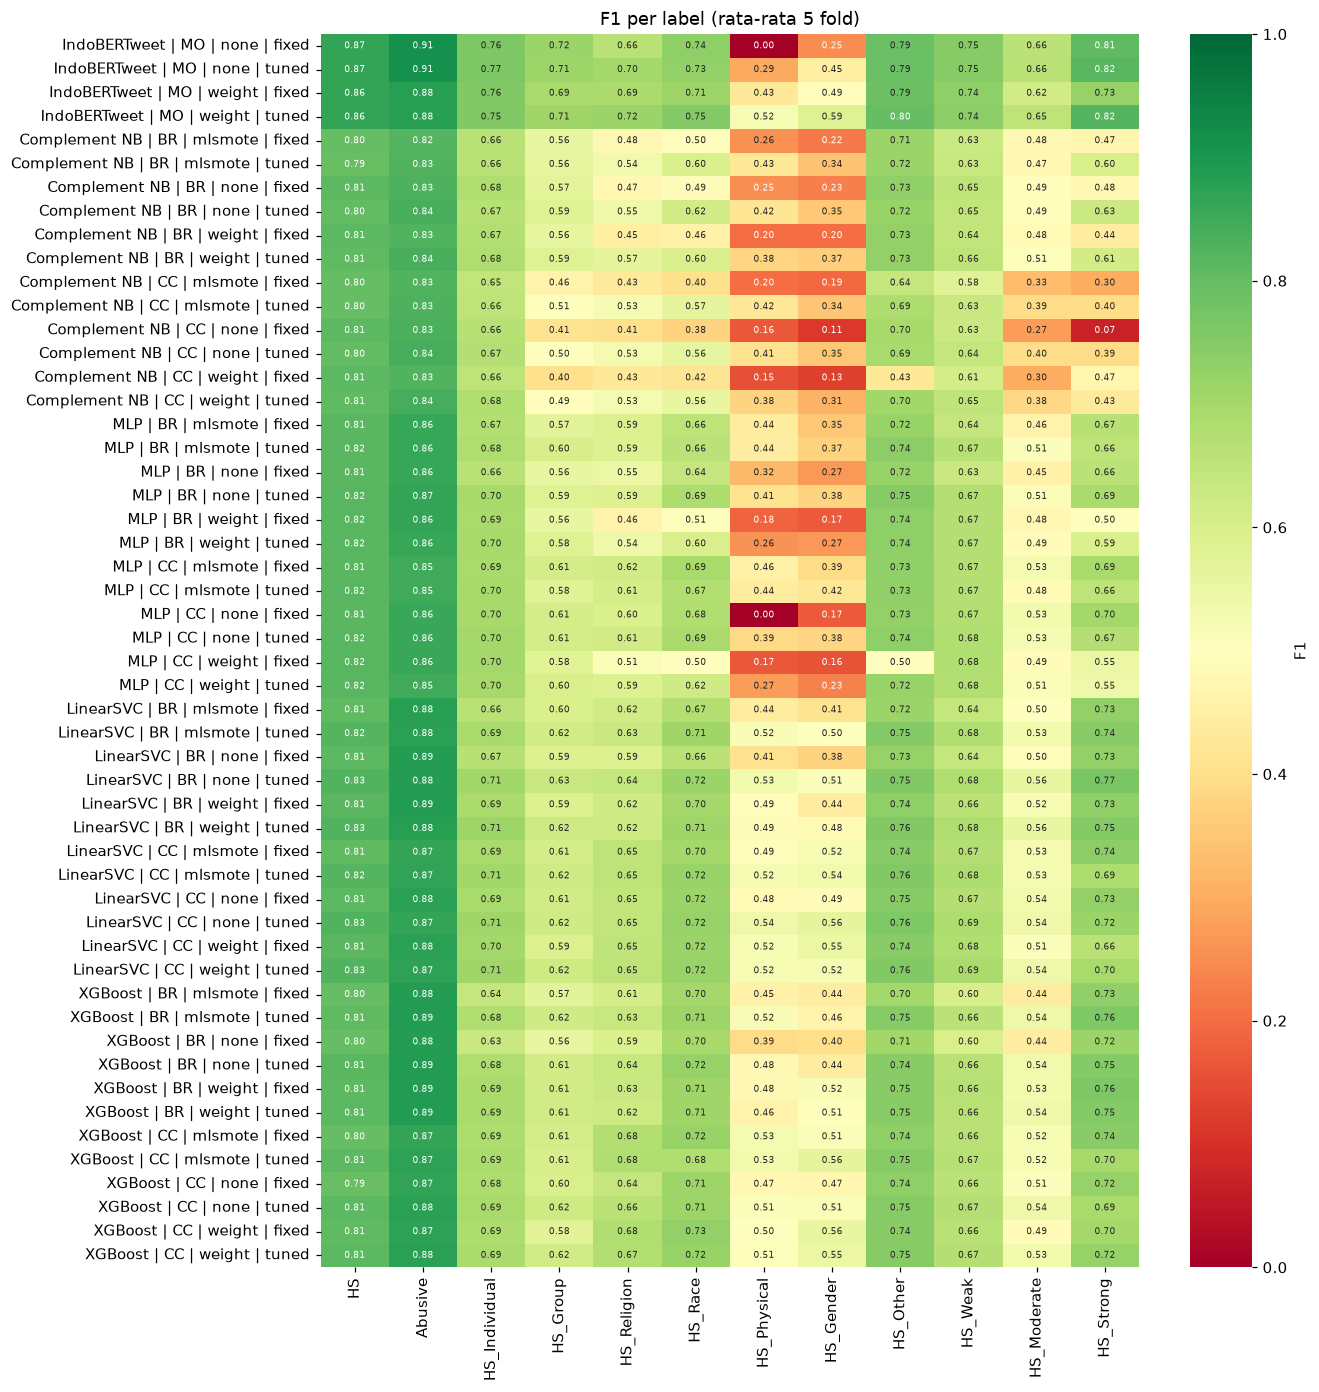

In [37]:
hm = per_label.reset_index()
hm = hm[hm.strategy.isin(["br", "cc", "mo"]) & hm.condition.isin(COND)]
hm.index = [f"{ALGO_NAME[a]} | {s.upper()} | {c} | {t}" for a, s, c, t in zip(hm.algo, hm.strategy, hm.condition, hm.tuning)]
hm = hm[LABELS]
fig, ax = plt.subplots(figsize=(12, max(6, 0.28 * len(hm))))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "F1"}, ax=ax, annot_kws={"size": 6})
ax.set_title("F1 per label (rata-rata 5 fold)")
fig.savefig(FIG / "heatmap_f1_per_label.png")
plt.show()

### 4. RQ2: penanganan imbalance dan tuning ambang
Perbandingan berpasangan dalam algoritma dan strategi yang sama:
- `none` vs `weight`, `none` vs `mlsmote`, `weight` vs `mlsmote` (semua `fixed`)
- `fixed` vs `tuned` pada tiap kondisi (efek tuning ambang dan hyperparameter)

In [38]:
n_tr = int(res.n_train[(res.condition == "none")].mean()); n_te = int(res.n_test.mean())

def fold_scores(a, s, c, t):
    r = res[(res.algo == a) & (res.strategy == s) & (res.condition == c) & (res.tuning == t)].sort_values("fold")
    return r.macro_f1.to_numpy()

def compare(a, s, A, B, family):
    PA, PB = per_label.loc[(a, s, *A)].to_numpy(), per_label.loc[(a, s, *B)].to_numpy()
    mi = [LABELS.index(l) for l in MINORITY]
    return {"family": family, "algo": ALGO_NAME[a], "strategy": s.upper(), "A": "/".join(A), "B": "/".join(B),
            "macroF1_A": PA.mean(), "macroF1_B": PB.mean(), "delta_macroF1": PB.mean() - PA.mean(),
            "delta_minorityF1": PB[mi].mean() - PA[mi].mean(), "label_naik": int((PB > PA).sum()),
            "wilcoxon_p": wilcoxon_paired(PB, PA)["p"],
            "ttest_corr_p": corrected_resampled_ttest(fold_scores(a, s, *B), fold_scores(a, s, *A), n_tr, n_te)["p"]}

rows = []
for a in ALGOS:
    for s in ["br", "cc"]:
        pairs = [((A, "fixed"), (B, "fixed"), "imbalance") for A, B in [("none", "weight"), ("none", "mlsmote"), ("weight", "mlsmote")]]
        pairs += [((c, "fixed"), (c, "tuned"), "tuning") for c in ["none", "weight", "mlsmote"]]
        for A, B, fam in pairs:
            if (a, s, *A) in per_label.index and (a, s, *B) in per_label.index:   # lewati yang belum lengkap
                rows.append(compare(a, s, A, B, fam))
rq2 = pd.DataFrame(rows)
for fam in rq2.family.unique():
    m = rq2.family == fam
    rq2.loc[m, "wilcoxon_p_holm"] = holm(rq2.loc[m, "wilcoxon_p"].to_numpy())
    rq2.loc[m, "ttest_corr_p_holm"] = holm(rq2.loc[m, "ttest_corr_p"].to_numpy())
rq2.round(4).to_csv(RES / "stats_rq2.csv", index=False)
rq2.round(4)

,family,algo,strategy,A,B,macroF1_A,macroF1_B,delta_macroF1,delta_minorityF1,label_naik,wilcoxon_p,ttest_corr_p,wilcoxon_p_holm,ttest_corr_p_holm
0,imbalance,Complement NB,BR,none/fixed,weight/fixed,0.5585,0.5399,-0.0185,-0.0353,0,0.0005,0.0288,0.0117,0.3452
1,imbalance,Complement NB,BR,none/fixed,mlsmote/fixed,0.5585,0.5482,-0.0103,-0.0018,3,0.0068,0.0498,0.1230,0.3973
2,imbalance,Complement NB,BR,weight/fixed,mlsmote/fixed,0.5399,0.5482,0.0083,0.0335,5,0.4238,0.0225,1.0000,0.3156
3,tuning,Complement NB,BR,none/fixed,none/tuned,0.5585,0.6095,0.0510,0.1268,8,0.1099,0.0002,0.6592,0.0046
4,tuning,Complement NB,BR,weight/fixed,weight/tuned,0.5399,0.6108,0.0709,0.1552,11,0.0015,0.0005,0.0264,0.0087
5,tuning,Complement NB,BR,mlsmote/fixed,mlsmote/tuned,0.5482,0.5981,0.0499,0.1175,10,0.0161,0.0003,0.2095,0.0062
6,imbalance,Complement NB,CC,none/fixed,weight/fixed,0.4543,0.4687,0.0144,0.0924,5,0.7334,0.0226,1.0000,0.3156
7,imbalance,Complement NB,CC,none/fixed,mlsmote/fixed,0.4543,0.4850,0.0307,0.0789,7,0.2036,0.0048,1.0000,0.0906
8,imbalance,Complement NB,CC,weight/fixed,mlsmote/fixed,0.4687,0.4850,0.0163,-0.0134,7,0.4697,0.0193,1.0000,0.2899
9,tuning,Complement NB,CC,none/fixed,none/tuned,0.4543,0.5658,0.1115,0.2218,10,0.0049,0.0003,0.0830,0.0057


### 5. RQ3: perbedaan antar algoritma
Friedman (12 label sebagai blok) membandingkan algoritma pada strategi, kondisi, dan tuning yang sama. Ditambah satu perbandingan "konfigurasi terbaik tiap algoritma" (dipilih berdasarkan macro F1 rata-rata, termasuk IndoBERTweet bila ada). Perbandingan terakhir ini bersifat deskriptif karena konfigurasinya dipilih dari hasil yang sama.

In [39]:
PALETTE = {"Complement NB": "#7f8c8d", "LinearSVC": "#2e86c1", "XGBoost": "#c0392b", "MLP": "#27ae60", "IndoBERTweet": "#8e44ad"}
fr_rows, panels = [], []
for s in ["br", "cc"]:
    for c in ["none", "weight", "mlsmote"]:
        for t in ["fixed", "tuned"]:
            avail = [a for a in ALGOS if (a, s, c, t) in per_label.index]
            if len(avail) < 3:
                continue          # Friedman butuh minimal 3 algoritma
            M = pd.DataFrame({ALGO_NAME[a]: per_label.loc[(a, s, c, t)].to_numpy() for a in avail}, index=LABELS)
            out = friedman_nemenyi(M)
            fr_rows.append({"strategy": s.upper(), "condition": c, "tuning": t, "friedman_chi2": out["chi2"], "friedman_p": out["p"],
                            **{f"avg_rank_{k}": v for k, v in out["avg_rank"].items()}})
            out["nemenyi"].round(4).to_csv(RES / f"stats_rq3_nemenyi_{s}_{c}_{t}.csv")
fr = pd.DataFrame(fr_rows)
if len(fr):
    fr["friedman_p_holm"] = holm(fr.friedman_p.to_numpy())
fr.round(4).to_csv(RES / "stats_rq3_friedman.csv", index=False)

# konfigurasi terbaik tiap algoritma (+ IndoBERTweet)
best_cfg = {}
for a in ALGOS + (["bert"] if HAS_BERT else []):
    r = mean.reset_index(); r = r[r.algo == a].sort_values("macro_f1", ascending=False).iloc[0]
    best_cfg[ALGO_NAME[a]] = (a, r.strategy, r.condition, r.tuning)
Mb = pd.DataFrame({k: per_label.loc[v].to_numpy() for k, v in best_cfg.items()}, index=LABELS)
print("Konfigurasi terbaik tiap algoritma:", best_cfg)
if Mb.shape[1] >= 3:
    ob = friedman_nemenyi(Mb)
    ob["nemenyi"].round(4).to_csv(RES / "stats_rq3_nemenyi_best_per_algo.csv")
    print(f"Friedman (terbaik tiap algoritma): chi2={ob['chi2']:.2f}, p={ob['p']:.4g}")
fr.round(4)

Konfigurasi terbaik tiap algoritma: {'Complement NB': ('cnb', 'br', 'weight', 'tuned'), 'LinearSVC': ('svm', 'br', 'none', 'tuned'), 'XGBoost': ('xgb', 'cc', 'weight', 'tuned'), 'MLP': ('mlp', 'cc', 'mlsmote', 'fixed'), 'IndoBERTweet': ('bert', 'mo', 'weight', 'tuned')}
Friedman (terbaik tiap algoritma): chi2=42.07, p=1.616e-08


,strategy,condition,tuning,friedman_chi2,friedman_p,avg_rank_Complement NB,avg_rank_LinearSVC,avg_rank_XGBoost,avg_rank_MLP,friedman_p_holm
0,BR,none,fixed,6.7,0.0821,2.7500,1.6667,2.7500,2.8333,0.0821
1,BR,none,tuned,28.5,0.0000,3.9167,1.1667,2.1667,2.7500,0.0000
2,BR,weight,fixed,16.2,0.0010,3.5833,2.0833,1.5833,2.7500,0.0031
3,BR,weight,tuned,23.3,0.0000,3.4167,1.3333,1.9167,3.3333,0.0002
4,BR,mlsmote,fixed,11.7,0.0085,3.5000,1.7500,2.5000,2.2500,0.0170
5,BR,mlsmote,tuned,27.7,0.0000,4.0000,1.5833,1.6667,2.7500,0.0000
6,CC,none,fixed,21.1,0.0001,3.7500,1.3333,2.5000,2.4167,0.0005
7,CC,none,tuned,28.3,0.0000,3.9167,1.2500,2.0000,2.8333,0.0000
8,CC,weight,fixed,21.8,0.0001,3.9167,1.5833,2.0833,2.4167,0.0004
9,CC,weight,tuned,25.7,0.0000,3.8333,1.4167,1.8333,2.9167,0.0001


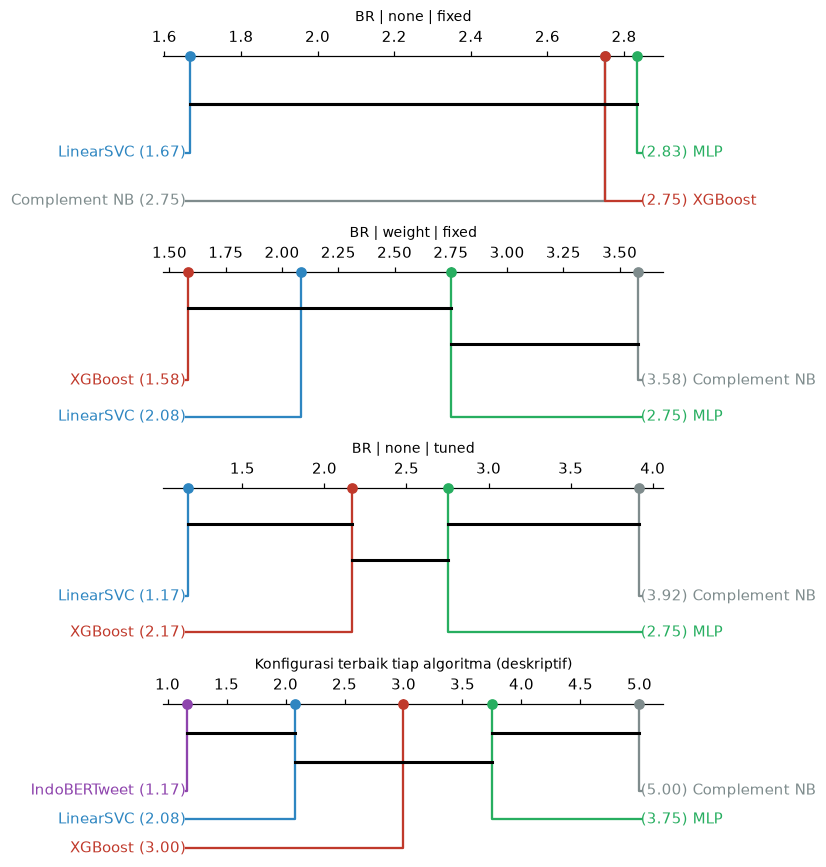

In [40]:
def cd_plot(ax, M, title):
    ranks = M.rank(axis=1, ascending=False).mean()
    nem = skp.posthoc_nemenyi_friedman(M.to_numpy()); nem.index = nem.columns = M.columns
    plt.sca(ax)
    skp.critical_difference_diagram(ranks, nem, ax=ax, color_palette={k: PALETTE[k] for k in M.columns},
                                    label_fmt_left="{label} ({rank:.2f})", label_fmt_right="({rank:.2f}) {label}")
    ax.set_title(title, fontsize=9)

panels = []
for c, t in [("none", "fixed"), ("weight", "fixed"), ("none", "tuned")]:
    avail = [a for a in ALGOS if (a, "br", c, t) in per_label.index]
    if len(avail) >= 3:
        panels.append((pd.DataFrame({ALGO_NAME[a]: per_label.loc[(a, "br", c, t)].to_numpy() for a in avail}, index=LABELS),
                       f"BR | {c} | {t}"))
if Mb.shape[1] >= 3:
    panels.append((Mb, "Konfigurasi terbaik tiap algoritma (deskriptif)"))
if panels:
    fig, axes = plt.subplots(len(panels), 1, figsize=(7.5, 2 * len(panels)), squeeze=False)
    for ax, (M, title) in zip(axes[:, 0], panels):
        cd_plot(ax, M, title)
    plt.tight_layout()
    fig.savefig(FIG / "cd_diagram.png")
    plt.show()

### 6. Perbandingan dengan baseline Ibrohim & Budi (2019)
Baseline: RFDT + LP + word unigram, **akurasi 66,12%** (12 label, 10-fold). Akurasi di paper itu = akurasi Jaccard per dokumen (Persamaan 1). Perbedaan setup yang wajib disebut: 5-fold, data dideduplikasi, TF-IDF 1-2 gram.

In [41]:
b = mean.reset_index()
lp = b[b.strategy == "lp"][["algo", "jaccard_acc", "macro_f1", "minority_macro_f1"]].copy()
lp["algo"] = lp.algo.map(ALGO_NAME)
lp["selisih_vs_66.12_pp"] = (lp.jaccard_acc * 100 - 66.12).round(2)
best_j = b.sort_values("jaccard_acc", ascending=False).head(8)[KEY + ["jaccard_acc", "macro_f1"]]
best_j["algo"] = best_j.algo.map(ALGO_NAME)
lp.round(4).to_csv(RES / "table_baseline_lp.csv", index=False)
best_j.round(4).to_csv(RES / "table_best_jaccard.csv", index=False)
display(lp.round(4)); best_j.round(4)

,algo,jaccard_acc,macro_f1,minority_macro_f1,selisih_vs_66.12_pp
17,Complement NB,0.7198,0.5778,0.4693,5.86
30,Random Forest,0.7065,0.5099,0.4017,4.53
44,LinearSVC,0.7496,0.6192,0.5429,8.84


,algo,strategy,condition,tuning,jaccard_acc,macro_f1
0,IndoBERTweet,mo,none,fixed,0.7989,0.6590
1,IndoBERTweet,mo,none,tuned,0.7955,0.7037
3,IndoBERTweet,mo,weight,tuned,0.7810,0.7332
53,XGBoost,cc,none,fixed,0.7649,0.6562
51,XGBoost,cc,mlsmote,fixed,0.7631,0.6713
40,LinearSVC,cc,none,fixed,0.7623,0.6676
2,IndoBERTweet,mo,weight,fixed,0.7621,0.6981
55,XGBoost,cc,weight,fixed,0.7610,0.6666


### 7. Waktu komputasi, device, dan konsistensi hierarki prediksi

In [42]:
tt = res.groupby(KEY + ["device"])[["train_time_s", "tune_time_s", "total_time_s", "pred_hierarchy_violation_rate"]].mean().round(3)
tt.to_csv(RES / "table_time_violation.csv")
tt

train_time_s  tune_time_s  \
algo strategy condition   tuning device                              
bert mo       none        fixed  cuda         250.920        0.000   
                          tuned  cuda         250.920        0.000   
              weight      fixed  cuda         250.480        0.000   
                          tuned  cuda         250.480        0.000   
cnb  br       mlsmote     fixed  cpu            0.030        0.000   
                          tuned  cpu            0.028        6.228   
              mlsmote_raw fixed  cpu            0.032        0.000   
              none        fixed  cpu            0.024        0.000   
                          tuned  cpu            0.020        5.644   
              weight      fixed  cpu            0.042        0.000   
                          tuned  cpu            0.038        5.888   
     cc       mlsmote     fixed  cpu            0.070        0.000   
                          tuned  cpu            0.074        6.420   
              none        fixed  cpu            0.062        0.000   
                          tuned  cpu            0.054        6.140   
              weight      fixed  cpu            0.074        0.000   
                          tuned  cpu            0.066        5.902   
     lp       none        fixed  cpu            0.038        0.000   
mlp  br       mlsmote     fixed  cuda          33.496        0.000   
                          tuned  cuda          46.800       41.996   
              none        fixed  cuda          29.300        0.000   
                          tuned  cuda          26.458       26.882   
              weight      fixed  cuda          19.350        0.000   
                          tuned  cuda          17.684       19.212   
     cc       mlsmote     fixed  cuda          57.172        0.000   
                          tuned  cuda          60.386       57.818   
              none        fixed  cuda          57.214        0.000   
                          tuned  cuda          49.672       50.070   
              weight      fixed  cuda          41.140        0.000   
                          tuned  cuda          41.368       39.096   
rf   lp       none        fixed  cpu            2.112        0.000   
svm  br       mlsmote     fixed  cpu            0.388        0.000   
                          tuned  cpu            0.266        8.500   
              mlsmote_raw fixed  cpu            0.374        0.000   
              none        fixed  cpu            0.262        0.000   
                          tuned  cpu            0.228        8.022   
              weight      fixed  cpu            0.398        0.000   
                          tuned  cpu            0.246        8.524   
     cc       mlsmote     fixed  cpu            0.436        0.000   
                          tuned  cpu            0.380        9.026   
              none        fixed  cpu            0.310        0.000   
                          tuned  cpu            0.266        8.162   
              weight      fixed  cpu            0.438        0.000   
                          tuned  cpu            0.350        8.810   
     lp       none        fixed  cpu            1.044        0.000   
xgb  br       mlsmote     fixed  cuda          14.108        0.000   
                          tuned  cuda          14.350       17.420   
              none        fixed  cuda          12.086        0.000   
                          tuned  cuda          12.038       13.726   
              weight      fixed  cuda          13.502        0.000   
                          tuned  cuda          13.598       15.132   
     cc       mlsmote     fixed  cuda          11.870        0.000   
                          tuned  cuda          12.482       13.914   
              none        fixed  cuda          10.400        0.000   
                          tuned  cuda          10.516       12.204   
              weight      fixed  cuda          11.1

### 8. Ablation: MLSMOTE murni vs dengan perbaikan hierarki

In [43]:
abl = res[(res.strategy == "br") & (res.tuning == "fixed") & res.condition.isin(["mlsmote", "mlsmote_raw"]) & res.algo.isin(["cnb", "svm"])]
abl = abl.groupby(["algo", "condition"])[["macro_f1", "minority_macro_f1", "jaccard_acc", "pred_hierarchy_violation_rate", "n_synthetic", "n_repaired"]].mean().round(4)
abl.to_csv(RES / "table_ablation_repair.csv")
abl

macro_f1  minority_macro_f1  jaccard_acc  \
algo condition                                               
cnb  mlsmote        0.5482             0.3838       0.5662   
     mlsmote_raw    0.5479             0.3858       0.5646   
svm  mlsmote        0.6398             0.5735       0.7115   
     mlsmote_raw    0.6367             0.5713       0.7108   

                  pred_hierarchy_violation_rate  n_synthetic  n_repaired  
algo condition                                                            
cnb  mlsmote                             0.4452       2108.8       335.0  
     mlsmote_raw                         0.4416       2072.2         0.0  
svm  mlsmote                             0.2582       2108.8       335.0  
     mlsmote_raw                         0.2620       2072.2         0.0

### 9. Ringkasan otomatis (poin, BUKAN paragraf paper)

In [44]:
t = mean.reset_index()
for metric in ["macro_f1", "minority_macro_f1", "jaccard_acc"]:
    r = t.sort_values(metric, ascending=False).iloc[0]
    print(f"- {metric} tertinggi: {ALGO_NAME[r.algo]} {r.strategy.upper()} {r.condition} {r.tuning} = {r[metric]:.4f}")
light = t[t.algo != "bert"].sort_values("macro_f1", ascending=False).iloc[0]
print(f"- Model ringan terbaik: {ALGO_NAME[light.algo]} {light.strategy.upper()} {light.condition} {light.tuning} = {light.macro_f1:.4f}")
for _, r in rq2.iterrows():
    sig = "SIGNIFIKAN" if r.wilcoxon_p_holm < 0.05 else "tidak sig."
    print(f"- [{r.family}] {r.algo} {r.strategy}: {r.A} -> {r.B}: dMacro {r.delta_macroF1:+.4f}, dMinor {r.delta_minorityF1:+.4f}, "
          f"naik {r.label_naik}/12, Wilcoxon-Holm p={r.wilcoxon_p_holm:.3f} ({sig})")

- macro_f1 tertinggi: IndoBERTweet MO weight tuned = 0.7332
- minority_macro_f1 tertinggi: IndoBERTweet MO weight tuned = 0.6797
- jaccard_acc tertinggi: IndoBERTweet MO none fixed = 0.7989
- Model ringan terbaik: LinearSVC BR none tuned = 0.6840
- [imbalance] Complement NB BR: none/fixed -> weight/fixed: dMacro -0.0185, dMinor -0.0353, naik 0/12, Wilcoxon-Holm p=0.012 (SIGNIFIKAN)
- [imbalance] Complement NB BR: none/fixed -> mlsmote/fixed: dMacro -0.0103, dMinor -0.0018, naik 3/12, Wilcoxon-Holm p=0.123 (tidak sig.)
- [imbalance] Complement NB BR: weight/fixed -> mlsmote/fixed: dMacro +0.0083, dMinor +0.0335, naik 5/12, Wilcoxon-Holm p=1.000 (tidak sig.)
- [tuning] Complement NB BR: none/fixed -> none/tuned: dMacro +0.0510, dMinor +0.1268, naik 8/12, Wilcoxon-Holm p=0.659 (tidak sig.)
- [tuning] Complement NB BR: weight/fixed -> weight/tuned: dMacro +0.0709, dMinor +0.1552, naik 11/12, Wilcoxon-Holm p=0.026 (SIGNIFIKAN)
- [tuning] Complement NB BR: mlsmote/fixed -> mlsmote/tuned: dMa

### Perbandingan langsung: model ringan terbaik vs IndoBERTweet
Uji berpasangan antara dua konfigurasi terbaik (dipilih berdasarkan macro F1 rata-rata): Wilcoxon pada F1 per label dan corrected resampled t-test pada macro F1 per fold. Karena konfigurasinya dipilih dari hasil yang sama, uji ini bersifat konfirmatif lemah dan dilaporkan sebagai pelengkap Nemenyi (yang lebih konservatif karena membandingkan 5 metode sekaligus).

In [45]:
if HAS_BERT:
    t = mean.reset_index()
    light = t[t.algo != "bert"].sort_values("macro_f1", ascending=False).iloc[0]
    bert = t[t.algo == "bert"].sort_values("macro_f1", ascending=False).iloc[0]
    kl, kb = (light.algo, light.strategy, light.condition, light.tuning), (bert.algo, bert.strategy, bert.condition, bert.tuning)
    PL, PB = per_label.loc[kl].to_numpy(), per_label.loc[kb].to_numpy()
    fl = fold_scores(*kl); fb = fold_scores(*kb)
    duel = pd.DataFrame([{
        "model_ringan": " | ".join(map(str, kl)), "indobertweet": " | ".join(map(str, kb)),
        "macroF1_ringan": PL.mean(), "macroF1_bert": PB.mean(), "selisih": PB.mean() - PL.mean(),
        "label_bert_lebih_baik": int((PB > PL).sum()), "wilcoxon_p": wilcoxon_paired(PB, PL)["p"],
        "ttest_corr_p": corrected_resampled_ttest(fb, fl, n_tr, n_te)["p"],
        "waktu_latih_ringan_s": res[res.config == f"{kl[0]}__{kl[1]}__{kl[2]}" + ("__tuned" if kl[3] == "tuned" else "")].train_time_s.mean(),
        "waktu_latih_bert_s": res[res.config == f"{kb[0]}__{kb[1]}__{kb[2]}" + ("__tuned" if kb[3] == "tuned" else "")].train_time_s.mean()}])
    duel.round(4).to_csv(RES / "stats_light_vs_bert.csv", index=False)
    display(duel.round(4).T)
else:
    print("IndoBERTweet belum ada di hasil.")

,0
model_ringan,svm | br | none | tuned
indobertweet,bert | mo | weight | tuned
macroF1_ringan,0.684
macroF1_bert,0.7332
selisih,0.0492
label_bert_lebih_baik,10
wilcoxon_p,0.0024
ttest_corr_p,0.0016
waktu_latih_ringan_s,0.228
waktu_latih_bert_s,250.48


## 10. Explainability dan analisis kesalahan
Kata pemicu LinearSVC untuk label minoritas dan contoh false negative out-of-fold. Kolom `penyebab` di file hasil diisi manual oleh tim. Kata kasar disamarkan.

In [46]:
res = pd.read_csv(RES / "experiments.csv")
svm_br = res[(res.algo == "svm") & (res.strategy == "br")].groupby("config").macro_f1.mean().sort_values(ascending=False)
CFG = svm_br.index[0]                     # konfigurasi LinearSVC BR terbaik
CONDITION = CFG.split("__")[2]
print("Konfigurasi dipakai:", CFG)

data = pd.read_csv(PROC / "data_clean.csv", keep_default_na=False)
folds = json.loads((RES / "folds.json").read_text())
abusive_words = load_abusive(RAW / "abusive.csv")
id2row = pd.Series(np.arange(len(data)), index=data["id"])
Y = data[LABELS].to_numpy(dtype=int)

Konfigurasi dipakai: svm__br__none__tuned


### 1. Kata pemicu (koefisien LinearSVC, dilatih di data latih fold 0)

In [47]:
tr = id2row[folds[0]["train_ids"]].to_numpy()
vec = TfidfVectorizer(**TFIDF_PARAMS)
X_tr = vec.fit_transform(data.text_clean.iloc[tr]); Y_tr = Y[tr]
if CONDITION.startswith("mlsmote"):
    X_tr, Y_tr = MLSMOTE(repair_fn=repair_labelset if CONDITION == "mlsmote" else None, random_state=RANDOM_STATE).fit_resample(X_tr, Y_tr)
br = BinaryRelevance("svm", weight=(CONDITION == "weight")).fit(X_tr, Y_tr)
vocab = np.array(vec.get_feature_names_out())
tables = {}
for lbl in MINORITY:
    coef = br.models_[LABELS.index(lbl)].coef_.ravel()
    top = np.argsort(coef)[::-1][:20]
    tables[lbl] = [f"{mask_abusive(vocab[i], abusive_words)} ({coef[i]:.2f})" for i in top]
top_feats = pd.DataFrame(tables)
top_feats.to_csv(RES / "explain_top_features_svm.csv", index=False)
top_feats

,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Strong
0,k***r (3.80),cina (3.94),p***k (3.82),b***i (3.36),bubarkan (4.31)
1,islam (2.77),k*****s (3.78),b***k (2.66),h**o (3.11),lengserkan (3.86)
2,buddha (2.41),myanmar (2.34),i***t (2.64),p***n (2.18),usir (3.66)
3,anti (1.93),usir (2.00),muka (2.39),cabul (2.09),hancurkan (2.15)
4,muslim (1.91),a***g cina (1.94),bolot (2.29),b*****g (2.01),ganyang (2.11)
5,abu janda (1.77),r***m k*****s (1.75),wajahnya (1.77),mesum (1.81),lengserkan jokowi (2.08)
6,mengaji (1.73),indonesia (1.56),mukanya (1.73),p***k (1.62),bubarkan saja (1.98)
7,isis (1.70),batak (1.54),tampang (1.71),j****y (1.46),turunkan (1.82)
8,zionis (1.68),ganyang (1.52),c***t (1.62),muka (1.44),tangkap (1.73)
9,usir (1.64),buddha myanmar (1.50),c****r (1.56),puasa (1.34),ganyang partai (1.67)


### 2. Analisis false negative (prediksi out-of-fold dari konfigurasi di atas)

In [48]:
scores = np.zeros_like(Y, dtype=float)
for k in range(5):
    z = np.load(RES / "preds" / f"{CFG}__f{k}.npz")
    scores[id2row[z["test_ids"]].to_numpy()] = z["scores"]
pred = (scores > 0).astype(int)

rows, rng = [], np.random.default_rng(RANDOM_STATE)
for lbl in MINORITY:
    j = LABELS.index(lbl)
    fn = np.where((Y[:, j] == 1) & (pred[:, j] == 0))[0]
    for i in rng.choice(fn, size=min(10, len(fn)), replace=False):
        rows.append({"label": lbl, "id": int(data.id.iloc[i]), "skor": round(scores[i, j], 3),
                     "label_asli": ", ".join(l for l, v in zip(LABELS, Y[i]) if v),
                     "label_prediksi": ", ".join(l for l, v in zip(LABELS, pred[i]) if v) or "-",
                     "tweet_disamarkan": mask_abusive(data.Tweet.iloc[i], abusive_words), "penyebab": ""})
fn_df = pd.DataFrame(rows)
fn_df.to_csv(RES / "error_analysis_false_negatives.csv", index=False)
counts = pd.DataFrame({lbl: {"positif": int(Y[:, LABELS.index(lbl)].sum()),
                             "false_negative": int(((Y[:, LABELS.index(lbl)] == 1) & (pred[:, LABELS.index(lbl)] == 0)).sum()),
                             "false_positive": int(((Y[:, LABELS.index(lbl)] == 0) & (pred[:, LABELS.index(lbl)] == 1)).sum())}
                       for lbl in MINORITY}).T
counts.to_csv(RES / "error_analysis_counts.csv")
display(counts); fn_df.head(10)

,positif,false_negative,false_positive
HS_Religion,761,249,326
HS_Race,552,146,176
HS_Physical,305,130,184
HS_Gender,294,124,210
HS_Strong,467,96,128


,label,id,skor,label_asli,label_prediksi,tweet_disamarkan,penyebab
0,HS_Religion,12502,-0.649,"HS, HS_Individual, HS_Religion, HS_Weak","HS_Individual, HS_Other, HS_Weak",Sejak kepemimpinan jokowi banyak ormas yg tidak akur rakyat juga saling hujat dan menista agama di sosmed,
1,HS_Religion,9694,-0.691,"HS, Abusive, HS_Individual, HS_Religion, HS_Weak",-,aku sendiri akui Jesus Kristus tapi aku tidak suka caranya . Bikin org banyak yg percaya padanya hidup miskin dan me...,
2,HS_Religion,1121,-0.358,"HS, Abusive, HS_Group, HS_Religion, HS_Gender, HS_Moderate","Abusive, HS_Gender","Sebelum Tentara Saudi Tiba di Suriah, ISIS B***I LARI ke Libya URL URL",
3,HS_Religion,8354,-0.081,"HS, Abusive, HS_Individual, HS_Religion, HS_Race, HS_Weak","HS, Abusive, HS_Individual, HS_Race, HS_Weak",CWE CAKEP TP BEGO.PANTES GK LAKU.SI AHOK CINA BAU TAI.MAKAN BUBUR ENCER.AHOK FAHAM KOMUNIS.MENISTA ISLAM & KRISTEN,
4,HS_Religion,5031,-0.522,"HS, HS_Group, HS_Religion, HS_Moderate",-,USER Pembacaan Pancasila dalam setiap upacara tak masalah diganti Syahadat NKRI yang berisi initi dari Pancasila,
5,HS_Religion,5003,-0.175,"HS, HS_Group, HS_Religion, HS_Moderate","HS, HS_Individual, HS_Other, HS_Weak",Yusril: Kelompok Islam Tertindas di Era Jokowi.? #Fakta #2019GantiPresiden,
6,HS_Religion,8980,-0.374,"HS, HS_Group, HS_Religion, HS_Moderate",-,kristen sdh di tapir2in diharam-haramin !!,
7,HS_Religion,1173,-0.091,"HS, HS_Group, HS_Religion, HS_Moderate",-,"USER Jika ada tokoh agama, Lalu berpolitik praktis untuk jabatan2 publik?, Dengan menggunakan identitas keagamaan?. ...",
8,HS_Religion,2221,-0.535,"HS, HS_Group, HS_Religion, HS_Moderate","HS, HS_Group, HS_Moderate",USER Kl k*****s sdh tdk laku dimana2. Isu ini cuma jualan a***k orba saja dan para pendukung penerapan negara islam/...,
9,HS_Religion,10771,-0.177,"HS, Abusive, HS_Group, HS_Religion, HS_Moderate","HS, Abusive, HS_Group, HS_Other, HS_Moderate","Begitulah media''yahudi a***k dajjal penjilat klo ga menggoreng issu mereka kelaparan,semangat trs bang jonru...abai...",


In [49]:
cats = ["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender", "HS_Other"]
conf = {}
for lbl in ["HS_Gender", "HS_Physical", "HS_Race", "HS_Religion"]:
    j = LABELS.index(lbl)
    fn = (Y[:, j] == 1) & (pred[:, j] == 0)
    conf[lbl] = {c: int(pred[fn, LABELS.index(c)].sum()) for c in cats} | {"tidak_diprediksi_HS": int((pred[fn, 0] == 0).sum()), "total_FN": int(fn.sum())}
conf = pd.DataFrame(conf).T
conf.to_csv(RES / "error_analysis_category_confusion.csv")
conf

,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,tidak_diprediksi_HS,total_FN
HS_Gender,13,3,5,0,45,40,124
HS_Physical,6,0,0,6,58,37,130
HS_Race,23,0,1,0,47,36,146
HS_Religion,0,19,5,5,82,94,249


## 11. Eksperimen lanjutan

Bagian ini menjawab saran review untuk target jurnal SINTA 3 dan menguji perbaikan dari literatur. Semua hasil masuk ke `results/experiments_ext.csv` (skor prediksi di `results/preds_ext/`) supaya tabel utama di bagian 9 tidak berubah.

| Sub-bagian | Pertanyaan | Training ulang? |
|---|---|---|
| 11.1 | Apakah post-processing aturan hierarki label memperbaiki prediksi? | Tidak |
| 11.2 | Apakah oversampling acak (ML-ROS) juga gagal seperti MLSMOTE? | Ya (CPU/GPU) |
| 11.3 | Apakah fitur karakter n-gram membantu model ringan? | Ya |
| 11.4 | Kenapa oversampling gagal: precision vs recall label minoritas | Tidak |
| 11.5 | Bisakah transformer diperbaiki (teks asli, seleksi epoch, model lain, ensembel, TAPT)? | Ya (GPU) |

Aturan sama seperti sebelumnya: semua pilihan (hyperparameter, ambang, epoch, bobot ensembel, konfigurasi akhir) hanya memakai validasi dalam dari data latih fold luar. Semua yang dicoba dilaporkan, termasuk yang tidak membantu.

### 11.0 Komponen tambahan
ML-ROS, variasi fitur, post-processing hierarki, dan runner grid lanjutan.

In [50]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from joblib import Parallel, delayed


EXT_CSV = "experiments_ext.csv"
MLROS_P = 0.20   # proporsi klon; dekat dengan rata-rata tambahan MLSMOTE di data latih (20,6%)


# ---------------------------------------------------------------- ML-ROS
class MLROS:
    """ML-ROS (Charte dkk., 2015, Neurocomputing 163).

    Label minoritas = IRLbl > MeanIR. Sampel dari minBag tiap label minoritas
    diklon acak secara bergiliran sampai jumlah klon = P x jumlah data. Label
    yang sudah tidak minoritas (IRLbl <= MeanIR) dikeluarkan dari giliran.
    MeanIR dihitung sekali di awal, seperti di paper.
    """

    def __init__(self, p: float = MLROS_P, random_state: int = 42):
        self.p, self.random_state = p, random_state

    def fit_resample(self, X, Y):
        rng = np.random.default_rng(self.random_state)
        Y = np.asarray(Y).astype(int)
        m_ir = mean_ir(Y)
        counts = Y.sum(0).astype(float)
        ir0 = irlbl(Y)
        bags = {j: np.where(Y[:, j] == 1)[0] for j in range(Y.shape[1]) if np.isfinite(ir0[j]) and ir0[j] > m_ir}
        n_clone = int(round(self.p * len(Y)))
        picked = []
        while len(picked) < n_clone and bags:
            for j in list(bags):
                if len(picked) >= n_clone:
                    break
                i = int(bags[j][rng.integers(len(bags[j]))])
                picked.append(i)
                counts += Y[i]
                if counts.max() / counts[j] <= m_ir:
                    del bags[j]
        picked = np.asarray(picked, dtype=int)
        self.stats_ = {"n_synthetic": len(picked), "n_repaired": 0, "mean_ir": m_ir,
                       "minority_labels": [LABELS[j] for j in np.where(np.isfinite(ir0) & (ir0 > m_ir))[0]]}
        if len(picked) == 0:
            return X, Y
        Xo = sp.vstack([X, X[picked]], format="csr") if sp.issparse(X) else np.vstack([X, X[picked]])
        return Xo, np.vstack([Y, Y[picked]])


def make_resampler_ext(condition):
    if condition != "mlros":
        return make_resampler(condition)

    def _fn(X, Y):
        r = MLROS()
        Xr, Yr = r.fit_resample(X, Y)
        _fn.stats = {"n_synthetic": r.stats_["n_synthetic"], "n_repaired": 0}
        return Xr, Yr
    _fn.stats = {}
    return _fn


# ---------------------------------------------------------------- fitur
class WordCharTfidf:
    """Gabungan TF-IDF kata 1-2 gram (5.000) dan karakter 3-5 gram (20.000)."""

    def __init__(self):
        self.w = StableTfidfVectorizer(**TFIDF_PARAMS)
        self.c = StableTfidfVectorizer(ngram_range=(3, 5), max_features=20000, sublinear_tf=True, analyzer="char_wb")

    def fit_transform(self, texts):
        return sp.hstack([self.w.fit_transform(texts), self.c.fit_transform(texts)], format="csr")

    def transform(self, texts):
        return sp.hstack([self.w.transform(texts), self.c.transform(texts)], format="csr")


def make_vectorizer(features: str):
    if features == "word":
        return StableTfidfVectorizer(**TFIDF_PARAMS)
    if features == "char":
        return StableTfidfVectorizer(ngram_range=(3, 5), max_features=20000, sublinear_tf=True, analyzer="char_wb")
    if features == "wordchar":
        return WordCharTfidf()
    raise ValueError(features)


def config_id_ext(algo, strategy, condition, tuned, features="word"):
    return f"{algo}__{strategy}__{condition}" + ("" if features == "word" else f"__{features}") + ("__tuned" if tuned else "")


def run_experiment_ext(root: Path, algo, strategy, condition, tuned, features, fold_id, data, folds) -> dict:
    id2row = pd.Series(np.arange(len(data)), index=data["id"])
    f = folds[fold_id]
    tr, te = id2row[f["train_ids"]].to_numpy(), id2row[f["test_ids"]].to_numpy()
    Y = data[LABELS].to_numpy(dtype=int)
    texts = data["text_clean"]
    resample = make_resampler_ext(condition)
    t0 = time.time()
    override, thresholds, tune_log = None, None, []
    if tuned:
        override, thresholds, tune_log = select_on_inner(
            algo, strategy, condition, texts.iloc[tr].reset_index(drop=True), Y[tr], TFIDF_PARAMS, resample,
            vec_factory=lambda: make_vectorizer(features))
    t_tune = time.time() - t0
    vec = make_vectorizer(features)
    X_tr, X_te, Y_tr = vec.fit_transform(texts.iloc[tr]), vec.transform(texts.iloc[te]), Y[tr]
    if resample is not None:
        X_tr, Y_tr = resample(X_tr, Y_tr)
    model = STRATEGIES[strategy](algo, weight=(condition == "weight"), override=override)
    t1 = time.time()
    model.fit(X_tr, Y_tr)
    train_time = time.time() - t1
    scores = model.decision(X_te, thresholds)
    row = {"config": config_id_ext(algo, strategy, condition, tuned, features), "algo": algo, "strategy": strategy,
           "condition": condition, "features": features, "tuned": bool(tuned), "fold": fold_id,
           "n_train": X_tr.shape[0], "n_features": X_tr.shape[1], "n_test": len(te),
           "device": torch_device() if algo in GPU_ALGOS else "cpu",
           "train_time_s": round(train_time, 2), "tune_time_s": round(t_tune, 2), "total_time_s": round(time.time() - t0, 2),
           "n_synthetic": resample.stats.get("n_synthetic", 0) if resample else 0,
           "override": json.dumps(override or {}),
           "thresholds": json.dumps([round(float(x), 4) for x in thresholds]) if thresholds is not None else "",
           "inner_log": json.dumps(tune_log),
           "inner_macro_f1": max([r["inner_macro_f1"] for r in tune_log], default=np.nan)}
    row.update(evaluate(Y[te], (scores > 0).astype(int)))
    pdir = root / "results" / "preds_ext"
    pdir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(pdir / f"{row['config']}__f{fold_id}.npz", test_ids=np.asarray(f["test_ids"]),
                        scores=scores.astype(np.float32))
    return row


def build_grid_ext(algos, strategies, conditions, tuned=(True,), features=("word",), n_folds=5):
    return [(a, s, c, t, ft, k) for a in algos for s in strategies for c in conditions for t in tuned
            for ft in features for k in range(n_folds)]


def run_grid_ext(root: Path, grid: list, n_jobs_cpu: int = 2, csv_name: str = EXT_CSV, verbose=True):
    root = Path(root)
    out = root / "results" / csv_name
    done = set()
    if out.exists():
        prev = pd.read_csv(out)
        done = set(zip(prev.config, prev.fold))
    todo = [g for g in grid if (config_id_ext(*g[:5]), g[5]) not in done]
    print(f"Grid lanjutan: total {len(grid)}, selesai {len(grid) - len(todo)}, sisa {len(todo)}", flush=True)
    if not todo:
        return pd.read_csv(out)
    data, folds = load_inputs(root)

    def _job(g):
        return run_experiment_ext(root, *g, data=data, folds=folds)

    def _log(rows):
        _append(out, rows)
        if verbose:
            for r in rows:
                print(f"{r['config']:<36} f{r['fold']} macroF1={r['macro_f1']:.3f} minF1={r['minority_macro_f1']:.3f} "
                      f"{r['total_time_s']:.0f}s", flush=True)

    cpu = [g for g in todo if g[0] not in GPU_ALGOS]
    gpu = [g for g in todo if g[0] in GPU_ALGOS]
    batch = max(n_jobs_cpu, 1) * 2
    for i in range(0, len(cpu), batch):
        _log(Parallel(n_jobs=n_jobs_cpu)(delayed(_job)(g) for g in cpu[i:i + batch]))
    for g in gpu:
        _log([_job(g)])
    return pd.read_csv(out)


# ---------------------------------------------------------------- post-processing hierarki
def enforce_hierarchy(S: np.ndarray, mode: str = "topdown") -> np.ndarray:
    """Ubah skor (positif = di atas ambang) menjadi label set yang konsisten.

    topdown : HS ditentukan oleh skor HS saja. HS = 0 -> semua HS_* = 0.
    bottomup: HS = 1 bila skor HS > 0 atau ada label HS_* yang positif.
    Jika HS = 1: target dan tingkat dipilih tepat satu (skor tertinggi),
    kategori minimal satu, dan HS_Other tidak boleh bersama kategori spesifik
    (sisi dengan skor tertinggi yang dipertahankan). Aturan ini berasal dari
    pedoman anotasi dataset, bukan dari data uji.
    """
    S = np.asarray(S, dtype=float)
    Y = (S > 0).astype(int)
    ch = [IDX[c] for c in HS_CHILDREN]
    hs = Y[:, IDX["HS"]].astype(bool)
    if mode == "bottomup":
        hs = hs | (Y[:, ch].sum(1) > 0)
    elif mode != "topdown":
        raise ValueError(mode)
    Y[:, IDX["HS"]] = hs.astype(int)
    Y[np.ix_(~hs, ch)] = 0
    ti, li = [IDX[c] for c in TARGETS], [IDX[c] for c in LEVELS]
    si, oi = [IDX[c] for c in SPECIFIC_CATS], IDX[OTHER_CAT]
    for r in np.where(hs)[0]:
        s = S[r]
        Y[r, ti] = 0; Y[r, ti[int(np.argmax(s[ti]))]] = 1
        Y[r, li] = 0; Y[r, li[int(np.argmax(s[li]))]] = 1
        has_spec, has_oth = Y[r, si].sum() > 0, Y[r, oi] == 1
        if has_spec and has_oth:
            if s[oi] > s[si].max():
                Y[r, si] = 0
            else:
                Y[r, oi] = 0
        elif not has_spec and not has_oth:
            cats = si + [oi]
            Y[r, cats[int(np.argmax(s[cats]))]] = 1
    return Y

Transformer versi 2. Perbedaan dengan bagian 8: teks asli dengan normalisasi ringan ala IndoBERTweet, epoch dipilih dari macro F1 validasi dalam setelah ambang di-tuning (maksimal 6 epoch, patience 2), `pos_weight` akar kuadrat dibatasi 10, dan probabilitas validasi dalam disimpan untuk ensembel. Pilihan ini sebagian diambil dari eksperimen tim lain di dataset yang sama (IndoBERT, macro F1 0,759 dengan protokol nested) dan dari praproses IndoBERTweet (Koto dkk., 2021).

In [51]:
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd


TF_CSV = "experiments_ext.csv"

TF_DEFAULT = {"model": "indolem/indobertweet-base-uncased", "text": "bert", "max_len": 128, "lr": 2e-5,
              "epochs": 6, "patience": 2, "batch": 16, "pos_weight": "sqrt10", "loss": "bce", "seed": 42,
              "warmup": 0.1, "weight_decay": 0.01}

_HEX = re.compile(r"(?:\\x[0-9a-fA-F]{2})+")


def _decode_hex(m):
    raw = bytes(int(h, 16) for h in re.findall(r"\\x([0-9a-fA-F]{2})", m.group(0)))
    return " " + raw.decode("utf-8", errors="ignore") + " "


def bert_text(t: str) -> str:
    """Normalisasi ringan untuk transformer (mengikuti praproses IndoBERTweet)."""
    t = str(t)
    t = re.sub(r"^b['\"]", "", t).rstrip("'\"")
    t = t.replace("\\n", " ")
    t = _HEX.sub(_decode_hex, t)
    try:
        import emoji
        t = emoji.demojize(t, delimiters=(" ", " "))
    except ImportError:
        pass
    t = re.sub(r"\bRT\b", " ", t)
    t = re.sub(r"\bUSER\b", "@USER", t)
    t = re.sub(r"\bURL\b", "HTTPURL", t)
    return re.sub(r"\s+", " ", t).strip()


def _seed_all(s):
    import torch
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


class AsymmetricLoss:
    """Asymmetric loss multi-label (Ridnik dkk., 2021), versi standar."""

    def __init__(self, gamma_neg=4.0, gamma_pos=0.0, clip=0.05, eps=1e-8):
        self.gn, self.gp, self.clip, self.eps = gamma_neg, gamma_pos, clip, eps

    def __call__(self, logits, y):
        import torch
        p = torch.sigmoid(logits)
        p_neg = (p - self.clip).clamp(min=0) if self.clip else p
        lp = y * torch.log(p.clamp(min=self.eps)) * (1 - p) ** self.gp
        ln = (1 - y) * torch.log((1 - p_neg).clamp(min=self.eps)) * p_neg ** self.gn
        return -(lp + ln).sum(1).mean()


def _pos_weight(Y, mode, dev):
    import torch
    if mode == "none":
        return None
    pos = Y.sum(0).clip(min=1)
    r = (len(Y) - pos) / pos
    if mode == "sqrt10":
        r = np.minimum(np.sqrt(r), 10.0)
    return torch.tensor(r, dtype=torch.float32, device=dev)


def _predict(model, enc, idx, bs, dev):
    import torch
    model.eval()
    out = []
    with torch.inference_mode():
        for s in range(0, len(idx), bs):
            bt = torch.as_tensor(idx[s:s + bs])
            batch = {k: v[bt].to(dev) for k, v in enc.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                logits = model(**batch).logits
            out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)


def tune_prob_thresholds(Y, P):
    """Ambang per label pada probabilitas, dipilih dengan best_threshold (skor = p - 0,5)."""
    return np.array([best_threshold(Y[:, j], P[:, j] - 0.5) for j in range(Y.shape[1])]) + 0.5


def _macro(Y, P, thr):
    from sklearn.metrics import f1_score
    return f1_score(Y, (P > thr).astype(int), average="macro", zero_division=0)


def _fit_tf(c, model, enc, Y, tr_in, va_in, dev, log, tag):
    """Loop fine-tuning dengan seleksi epoch di validasi dalam. Mengembalikan (best, hist, train_time);
    bobot epoch terbaik sudah dimuat ke model."""
    import torch
    from torch import nn
    from transformers import get_linear_schedule_with_warmup
    Yt = torch.from_numpy(Y)
    bs = c["batch"]
    loss_fn = (AsymmetricLoss() if c["loss"] == "asl"
               else nn.BCEWithLogitsLoss(pos_weight=_pos_weight(Y[tr_in], c["pos_weight"], dev)))
    opt = torch.optim.AdamW(model.parameters(), lr=c["lr"], weight_decay=c["weight_decay"])
    steps = math.ceil(len(tr_in) / bs) * c["epochs"]
    sched = get_linear_schedule_with_warmup(opt, int(c["warmup"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))

    t0 = time.time()
    best, hist, bad = None, [], 0
    rng = np.random.default_rng(c["seed"])
    yv = Y[va_in].astype(int)
    for ep in range(c["epochs"]):
        model.train()
        perm = rng.permutation(tr_in)
        tot = 0.0
        for s in range(0, len(perm), bs):
            bt = torch.as_tensor(perm[s:s + bs])
            batch = {k: v[bt].to(dev) for k, v in enc.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), Yt[bt].to(dev))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += float(loss.detach())
        pv = _predict(model, enc, va_in, bs * 4, dev)
        thr = tune_prob_thresholds(yv, pv)
        fv_t, fv_05 = _macro(yv, pv, thr), _macro(yv, pv, 0.5)
        hist.append({"epoch": ep + 1, "loss": round(tot / math.ceil(len(perm) / bs), 4),
                     "inner_f1_tuned": round(fv_t, 4), "inner_f1_05": round(fv_05, 4)})
        log(f"  {tag} epoch {ep + 1}: inner macroF1 tuned={fv_t:.4f} (0,5: {fv_05:.4f}) "
            f"{(time.time() - t0) / 60:.1f} menit")
        if best is None or fv_t > best["f"] + 1e-4:
            best = {"f": fv_t, "epoch": ep + 1, "thr": thr, "pv": pv,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            bad = 0
        else:
            bad += 1
            if bad >= c["patience"]:
                break
    model.load_state_dict(best["state"])
    return best, hist, time.time() - t0


def run_tf_fold(root: Path, name: str, cfg: dict, data, folds, fold_id: int, dev: str, done: set,
                csv_name: str = TF_CSV, log=print):
    """Latih satu konfigurasi transformer di satu fold luar. Hasil: dua baris CSV
    (ambang 0,5 dan ambang tuned) + file npz berisi probabilitas validasi dalam dan uji."""
    import torch
    from torch import nn
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

    c = {**TF_DEFAULT, **cfg}
    cid = f"tf__{name}"
    if (cid + "__tuned", fold_id) in done:
        log(f"lewati {cid} f{fold_id} (sudah ada)")
        return
    _seed_all(c["seed"])
    id2row = pd.Series(np.arange(len(data)), index=data["id"])
    f = folds[fold_id]
    tr, te = id2row[f["train_ids"]].to_numpy(), id2row[f["test_ids"]].to_numpy()
    Y = data[LABELS].to_numpy(dtype=np.float32)
    i_tr, i_va = inner_split(Y[tr].astype(int))
    tr_in, va_in = tr[i_tr], tr[i_va]

    model_path = c["model"].replace("{fold}", str(fold_id))
    tok = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_path, num_labels=len(LABELS), problem_type="multi_label_classification").to(dev)
    texts = data["Tweet"].map(bert_text) if c["text"] == "bert" else data["text_clean"]
    enc = tok(list(texts), truncation=True, max_length=c["max_len"], padding="max_length", return_tensors="pt")
    enc = {k: v for k, v in enc.items() if k in ("input_ids", "attention_mask", "token_type_ids")}
    best, hist, train_time = _fit_tf(c, model, enc, Y, tr_in, va_in, dev, log, f"{cid} f{fold_id}")
    t0 = time.time() - train_time
    bs = c["batch"]
    pt = _predict(model, enc, te, bs * 4, dev)

    pdir = root / "results" / "preds_ext"
    pdir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(pdir / f"{cid}__f{fold_id}.npz", test_ids=data["id"].to_numpy()[te], test_prob=pt.astype(np.float32),
                        inner_ids=data["id"].to_numpy()[va_in], inner_prob=best["pv"].astype(np.float32),
                        thresholds=best["thr"].astype(np.float32))
    rows = []
    for tuned, thr in [(False, np.full(len(LABELS), 0.5)), (True, best["thr"])]:
        row = {"config": cid + ("__tuned" if tuned else ""), "algo": "tf", "strategy": "mo", "condition": name,
               "features": c["text"], "tuned": tuned, "fold": fold_id, "n_train": len(tr_in), "n_test": len(te),
               "device": dev, "train_time_s": round(train_time, 1), "tune_time_s": 0.0,
               "total_time_s": round(time.time() - t0, 1), "n_synthetic": 0,
               "override": json.dumps({k: c[k] for k in sorted(c)}),
               "thresholds": json.dumps([round(float(x), 4) for x in thr]) if tuned else "",
               "inner_log": json.dumps(hist), "inner_macro_f1": round(best["f"], 4), "best_epoch": best["epoch"]}
        row.update(evaluate(Y[te].astype(int), (pt > thr[None, :]).astype(int)))
        rows.append(row)
    _append(root / "results" / csv_name, rows)
    log(f"{cid} f{fold_id}: epoch terbaik {best['epoch']}, inner {best['f']:.4f}, "
        f"uji macroF1 tuned={rows[1]['macro_f1']:.4f} (0,5: {rows[0]['macro_f1']:.4f}), {train_time / 60:.1f} menit")
    del model
    if dev == "cuda":
        torch.cuda.empty_cache()


def run_tf_configs(root: Path, configs: dict, folds_to_run=range(5), csv_name: str = TF_CSV, log=print):
    import torch
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    data, folds = load_inputs(root)
    out = root / "results" / csv_name
    for name, cfg in configs.items():
        for k in folds_to_run:
            done = set(zip(*pd.read_csv(out)[["config", "fold"]].T.values)) if out.exists() else set()
            run_tf_fold(root, name, cfg, data, folds, k, dev, done, csv_name, log)


def ensemble_tf(root: Path, members: list, name: str, csv_name: str = TF_CSV, log=print):
    """Ensembel rata-rata probabilitas. Ambang dipilih di validasi dalam gabungan."""
    data, folds = load_inputs(root)
    Y = data.set_index("id")[LABELS]
    out = root / "results" / csv_name
    done = set(zip(*pd.read_csv(out)[["config", "fold"]].T.values)) if out.exists() else set()
    cid = f"ens__{name}"
    pdir = root / "results" / "preds_ext"
    for k in range(5):
        if (cid + "__tuned", k) in done:
            continue
        files = [pdir / f"tf__{m}__f{k}.npz" for m in members]
        if not all(f.exists() for f in files):
            log(f"{cid} f{k}: anggota belum lengkap, dilewati")
            continue
        zs = [np.load(f) for f in files]
        assert all((z["inner_ids"] == zs[0]["inner_ids"]).all() and (z["test_ids"] == zs[0]["test_ids"]).all() for z in zs)
        pv = np.mean([z["inner_prob"] for z in zs], 0)
        pt = np.mean([z["test_prob"] for z in zs], 0)
        yv = Y.loc[zs[0]["inner_ids"]].to_numpy(int)
        yt = Y.loc[zs[0]["test_ids"]].to_numpy(int)
        thr = tune_prob_thresholds(yv, pv)
        np.savez_compressed(pdir / f"{cid}__f{k}.npz", test_ids=zs[0]["test_ids"], test_prob=pt.astype(np.float32),
                            inner_ids=zs[0]["inner_ids"], inner_prob=pv.astype(np.float32), thresholds=thr.astype(np.float32))
        prev = pd.read_csv(out)
        t_sum = float(prev[prev.config.isin([f"tf__{m}__tuned" for m in members]) & (prev.fold == k)].train_time_s.sum())
        rows = []
        for tuned, t in [(False, np.full(len(LABELS), 0.5)), (True, thr)]:
            row = {"config": cid + ("__tuned" if tuned else ""), "algo": "ens", "strategy": "mo", "condition": name,
                   "features": "+".join(members), "tuned": tuned, "fold": k, "n_test": len(yt),
                   "train_time_s": t_sum,
                   "inner_macro_f1": round(_macro(yv, pv, thr), 4),
                   "thresholds": json.dumps([round(float(x), 4) for x in t]) if tuned else ""}
            row.update(evaluate(yt, (pt > t[None, :]).astype(int)))
            rows.append(row)
        _append(out, rows)
        log(f"{cid} f{k}: uji macroF1 tuned={rows[1]['macro_f1']:.4f}, inner={rows[1]['inner_macro_f1']:.4f}")


def tapt(root: Path, base_model: str, fold_id: int, out_dir: Path, epochs: int = 20, lr: float = 5e-5,
         batch: int = 32, max_len: int = 128, log=print):
    """Task-adaptive pretraining (Gururangan dkk., 2020): lanjutkan MLM di teks
    data LATIH fold luar saja (tanpa label, tanpa teks uji)."""
    import torch
    from transformers import (AutoModelForMaskedLM, AutoTokenizer, DataCollatorForLanguageModeling,
                              get_linear_schedule_with_warmup)
    out_dir = Path(out_dir)
    if (out_dir / "config.json").exists():
        log(f"TAPT f{fold_id} sudah ada: {out_dir}")
        return out_dir
    _seed_all(42)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    data, folds = load_inputs(root)
    id2row = pd.Series(np.arange(len(data)), index=data["id"])
    tr = id2row[folds[fold_id]["train_ids"]].to_numpy()
    texts = data["Tweet"].iloc[tr].map(bert_text).tolist()
    tok = AutoTokenizer.from_pretrained(base_model)
    model = AutoModelForMaskedLM.from_pretrained(base_model).to(dev)
    enc = tok(texts, truncation=True, max_length=max_len)
    feats = [{"input_ids": ids} for ids in enc["input_ids"]]
    coll = DataCollatorForLanguageModeling(tok, mlm_probability=0.15)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = math.ceil(len(feats) / batch) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))
    g = torch.Generator().manual_seed(42)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(feats), generator=g).tolist()
        tot, nb = 0.0, 0
        for s in range(0, len(perm), batch):
            b = coll([feats[i] for i in perm[s:s + batch]])
            b = {k: v.to(dev) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                loss = model(**b).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += float(loss.detach()); nb += 1
        log(f"  TAPT f{fold_id} epoch {ep + 1}/{epochs}: MLM loss {tot / nb:.4f} ({(time.time() - t0) / 60:.1f} menit)")
    out_dir.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    del model
    if dev == "cuda":
        torch.cuda.empty_cache()
    return out_dir


# ---------------------------------------------------------------- strategi ambang yang lebih stabil
def _bt_fast(y, s):
    """Versi vektor dari best_threshold (kandidat dan pemecah seri sama)."""
    if y.sum() == 0:
        return 0.0
    c = np.unique(np.concatenate([np.quantile(s, np.linspace(0.01, 0.99, 99)), [0.0]]))
    P = s[None, :] > c[:, None]
    tp = (P & (y[None, :] == 1)).sum(1); fp = (P & (y[None, :] == 0)).sum(1); fn = y.sum() - tp
    f = np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0)
    cand = c[np.abs(f - f.max()) <= 1e-12]
    return float(cand[np.argmin(np.abs(cand))])


def _tune_fast(y, p):
    return np.array([_bt_fast(y[:, j], p[:, j] - 0.5) for j in range(y.shape[1])]) + 0.5


def _bag_thr(y, p, B=30, seed=0):
    r = np.random.default_rng(seed)
    n = len(y)
    return np.mean([_tune_fast(y[i], p[i]) for i in (r.integers(0, n, n) for _ in range(B))], 0)


THR_STRATEGIES = {
    "p05": lambda y, p: np.full(y.shape[1], 0.5),          # ambang default
    "tuned": _tune_fast,                                     # F1 maksimum di validasi dalam
    "shrink": lambda y, p: (_tune_fast(y, p) + 0.5) / 2,     # tuned ditarik setengah ke 0,5
    "bag": _bag_thr,                                          # rata-rata ambang dari 30 bootstrap
}


def _macro_fast(y, p, t):
    P = p > t
    tp = (P & (y == 1)).sum(0); fp = (P & (y == 0)).sum(0); fn = (~P & (y == 1)).sum(0)
    return float(np.mean(np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0)))


def threshold_strategy_eval(Y_by_id, npz_path, reps=5, seed=0):
    """Untuk satu fold: perkiraan jujur tiap strategi ambang dengan 2-fold berulang DI DALAM
    validasi dalam (pilih ambang di separuh, uji di separuh lain), plus skor uji bila
    ambang dipilih dari seluruh validasi dalam. Pemilihan strategi hanya boleh memakai
    kolom inner_2fold."""
    z = np.load(npz_path)
    yv, pv = Y_by_id.loc[z["inner_ids"]].to_numpy(int), z["inner_prob"]
    yt, pt = Y_by_id.loc[z["test_ids"]].to_numpy(int), z["test_prob"]
    r = np.random.default_rng(seed)
    splits = []
    for _ in range(reps):
        idx = r.permutation(len(yv)); a, b = idx[: len(idx) // 2], idx[len(idx) // 2:]
        splits += [(a, b), (b, a)]
    out = {}
    for k, fn in THR_STRATEGIES.items():
        t_full = fn(yv, pv)
        out[k] = {"inner_2fold": np.mean([_macro_fast(yv[B], pv[B], fn(yv[A], pv[A])) for A, B in splits]),
                  "test_macro_f1": _macro_fast(yt, pt, t_full), "thresholds": t_full,
                  "test_ids": z["test_ids"], "test_prob": pt}
    return out

In [52]:
# ==== KONFIGURASI BAGIAN 11 ====
RUN_EXT_GRID = True          # ML-ROS dan char n-gram (resume otomatis)
RUN_TF = None                # transformer v2. None = otomatis (True bila ada GPU)
if RUN_TF is None:
    RUN_TF = DEVICE == "cuda"

# Konfigurasi transformer yang diuji. Nama = kunci dict. Semua dilatih dengan protokol yang sama.
TF_CONFIGS = {
    "indobertweet_v2": {"model": "indolem/indobertweet-base-uncased"},
    "indobert_p1_v2": {"model": "indobenchmark/indobert-base-p1"},
    "indobertweet_v2_e10": {"model": "indolem/indobertweet-base-uncased", "epochs": 10},
    "indobertweet_v2_s1": {"model": "indolem/indobertweet-base-uncased", "seed": 1},
    "indobertweet_v2_s2": {"model": "indolem/indobertweet-base-uncased", "seed": 2},
    "indobertweet_v2_e10_s1": {"model": "indolem/indobertweet-base-uncased", "epochs": 10, "seed": 1},
    "indobertweet_v2_e10_s2": {"model": "indolem/indobertweet-base-uncased", "epochs": 10, "seed": 2},
    "indobert_p1_v2_e10": {"model": "indobenchmark/indobert-base-p1", "epochs": 10},
}
# Ensembel: rata-rata probabilitas anggota, ambang dipilih di validasi dalam gabungan.
TF_ENSEMBLES = {
    "indobertweet+indobert_p1": ["indobertweet_v2", "indobert_p1_v2"],
    "indobertweet_x3": ["indobertweet_v2", "indobertweet_v2_s1", "indobertweet_v2_s2"],
    "indobertweet_x3+indobert_p1": ["indobertweet_v2", "indobertweet_v2_s1", "indobertweet_v2_s2", "indobert_p1_v2"],
    "e10_indobertweet+indobert_p1": ["indobertweet_v2_e10", "indobert_p1_v2_e10"],
    "e10_indobertweet_x3": ["indobertweet_v2_e10", "indobertweet_v2_e10_s1", "indobertweet_v2_e10_s2"],
    "e10_indobertweet_x3+indobert_p1": ["indobertweet_v2_e10", "indobertweet_v2_e10_s1", "indobertweet_v2_e10_s2", "indobert_p1_v2_e10"],
}

def load_ext():
    p = RES / EXT_CSV
    return pd.read_csv(p) if p.exists() else pd.DataFrame()

def oof_scores(config, k):
    """Skor fold k dengan konvensi > 0 = positif. Mencari di preds/ lalu preds_ext/."""
    f = RES / "preds" / f"{config}__f{k}.npz"
    if f.exists():
        z = np.load(f); return z["test_ids"], z["scores"]
    base = config[:-len("__tuned")] if config.endswith("__tuned") else config
    if base.startswith(("tf__", "ens__")):
        z = np.load(RES / "preds_ext" / f"{base}__f{k}.npz")
        thr = z["thresholds"] if config.endswith("__tuned") else 0.5
        return z["test_ids"], z["test_prob"] - np.atleast_1d(np.asarray(thr, dtype=float))[None, :]
    z = np.load(RES / "preds_ext" / f"{config}__f{k}.npz"); return z["test_ids"], z["scores"]

Y_BY_ID = load_inputs(ROOT)[0].set_index("id")[LABELS]
print("RUN_EXT_GRID =", RUN_EXT_GRID, "| RUN_TF =", RUN_TF, "| konfigurasi transformer:", list(TF_CONFIGS))

RUN_EXT_GRID = True | RUN_TF = True | konfigurasi transformer: ['indobertweet_v2', 'indobert_p1_v2', 'indobertweet_v2_e10', 'indobertweet_v2_s1', 'indobertweet_v2_s2', 'indobertweet_v2_e10_s1', 'indobertweet_v2_e10_s2', 'indobert_p1_v2_e10']


### 11.1 Post-processing konsistensi hierarki (tanpa training ulang)
Prediksi BR sering melanggar aturan anotasi (bagian 9.7), misalnya HS_Gender diprediksi tanpa HS. Aturan yang dipakai berasal dari pedoman anotasi dataset (bagian 2.1), bukan dari data uji, jadi tidak ada kebocoran:
- **topdown** (ditetapkan sebagai varian utama sebelum melihat hasil): HS ditentukan oleh skor HS. Jika HS = 0, semua label HS_* dinolkan.
- **bottomup** (pembanding): HS = 1 bila skor HS positif atau ada label HS_* yang positif.
- Jika HS = 1: target dan tingkat dipilih tepat satu (skor tertinggi), minimal satu kategori, dan HS_Other tidak bersama kategori spesifik.

Diterapkan ke skor tersimpan semua konfigurasi BR/CC (dan transformer), per fold.

In [53]:
def postproc_table(res_df):
    rows = []
    cfgs = res_df[res_df.strategy.isin(["br", "cc", "mo"])].groupby("config").fold.nunique()
    for cfg in cfgs[cfgs == 5].index:
        meta = res_df[res_df.config == cfg].iloc[0]
        per = {m: [] for m in ["asli", "topdown", "bottomup"]}
        for k in range(5):
            ids, S = oof_scores(cfg, k)
            Yt = Y_BY_ID.loc[ids].to_numpy(int)
            per["asli"].append(evaluate(Yt, (S > 0).astype(int)))
            for m in ["topdown", "bottomup"]:
                per[m].append(evaluate(Yt, enforce_hierarchy(S, m)))
        r = {"config": cfg, "algo": meta.algo, "strategy": meta.strategy, "condition": meta.condition,
             "tuning": "tuned" if meta.tuned else "fixed"}
        f1 = {m: np.mean([[d[f"f1__{l}"] for l in LABELS] for d in per[m]], 0) for m in per}
        for m in per:
            for met in ["macro_f1", "minority_macro_f1", "jaccard_acc", "subset_acc", "pred_hierarchy_violation_rate"]:
                r[f"{met}__{m}"] = np.mean([d[met] for d in per[m]])
        for m in ["topdown", "bottomup"]:
            r[f"delta_macro__{m}"] = r[f"macro_f1__{m}"] - r["macro_f1__asli"]
            r[f"delta_jacc__{m}"] = r[f"jaccard_acc__{m}"] - r["jaccard_acc__asli"]
            r[f"label_naik__{m}"] = int((f1[m] > f1["asli"] + 1e-9).sum())
            r[f"wilcoxon_p__{m}"] = wilcoxon_paired(f1[m], f1["asli"])["p"]
        rows.append(r)
    return pd.DataFrame(rows)

pp = postproc_table(pd.concat([pd.read_csv(RES / RESULTS_CSV), load_ext()], ignore_index=True))
pp["wilcoxon_p_holm__topdown"] = holm(pp["wilcoxon_p__topdown"].to_numpy())
pp.round(4).to_csv(RES / "ext_postproc_hierarchy.csv", index=False)
summ = pp.groupby(["algo", "strategy"])[["delta_macro__topdown", "delta_jacc__topdown", "delta_macro__bottomup", "delta_jacc__bottomup"]].mean()
print("Konfigurasi:", len(pp), "| macro F1 naik (topdown):", int((pp.delta_macro__topdown > 0).sum()),
      "| Jaccard naik (topdown):", int((pp.delta_jacc__topdown > 0).sum()),
      "| signifikan setelah Holm (topdown):", int((pp.wilcoxon_p_holm__topdown < 0.05).sum()))
summ.round(4)

Konfigurasi: 106 | macro F1 naik (topdown): 41 | Jaccard naik (topdown): 99 | signifikan setelah Holm (topdown): 0


delta_macro__topdown  delta_jacc__topdown  \
algo strategy                                              
bert mo                     -0.0001               0.0117   
cnb  br                      0.0348               0.0913   
     cc                      0.0044               0.0659   
ens  mo                     -0.0050               0.0063   
mlp  br                      0.0272               0.0603   
     cc                     -0.0011               0.0027   
svm  br                      0.0092               0.0510   
     cc                     -0.0013               0.0009   
tf   mo                     -0.0046               0.0047   
xgb  br                      0.0062               0.0547   
     cc                     -0.0033              -0.0001   

               delta_macro__bottomup  delta_jacc__bottomup  
algo strategy                                               
bert mo                       0.0021                0.0083  
cnb  br                      -0.0116                0.0189  
     cc                      -0.0245                0.0046  
ens  mo                      -0.0046                0.0039  
mlp  br                       0.0088                0.0252  
     cc                      -0.0027                0.0001  
svm  br                      -0.0049                0.0224  
     cc                      -0.0018                0.0002  
tf   mo                      -0.0039                0.0031  
xgb  br                      -0.0073                0.0216  
     cc                      -0.0035               -0.0002

In [54]:
show = ["config", "macro_f1__asli", "macro_f1__topdown", "jaccard_acc__asli", "jaccard_acc__topdown", "subset_acc__asli",
        "subset_acc__topdown", "pred_hierarchy_violation_rate__asli", "label_naik__topdown", "wilcoxon_p_holm__topdown"]
pp.sort_values("macro_f1__asli", ascending=False).groupby("algo").head(2)[show].round(4)

,config,macro_f1__asli,macro_f1__topdown,jaccard_acc__asli,jaccard_acc__topdown,subset_acc__asli,subset_acc__topdown,pred_hierarchy_violation_rate__asli,label_naik__topdown,wilcoxon_p_holm__topdown
24,ens__e10_indobertweet_x3+indobert_p1,0.7775,0.7721,0.8289,0.8326,0.7449,0.7641,0.0568,1,0.3633
27,ens__indobertweet+indobert_p1,0.7720,0.7641,0.8292,0.8358,0.7375,0.7667,0.0765,0,0.2070
80,tf__indobertweet_v2_e10_s2,0.7635,0.7627,0.8211,0.8260,0.7386,0.7564,0.0479,4,1.0000
78,tf__indobertweet_v2_e10_s1,0.7634,0.7609,0.8195,0.8231,0.7339,0.7520,0.0516,2,1.0000
3,bert__mo__weight__tuned,0.7332,0.7154,0.7810,0.7881,0.6568,0.7008,0.1368,0,0.2070
1,bert__mo__none__tuned,0.7037,0.6945,0.7955,0.8020,0.6784,0.7116,0.1064,1,0.3633
67,svm__cc__none__wordchar__tuned,0.6925,0.6909,0.7693,0.7700,0.6872,0.6892,0.0109,5,1.0000
57,svm__br__none__wordchar__tuned,0.6917,0.6845,0.7197,0.7680,0.5728,0.6824,0.2605,5,1.0000
101,xgb__cc__none__char__tuned,0.6801,0.6713,0.7534,0.7527,0.6686,0.6706,0.0208,0,0.3633
105,xgb__cc__weight__tuned,0.6767,0.6713,0.7602,0.7597,0.6760,0.6787,0.0211,4,1.0000


### 11.2 dan 12.3 Grid lanjutan: ML-ROS dan fitur karakter
- **ML-ROS** (Charte dkk., 2015): klon acak dari minBag label minoritas (IRLbl > MeanIR) secara bergiliran sampai 20% data latih, mendekati jumlah sampel yang ditambahkan MLSMOTE (rata-rata 20,6%). Bila ML-ROS dan MLSMOTE sama-sama tidak membantu, kesimpulan bahwa oversampling tidak cocok untuk TF-IDF lebih kuat dan bukan sekadar masalah implementasi MLSMOTE.
- **Fitur karakter** (char_wb 3-5 gram, 20.000 fitur) dan **gabungan kata + karakter**. Ibrohim & Budi (2019) melaporkan fitur karakter termasuk yang terbaik di data ini. Hanya untuk dua model ringan terbaik (LinearSVC, XGBoost), kondisi `none`, mode tuned.

In [55]:
EXT_ALGOS = ["cnb", "svm"] + (["xgb", "mlp"] if RUN_GPU_MODELS else [])
ext_grid = build_grid_ext(EXT_ALGOS, ["br", "cc"], ["mlros"], tuned=(False, True))
ext_grid += build_grid_ext(["svm"] + (["xgb"] if RUN_GPU_MODELS else []), ["br", "cc"], ["none"], tuned=(True,),
                           features=("char", "wordchar"))
if RUN_EXT_GRID:
    ext = run_grid_ext(ROOT, ext_grid, n_jobs_cpu=N_JOBS_CPU, verbose=False)
ext = load_ext()
print("Baris di", EXT_CSV, ":", len(ext))

Grid lanjutan: total 120, selesai 120, sisa 0


Baris di experiments_ext.csv : 260


In [56]:
main_res = pd.read_csv(RES / RESULTS_CSV); main_res["features"] = "word"
allc = pd.concat([main_res, ext[ext.algo.isin(["cnb", "svm", "xgb", "mlp"])]], ignore_index=True)
allc["tuning"] = np.where(allc.tuned.astype(bool), "tuned", "fixed")
K2 = ["algo", "strategy", "condition", "features", "tuning"]
cnt = allc.groupby(K2).fold.nunique(); allc = allc.set_index(K2).loc[cnt[cnt == 5].index].reset_index()
pl2 = allc.groupby(K2)[F1COLS].mean(); pl2.columns = LABELS
m2 = allc.groupby(K2)[["macro_f1", "minority_macro_f1", "jaccard_acc"]].mean()

def fs2(key):
    return allc.set_index(K2).loc[key].sort_values("fold").macro_f1.to_numpy()

def cmp2(A, B, fam):
    PA, PB = pl2.loc[A].to_numpy(), pl2.loc[B].to_numpy()
    mi = [LABELS.index(l) for l in MINORITY]
    return {"family": fam, "algo": ALGO_NAME[A[0]], "strategy": A[1].upper(), "A": "/".join(A[2:]), "B": "/".join(B[2:]),
            "macroF1_A": PA.mean(), "macroF1_B": PB.mean(), "delta": PB.mean() - PA.mean(),
            "delta_minority": PB[mi].mean() - PA[mi].mean(), "label_naik": int((PB > PA).sum()),
            "wilcoxon_p": wilcoxon_paired(PB, PA)["p"], "ttest_corr_p": corrected_resampled_ttest(fs2(B), fs2(A), n_tr, n_te)["p"]}

rows = []
for a in EXT_ALGOS:
    for s in ["br", "cc"]:
        for t in ["fixed", "tuned"]:
            for A, B in [("none", "mlros"), ("mlsmote", "mlros"), ("weight", "mlros")]:
                ka, kb = (a, s, A, "word", t), (a, s, B, "word", t)
                if ka in pl2.index and kb in pl2.index:
                    rows.append(cmp2(ka, kb, "ML-ROS"))
for a in ["svm", "xgb"]:
    for s in ["br", "cc"]:
        for ft in ["char", "wordchar"]:
            ka, kb = (a, s, "none", "word", "tuned"), (a, s, "none", ft, "tuned")
            if ka in pl2.index and kb in pl2.index:
                rows.append(cmp2(ka, kb, "fitur"))
cmp_ext = pd.DataFrame(rows)
if len(cmp_ext):
    for fam in cmp_ext.family.unique():
        m = cmp_ext.family == fam
        cmp_ext.loc[m, "wilcoxon_p_holm"] = holm(cmp_ext.loc[m, "wilcoxon_p"].to_numpy())
cmp_ext.round(4).to_csv(RES / "ext_stats_mlros_features.csv", index=False)
cmp_ext.round(4)

,family,algo,strategy,A,B,macroF1_A,macroF1_B,delta,delta_minority,label_naik,wilcoxon_p,ttest_corr_p,wilcoxon_p_holm
0,ML-ROS,Complement NB,BR,none/word/fixed,mlros/word/fixed,0.5585,0.5409,-0.0176,-0.0207,1,0.0010,0.0267,0.0469
1,ML-ROS,Complement NB,BR,mlsmote/word/fixed,mlros/word/fixed,0.5482,0.5409,-0.0073,-0.0190,6,0.4697,0.0574,1.0000
2,ML-ROS,Complement NB,BR,weight/word/fixed,mlros/word/fixed,0.5399,0.5409,0.0009,0.0146,5,0.7334,0.5663,1.0000
3,ML-ROS,Complement NB,BR,none/word/tuned,mlros/word/tuned,0.6095,0.5982,-0.0113,-0.0138,2,0.0049,0.0253,0.2002
4,ML-ROS,Complement NB,BR,mlsmote/word/tuned,mlros/word/tuned,0.5981,0.5982,0.0001,-0.0028,6,0.9697,0.9837,1.0000
5,ML-ROS,Complement NB,BR,weight/word/tuned,mlros/word/tuned,0.6108,0.5982,-0.0126,-0.0070,3,0.0771,0.0993,1.0000
6,ML-ROS,Complement NB,CC,none/word/fixed,mlros/word/fixed,0.4543,0.4754,0.0211,0.0676,5,0.6221,0.0403,1.0000
7,ML-ROS,Complement NB,CC,mlsmote/word/fixed,mlros/word/fixed,0.4850,0.4754,-0.0096,-0.0113,7,0.6221,0.0815,1.0000
8,ML-ROS,Complement NB,CC,weight/word/fixed,mlros/word/fixed,0.4687,0.4754,0.0067,-0.0247,6,0.7910,0.3380,1.0000
9,ML-ROS,Complement NB,CC,none/word/tuned,mlros/word/tuned,0.5658,0.5715,0.0057,0.0101,4,0.7910,0.3797,1.0000


### 11.4 Precision dan recall label minoritas per kondisi
Tabel ini menguji penjelasan kenapa oversampling tidak membantu: apakah recall label minoritas naik tetapi precision turun lebih jauh. Nilai = rata-rata 5 fold, mode fixed (tanpa tuning ambang) dan tuned, strategi BR, fitur kata.

In [57]:
prc = []
for a in EXT_ALGOS:
    for t in ["fixed", "tuned"]:
        for c in ["none", "weight", "mlsmote", "mlros"]:
            key = (a, "br", c, "word", t)
            if key not in m2.index:
                continue
            r = allc.set_index(K2).loc[key]
            row = {"algo": ALGO_NAME[a], "tuning": t, "condition": c}
            for l in MINORITY:
                row[f"P_{l}"], row[f"R_{l}"], row[f"F1_{l}"] = r[f"p__{l}"].mean(), r[f"r__{l}"].mean(), r[f"f1__{l}"].mean()
            row["P_rata2"] = np.mean([row[f"P_{l}"] for l in MINORITY]); row["R_rata2"] = np.mean([row[f"R_{l}"] for l in MINORITY])
            prc.append(row)
prc = pd.DataFrame(prc)
prc.round(3).to_csv(RES / "ext_minority_precision_recall.csv", index=False)
prc[["algo", "tuning", "condition", "P_rata2", "R_rata2"] + [f"F1_{l}" for l in MINORITY]].round(3)

,algo,tuning,condition,P_rata2,R_rata2,F1_HS_Religion,F1_HS_Race,F1_HS_Physical,F1_HS_Gender,F1_HS_Strong
0,Complement NB,fixed,none,0.293,0.570,0.474,0.491,0.254,0.229,0.479
1,Complement NB,fixed,weight,0.231,0.789,0.448,0.457,0.201,0.203,0.443
2,Complement NB,fixed,mlsmote,0.268,0.696,0.479,0.496,0.257,0.221,0.466
3,Complement NB,fixed,mlros,0.248,0.738,0.461,0.459,0.251,0.230,0.423
4,Complement NB,tuned,none,0.511,0.533,0.545,0.615,0.421,0.354,0.626
5,Complement NB,tuned,weight,0.519,0.509,0.568,0.601,0.382,0.366,0.610
6,Complement NB,tuned,mlsmote,0.533,0.500,0.538,0.597,0.429,0.342,0.600
7,Complement NB,tuned,mlros,0.494,0.527,0.518,0.603,0.406,0.336,0.629
8,LinearSVC,fixed,none,0.751,0.452,0.590,0.661,0.407,0.377,0.730
9,LinearSVC,fixed,weight,0.553,0.656,0.621,0.700,0.492,0.444,0.734


### 11.5 Transformer versi 2
Setiap konfigurasi di `TF_CONFIGS` dilatih dengan protokol yang sama di 5 fold. Ensembel di `TF_ENSEMBLES` hanya memakai probabilitas yang sudah tersimpan. **Konfigurasi akhir dipilih berdasarkan macro F1 validasi dalam** (kolom `inner_macro_f1`), bukan skor uji, lalu skor ujinya dilaporkan apa adanya.

In [58]:
if RUN_TF:
    run_tf_configs(ROOT, TF_CONFIGS)
    for ens_name, members in TF_ENSEMBLES.items():
        ensemble_tf(ROOT, members, ens_name)
else:
    print("Transformer v2 dilewati (tidak ada GPU atau RUN_TF=False). Hasil yang sudah ada tetap dipakai.")
ext = load_ext()

lewati tf__indobertweet_v2 f0 (sudah ada)
lewati tf__indobertweet_v2 f1 (sudah ada)
lewati tf__indobertweet_v2 f2 (sudah ada)
lewati tf__indobertweet_v2 f3 (sudah ada)
lewati tf__indobertweet_v2 f4 (sudah ada)
lewati tf__indobert_p1_v2 f0 (sudah ada)
lewati tf__indobert_p1_v2 f1 (sudah ada)
lewati tf__indobert_p1_v2 f2 (sudah ada)
lewati tf__indobert_p1_v2 f3 (sudah ada)
lewati tf__indobert_p1_v2 f4 (sudah ada)
lewati tf__indobertweet_v2_e10 f0 (sudah ada)
lewati tf__indobertweet_v2_e10 f1 (sudah ada)
lewati tf__indobertweet_v2_e10 f2 (sudah ada)
lewati tf__indobertweet_v2_e10 f3 (sudah ada)
lewati tf__indobertweet_v2_e10 f4 (sudah ada)
lewati tf__indobertweet_v2_s1 f0 (sudah ada)
lewati tf__indobertweet_v2_s1 f1 (sudah ada)
lewati tf__indobertweet_v2_s1 f2 (sudah ada)
lewati tf__indobertweet_v2_s1 f3 (sudah ada)
lewati tf__indobertweet_v2_s1 f4 (sudah ada)
lewati tf__indobertweet_v2_s2 f0 (sudah ada)
lewati tf__indobertweet_v2_s2 f1 (sudah ada)
lewati tf__indobertweet_v2_s2 f2 (sudah 

lewati tf__indobert_p1_v2_e10 f0 (sudah ada)
lewati tf__indobert_p1_v2_e10 f1 (sudah ada)
lewati tf__indobert_p1_v2_e10 f2 (sudah ada)
lewati tf__indobert_p1_v2_e10 f3 (sudah ada)
lewati tf__indobert_p1_v2_e10 f4 (sudah ada)


In [59]:
tf = ext[ext.algo.isin(["tf", "ens"])].copy() if len(ext) else pd.DataFrame()
if len(tf):
    cnt = tf.groupby("config").fold.nunique()
    tf = tf[tf.config.isin(cnt[cnt == 5].index)]
    old = pd.read_csv(RES / RESULTS_CSV); old = old[old.algo == "bert"]
    cols = ["macro_f1", "micro_f1", "minority_macro_f1", "jaccard_acc", "inner_macro_f1", "train_time_s"]
    t_tbl = tf.groupby("config")[cols].agg(["mean", "std"])
    t_tbl.columns = [f"{a}_{b}" for a, b in t_tbl.columns]
    if "best_epoch" in tf:
        t_tbl["epoch_terbaik"] = tf.groupby("config").best_epoch.apply(lambda s: "/".join(map(str, s.astype("Int64"))))
    for cfg in old.config.unique():
        o = old[old.config == cfg]
        t_tbl.loc[f"v1 {cfg}", ["macro_f1_mean", "macro_f1_std", "minority_macro_f1_mean", "jaccard_acc_mean", "train_time_s_mean"]] = [
            o.macro_f1.mean(), o.macro_f1.std(), o.minority_macro_f1.mean(), o.jaccard_acc.mean(), o.train_time_s.mean()]
    t_tbl = t_tbl.sort_values("macro_f1_mean", ascending=False)
    t_tbl.round(4).to_csv(RES / "ext_transformer_table.csv")
    tuned_only = tf[tf.config.str.endswith("__tuned")]
    pick = tuned_only.groupby("config").inner_macro_f1.mean().idxmax()
    print("Terbaik menurut inner F1 dengan ambang tuned (lihat 12.6 untuk pemilihan akhir):", pick,
          f"| inner {tuned_only[tuned_only.config == pick].inner_macro_f1.mean():.4f}",
          f"| uji {tuned_only[tuned_only.config == pick].macro_f1.mean():.4f} ± {tuned_only[tuned_only.config == pick].macro_f1.std():.4f}")
    display(t_tbl.round(4))
else:
    print("Belum ada hasil transformer v2.")

Terbaik menurut inner F1 dengan ambang tuned (lihat 12.6 untuk pemilihan akhir): ens__e10_indobertweet_x3+indobert_p1__tuned | inner 0.7931 | uji 0.7717 ± 0.0092


,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,minority_macro_f1_mean,minority_macro_f1_std,jaccard_acc_mean,jaccard_acc_std,inner_macro_f1_mean,inner_macro_f1_std,train_time_s_mean,train_time_s_std,epoch_terbaik
config,,,,,,,,,,,,,
ens__e10_indobertweet_x3+indobert_p1,0.7775,0.0092,0.8248,0.0075,0.7363,0.0124,0.8289,0.0075,0.7931,0.0143,2352.46,242.6304,<NA>/<NA>/<NA>/<NA>/<NA>
ens__indobertweet+indobert_p1,0.7720,0.0109,0.8230,0.0101,0.7257,0.0116,0.8292,0.0085,0.7884,0.0115,903.36,18.4294,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet_x3+indobert_p1__tuned,0.7717,0.0092,0.8224,0.0069,0.7250,0.0126,0.8244,0.0063,0.7931,0.0143,2352.46,242.6304,<NA>/<NA>/<NA>/<NA>/<NA>
ens__indobertweet_x3+indobert_p1,0.7716,0.0096,0.8233,0.0072,0.7227,0.0145,0.8284,0.0068,0.7842,0.0126,1790.60,16.0565,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet+indobert_p1__tuned,0.7713,0.0130,0.8223,0.0077,0.7249,0.0206,0.8231,0.0080,0.7931,0.0123,1029.28,95.7942,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet_x3,0.7711,0.0073,0.8203,0.0076,0.7274,0.0066,0.8247,0.0081,0.7873,0.0131,1921.14,177.8149,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet+indobert_p1,0.7705,0.0108,0.8222,0.0077,0.7232,0.0169,0.8268,0.0063,0.7931,0.0123,1029.28,95.7942,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet_x3__tuned,0.7697,0.0085,0.8183,0.0090,0.7266,0.0081,0.8202,0.0113,0.7873,0.0131,1921.14,177.8149,<NA>/<NA>/<NA>/<NA>/<NA>
ens__indobertweet+indobert_p1__tuned,0.7676,0.0107,0.8213,0.0079,0.7154,0.0135,0.8241,0.0075,0.7884,0.0115,903.36,18.4294,<NA>/<NA>/<NA>/<NA>/<NA>


### 11.6 Pemilihan ambang yang lebih stabil untuk transformer
Ambang per label yang dipilih di validasi dalam (15% data latih, sekitar 1.500 tweet) bisa overfit, terutama untuk label yang sangat jarang. Empat strategi dibandingkan: ambang 0,5 (`p05`), ambang tuned penuh (`tuned`), tuned yang ditarik setengah ke 0,5 (`shrink`), dan rata-rata ambang dari 30 bootstrap (`bag`).

Perkiraan kinerja tiap strategi dihitung secara jujur **di dalam validasi dalam**: ambang dipilih di separuh data validasi dalam lalu diuji di separuh lainnya (2-fold, diulang 5 kali). Strategi untuk tiap konfigurasi dan model akhir dipilih dari angka ini saja. Skor uji ditampilkan sesudahnya, tidak dipakai untuk memilih. Tidak ada training ulang.

In [60]:
thr_rows, thr_store = [], {}
if len(tf):
    for base in sorted({c[:-len("__tuned")] if c.endswith("__tuned") else c for c in tf.config.unique()}):
        for k in range(5):
            ev = threshold_strategy_eval(Y_BY_ID, RES / "preds_ext" / f"{base}__f{k}.npz", seed=k)
            for strat, v in ev.items():
                thr_rows.append({"config": base, "fold": k, "strategi": strat, "inner_2fold": v["inner_2fold"], "test_macro_f1": v["test_macro_f1"]})
                thr_store[(base, strat, k)] = v
    thr = pd.DataFrame(thr_rows)
    thr_tbl = thr.groupby(["config", "strategi"])[["inner_2fold", "test_macro_f1"]].mean().unstack("strategi")
    thr_tbl.round(4).to_csv(RES / "ext_threshold_strategies.csv")
    display(thr_tbl.round(4))
    m = thr.groupby(["config", "strategi"]).inner_2fold.mean()
    FINAL_CFG, FINAL_STRAT = m.idxmax()
    print(f"Model akhir (dipilih dari validasi dalam): {FINAL_CFG} dengan ambang '{FINAL_STRAT}' | inner 2-fold {m.max():.4f}")
    # metrik lengkap model akhir per fold
    final_rows = []
    for k in range(5):
        v = thr_store[(FINAL_CFG, FINAL_STRAT, k)]
        yt = Y_BY_ID.loc[v["test_ids"]].to_numpy(int)
        final_rows.append({"fold": k, **evaluate(yt, (v["test_prob"] > v["thresholds"][None, :]).astype(int))})
    final = pd.DataFrame(final_rows)
    final.round(4).to_csv(RES / "ext_final_model_folds.csv", index=False)
    print(f"Skor uji model akhir: macro F1 {final.macro_f1.mean():.4f} ± {final.macro_f1.std():.4f} | "
          f"F1 minoritas {final.minority_macro_f1.mean():.4f} | Jaccard {final.jaccard_acc.mean():.4f} | micro F1 {final.micro_f1.mean():.4f}")

inner_2fold                          \
strategi                                     bag     p05  shrink   tuned   
config                                                                     
ens__e10_indobertweet+indobert_p1         0.7797  0.7827  0.7815  0.7750   
ens__e10_indobertweet_x3                  0.7765  0.7805  0.7789  0.7749   
ens__e10_indobertweet_x3+indobert_p1      0.7823  0.7843  0.7842  0.7780   
ens__indobertweet+indobert_p1             0.7757  0.7816  0.7775  0.7732   
ens__indobertweet_x3                      0.7656  0.7660  0.7664  0.7617   
ens__indobertweet_x3+indobert_p1          0.7714  0.7752  0.7744  0.7675   
tf__indobert_p1_v2                        0.7505  0.7513  0.7512  0.7454   
tf__indobert_p1_v2_e10                    0.7432  0.7425  0.7425  0.7366   
tf__indobertweet_v2                       0.7617  0.7606  0.7620  0.7568   
tf__indobertweet_v2_e10                   0.7718  0.7719  0.7719  0.7660   
tf__indobertweet_v2_e10_s1                0.7700  0.7726  0.7709  0.7633   
tf__indobertweet_v2_e10_s2                0.7706  0.7688  0.7714  0.7665   
tf__indobertweet_v2_s1                    0.7627  0.7589  0.7623  0.7570   
tf__indobertweet_v2_s2                    0.7561  0.7533  0.7556  0.7523   

                                     test_macro_f1                          
strategi                                       bag     p05  shrink   tuned  
config                                                                      
ens__e10_indobertweet+indobert_p1           0.7724  0.7705  0.7725  0.7713  
ens__e10_indobertweet_x3                    0.7713  0.7711  0.7719  0.7697  
ens__e10_indobertweet_x3+indobert_p1        0.7757  0.7775  0.7747  0.7717  
ens__indobertweet+indobert_p1               0.7699  0.7720  0.7704  0.7676  
ens__indobertweet_x3                        0.7643  0.7612  0.7647  0.7627  
ens__indobertweet_x3+indobert_p1            0.7713  0.7716  0.7705  0.7651  
tf__indobert_p1_v2                          0.7449  0.7442  0.7431  0.7383  
tf__indobert_p1_v2_e10                      0.7371  0.7311  0.7338  0.7320  
tf__indobertweet_v2                         0.7569  0.7525  0.7560  0.7569  
tf__indobertweet_v2_e10                     0.7649  0.7619  0.7631  0.7628  
tf__indobertweet_v2_e10_s1                  0.7671  0.7634  0.7655  0.7615  
tf__indobertweet_v2_e10_s2                  0.7639  0.7635  0.7631  0.7619  
tf__indobertweet_v2_s1                      0.7611  0.7563  0.7594  0.7593  
tf__indobertweet_v2_s2                      0.7538  0.7497  0.7518  0.7473

Model akhir (dipilih dari validasi dalam): ens__e10_indobertweet_x3+indobert_p1 dengan ambang 'p05' | inner 2-fold 0.7843
Skor uji model akhir: macro F1 0.7775 ± 0.0092 | F1 minoritas 0.7363 | Jaccard 0.8289 | micro F1 0.8248


In [61]:
# F1 per label: model akhir vs IndoBERTweet v1 vs LinearSVC, plus uji berpasangan
if len(tf):
    def per_label_of(df, cfg):
        d = df[df.config == cfg]; return np.array([d[f"f1__{l}"].mean() for l in LABELS]), d.sort_values("fold").macro_f1.to_numpy()
    allres = pd.concat([pd.read_csv(RES / RESULTS_CSV), ext], ignore_index=True)
    PL = {"IndoBERTweet v1": per_label_of(allres, "bert__mo__weight__tuned"),
          "LinearSVC BR tuned (kata)": per_label_of(allres, "svm__br__none__tuned"),
          "LinearSVC CC tuned (kata+char)": per_label_of(allres, "svm__cc__none__wordchar__tuned"),
          "Model akhir": (np.array([final[f"f1__{l}"].mean() for l in LABELS]), final.sort_values("fold").macro_f1.to_numpy())}
    PL = {k: v for k, v in PL.items() if len(v[1]) == 5}
    tab = pd.DataFrame({k: v[0] for k, v in PL.items()}, index=LABELS)
    tab.loc["macro F1"] = tab.mean()
    tab.round(3).to_csv(RES / "ext_f1_per_label_final.csv")
    display(tab.round(3))
    duel = []
    for k in [x for x in PL if x != "Model akhir"]:
        A, B = PL["Model akhir"], PL[k]
        duel.append({"pembanding": k, "selisih_macroF1": A[0].mean() - B[0].mean(), "label_lebih_baik": int((A[0] > B[0]).sum()),
                     "wilcoxon_p": wilcoxon_paired(A[0], B[0])["p"],
                     "ttest_corr_p": corrected_resampled_ttest(A[1], B[1], n_tr, n_te)["p"]})
    duel = pd.DataFrame(duel)
    if len(duel):
        duel["wilcoxon_p_holm"] = holm(duel.wilcoxon_p.to_numpy())
    duel.round(4).to_csv(RES / "ext_stats_final_model.csv", index=False)
    display(duel.round(4))

,IndoBERTweet v1,LinearSVC BR tuned (kata),LinearSVC CC tuned (kata+char),Model akhir
HS,0.865,0.827,0.830,0.883
Abusive,0.881,0.885,0.885,0.925
HS_Individual,0.755,0.706,0.716,0.794
HS_Group,0.708,0.631,0.639,0.748
HS_Religion,0.716,0.641,0.665,0.744
HS_Race,0.752,0.716,0.725,0.781
HS_Physical,0.523,0.532,0.560,0.641
HS_Gender,0.585,0.509,0.551,0.682
HS_Other,0.798,0.754,0.768,0.827
HS_Weak,0.741,0.682,0.694,0.777


,pembanding,selisih_macroF1,label_lebih_baik,wilcoxon_p,ttest_corr_p,wilcoxon_p_holm
0,IndoBERTweet v1,0.0442,12,0.0005,0.0053,0.0015
1,LinearSVC BR tuned (kata),0.0934,12,0.0005,0.0000,0.0015
2,LinearSVC CC tuned (kata+char),0.0850,12,0.0005,0.0003,0.0015


## 12. Uji lintas korpus ke IndoToxic2024 (RQ4)
Model dilatih di **seluruh** data Ibrohim & Budi (2019), lalu diuji di IndoToxic2024 versi terbaru (IndoDiscourse v2, Susanto dkk., 2024, lisensi Apache-2.0, diunduh dari HuggingFace `Exqrch/IndoDiscourse`).

- **Agregasi label 2024:** suara mayoritas per label dari anotator. Teks dengan suara seri pada label yang dinilai dan teks yang mayoritas dianggap noise/spam dibuang.
- **Pemetaan label (asumsi):** HS ke `toxicity` (di paper IndoToxic2024 dipakai sebagai tugas hate speech), HS ke `identity_attack` (pembanding yang lebih sempit), Abusive ke `profanity_obscenity`.
- **Model:** dua model klasik terbaik dan Complement NB (hyperparameter dan ambang dari validasi dalam 15%), serta transformer v2, model akhir, dan ensembel pembandingnya (ambang 0,5, sesuai pilihan di bagian 11.6).
- **Framing:** ini uji generalisasi lintas korpus, bukan uji temporal murni. Korpus 2024 berbeda tahun, platform (Facebook, Instagram, X, artikel cek fakta), pedoman anotasi, dan definisi label. Penurunan skor tidak bisa diatribusikan ke satu faktor.

In [62]:
import ast
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score


EXT_PAIRS = [("HS", "toxicity"), ("HS", "identity_attack"), ("Abusive", "profanity_obscenity")]


def _majority(cell):
    v = [int(x) for x in ast.literal_eval(cell)] if isinstance(cell, str) else [int(cell)]
    s = sum(v)
    if 2 * s == len(v):
        return np.nan            # seri
    return int(2 * s > len(v))


def load_indodiscourse(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, keep_default_na=False)
    out = pd.DataFrame({"text_id": df.text_id, "text": df.text.astype(str)})
    for c in ["is_noise_or_spam_text", "toxicity", "identity_attack", "profanity_obscenity"]:
        out[c] = df[c].map(_majority)
    out["n_annotator"] = df.annotators_id.map(lambda s: len(ast.literal_eval(s)))
    out = out[(out.is_noise_or_spam_text != 1) & (out.text.str.strip().str.len() > 0)].reset_index(drop=True)
    return out


def _bin_metrics(y, p):
    return {"F1_pos": f1_score(y, p, zero_division=0), "P": precision_score(y, p, zero_division=0),
            "R": recall_score(y, p, zero_division=0), "macroF1_biner": f1_score(y, p, average="macro", zero_division=0),
            "prevalensi": float(np.mean(y)), "rasio_prediksi_pos": float(np.mean(p)), "n": int(len(y))}


def score_external(ext: pd.DataFrame, pred: np.ndarray, model_name: str) -> list:
    rows = []
    for src, tgt in EXT_PAIRS:
        m = ext[tgt].notna().to_numpy()
        rows.append({"model": model_name, "label_ibrohim": src, "label_2024": tgt,
                     **_bin_metrics(ext.loc[m, tgt].astype(int).to_numpy(), pred[m, LABELS.index(src)])})
    return rows


def classical_full(root: Path, ext: pd.DataFrame, algo="svm", strategy="br", features="word", condition="none"):
    """Latih di seluruh data dengan hyperparameter dan ambang dari validasi dalam (15%)."""
    data, _ = load_inputs(root)
    Y = data[LABELS].to_numpy(int)
    override, thr, _ = select_on_inner(algo, strategy, condition, data.text_clean.reset_index(drop=True), Y,
                                       TFIDF_PARAMS, None, vec_factory=lambda: make_vectorizer(features))
    vec = make_vectorizer(features)
    X = vec.fit_transform(data.text_clean)
    m = STRATEGIES[strategy](algo, weight=(condition == "weight"), override=override).fit(X, Y)
    return (m.decision(vec.transform(ext.text_clean), thr) > 0).astype(int), vec


def tf_full(root: Path, name: str, cfg: dict, ext: pd.DataFrame, log=print):
    """Latih transformer di seluruh data (85% latih, 15% validasi dalam untuk epoch), simpan
    probabilitas di data 2024 ke results/crosscorpus/tf__<name>.npz."""
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    out = root / "results" / "crosscorpus" / f"tf__{name}.npz"
    if out.exists():
        log(f"lintas korpus {name}: sudah ada"); return np.load(out)["prob"]
    out.parent.mkdir(parents=True, exist_ok=True)
    c = {**TF_DEFAULT, **cfg}
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    _seed_all(c["seed"])
    data, _ = load_inputs(root)
    Y = data[LABELS].to_numpy(dtype=np.float32)
    i_tr, i_va = inner_split(Y.astype(int))
    tok = AutoTokenizer.from_pretrained(c["model"])
    model = AutoModelForSequenceClassification.from_pretrained(
        c["model"], num_labels=len(LABELS), problem_type="multi_label_classification").to(dev)
    texts = list(data["Tweet"].map(bert_text)) + list(ext["text"].map(bert_text))
    enc = tok(texts, truncation=True, max_length=c["max_len"], padding="max_length", return_tensors="pt")
    enc = {k: v for k, v in enc.items() if k in ("input_ids", "attention_mask", "token_type_ids")}
    Yall = np.vstack([Y, np.zeros((len(ext), len(LABELS)), np.float32)])   # baris data 2024 tidak pernah dipakai latih
    best, hist, tt = _fit_tf(c, model, enc, Yall, i_tr, i_va, dev, log, f"lintas korpus {name}")
    prob = _predict(model, enc, np.arange(len(data), len(texts)), c["batch"] * 4, dev)
    np.savez_compressed(out, prob=prob.astype(np.float32), text_id=ext.text_id.to_numpy().astype(str),
                        best_epoch=best["epoch"], train_time_s=tt)
    log(f"lintas korpus {name}: epoch terbaik {best['epoch']}, {tt / 60:.1f} menit")
    del model
    if dev == "cuda":
        torch.cuda.empty_cache()
    return prob


def oov_analysis(root: Path, ext: pd.DataFrame, top=30):
    data, _ = load_inputs(root)
    vocab = set(" ".join(data.text_clean).split())
    toks = pd.Series(" ".join(ext.text_clean).split())
    oov = toks[~toks.isin(vocab)]
    return {"oov_token_rate": len(oov) / max(len(toks), 1), "oov_type_rate": oov.nunique() / max(toks.nunique(), 1),
            "n_token": len(toks)}, oov.value_counts().head(top).rename_axis("token").reset_index(name="frekuensi")


def prepare_external(root: Path):
    f = root / "data" / "external" / "IndoDiscourse__indotoxic2024_annotated_data_v2_final.csv"
    ext = load_indodiscourse(f)
    ext["text_clean"] = ext.text.map(build_preprocessor(load_kamus(root / "data" / "raw" / "new_kamusalay.csv")))
    return ext


CROSS_CLASSICAL = [("svm", "br", "word", "none"), ("svm", "cc", "wordchar", "none"), ("cnb", "br", "word", "weight")]
CROSS_TF = {"indobertweet_v2": {"model": "indolem/indobertweet-base-uncased"},
            "indobert_p1_v2": {"model": "indobenchmark/indobert-base-p1"},
            "indobertweet_v2_e10": {"model": "indolem/indobertweet-base-uncased", "epochs": 10},
            "indobertweet_v2_e10_s1": {"model": "indolem/indobertweet-base-uncased", "epochs": 10, "seed": 1},
            "indobertweet_v2_e10_s2": {"model": "indolem/indobertweet-base-uncased", "epochs": 10, "seed": 2},
            "indobert_p1_v2_e10": {"model": "indobenchmark/indobert-base-p1", "epochs": 10}}
# ensembel yang dinilai di korpus 2024 (ambang 0,5, sesuai pemilihan di bagian 11.6)
CROSS_ENS = {"ensembel IndoBERTweet + IndoBERT-p1 (6 epoch)": ["indobertweet_v2", "indobert_p1_v2"],
             "ensembel 3 seed IndoBERTweet + IndoBERT-p1, 10 epoch (model akhir)":
                 ["indobertweet_v2_e10", "indobertweet_v2_e10_s1", "indobertweet_v2_e10_s2", "indobert_p1_v2_e10"]}


def run_crosscorpus(root: Path, run_tf: bool = True, log=print):
    """Jalankan seluruh uji lintas korpus. Hasil: results/crosscorpus_results.csv dan OOV."""
    root = Path(root)
    ext = prepare_external(root)
    log(f"Data 2024 setelah agregasi: {len(ext)} teks | positif toxicity {ext.toxicity.mean():.3f}, "
        f"identity_attack {ext.identity_attack.mean():.3f}, profanity {ext.profanity_obscenity.mean():.3f}")
    rows = []
    for algo, strat, feat, cond in CROSS_CLASSICAL:
        t0 = time.time()
        pred, _ = classical_full(root, ext, algo, strat, feat, cond)
        rows += score_external(ext, pred, f"{algo}__{strat}__{cond}__{feat}__tuned")
        log(f"lintas korpus {algo} {strat} {feat}: {time.time() - t0:.0f} detik")
    probs = {}
    for name, cfg in CROSS_TF.items():
        f = root / "results" / "crosscorpus" / f"tf__{name}.npz"
        if run_tf or f.exists():
            probs[name] = tf_full(root, name, cfg, ext, log)
    for name, p in probs.items():
        rows += score_external(ext, (p > 0.5).astype(int), f"tf__{name} (ambang 0,5)")
    for ens_name, members in CROSS_ENS.items():
        if all(m in probs for m in members):
            p = np.mean([probs[m] for m in members], 0)
            rows += score_external(ext, (p > 0.5).astype(int), ens_name)
    res = pd.DataFrame(rows)
    res.to_csv(root / "results" / "crosscorpus_results.csv", index=False)
    stats, top = oov_analysis(root, ext)
    pd.DataFrame([stats]).to_csv(root / "results" / "crosscorpus_oov.csv", index=False)
    top.to_csv(root / "results" / "crosscorpus_top_oov.csv", index=False)
    log(f"OOV token {stats['oov_token_rate']:.3f}, OOV tipe {stats['oov_type_rate']:.3f}")
    return ext, res, stats, top

In [63]:
RUN_CROSS = None     # None = otomatis: jalan bila data ada; transformer hanya bila ada GPU atau hasil tersimpan
EXT_RAW = ROOT / "data" / "external" / "IndoDiscourse__indotoxic2024_annotated_data_v2_final.csv"
if not EXT_RAW.exists():
    try:   # unduh otomatis (butuh internet)
        from huggingface_hub import hf_hub_download
        import shutil
        EXT_RAW.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(hf_hub_download("Exqrch/IndoDiscourse", "indotoxic2024_annotated_data_v2_final.csv", repo_type="dataset"), EXT_RAW)
    except Exception as e:
        print("Gagal mengunduh data 2024:", repr(e))
if RUN_CROSS is None:
    RUN_CROSS = EXT_RAW.exists()
if RUN_CROSS:
    ext24, cross, oov_stats, oov_top = run_crosscorpus(ROOT, run_tf=(DEVICE == "cuda"))
    print(f"Data 2024: {len(ext24)} teks setelah agregasi")
else:
    print("Data 2024 tidak tersedia, bagian ini dilewati.")

Data 2024 setelah agregasi: 27076 teks | positif toxicity 0.085, identity_attack 0.030, profanity 0.010


lintas korpus svm br word: 10 detik


lintas korpus svm cc wordchar: 30 detik


lintas korpus cnb br word: 8 detik
lintas korpus indobertweet_v2: sudah ada
lintas korpus indobert_p1_v2: sudah ada
lintas korpus indobertweet_v2_e10: sudah ada
lintas korpus indobertweet_v2_e10_s1: sudah ada
lintas korpus indobertweet_v2_e10_s2: sudah ada
lintas korpus indobert_p1_v2_e10: sudah ada


OOV token 0.158, OOV tipe 0.800
Data 2024: 27076 teks setelah agregasi


In [64]:
if RUN_CROSS:
    # skor F1 label yang sama pada CV di data Ibrohim (in-domain) sebagai pembanding
    allres = pd.concat([pd.read_csv(RES / RESULTS_CSV), load_ext()], ignore_index=True)
    ref_cfg = {"svm__br__none__word__tuned": "svm__br__none__tuned", "svm__cc__none__wordchar__tuned": "svm__cc__none__wordchar__tuned",
               "cnb__br__weight__word__tuned": "cnb__br__weight__tuned", "tf__indobertweet_v2 (ambang 0,5)": "tf__indobertweet_v2",
               "tf__indobert_p1_v2 (ambang 0,5)": "tf__indobert_p1_v2",
               "tf__indobertweet_v2_e10 (ambang 0,5)": "tf__indobertweet_v2_e10", "tf__indobertweet_v2_e10_s1 (ambang 0,5)": "tf__indobertweet_v2_e10_s1",
               "tf__indobertweet_v2_e10_s2 (ambang 0,5)": "tf__indobertweet_v2_e10_s2", "tf__indobert_p1_v2_e10 (ambang 0,5)": "tf__indobert_p1_v2_e10",
               "ensembel IndoBERTweet + IndoBERT-p1 (6 epoch)": "ens__indobertweet+indobert_p1",
               "ensembel 3 seed IndoBERTweet + IndoBERT-p1, 10 epoch (model akhir)": "ens__e10_indobertweet_x3+indobert_p1"}
    def in_dom(model, lbl):
        c = ref_cfg.get(model); d = allres[allres.config == c]
        return d[f"f1__{lbl}"].mean() if len(d) else np.nan
    cross["F1_in_domain_CV"] = [in_dom(m, l) for m, l in zip(cross.model, cross.label_ibrohim)]
    cross["penurunan_F1"] = cross.F1_in_domain_CV - cross.F1_pos
    cross.round(4).to_csv(RES / "crosscorpus_results.csv", index=False)
    print(f"OOV token: {oov_stats['oov_token_rate'] * 100:.1f}% | OOV tipe kata: {oov_stats['oov_type_rate'] * 100:.1f}%")
    display(cross.round(3))

OOV token: 15.8% | OOV tipe kata: 80.0%


,model,label_ibrohim,label_2024,F1_pos,P,R,macroF1_biner,prevalensi,rasio_prediksi_pos,n,F1_in_domain_CV,penurunan_F1
0,svm__br__none__word__tuned,HS,toxicity,0.210,0.170,0.274,0.556,0.085,0.137,25243,0.827,0.617
1,svm__br__none__word__tuned,HS,identity_attack,0.075,0.046,0.211,0.495,0.030,0.138,26107,0.827,0.752
2,svm__br__none__word__tuned,Abusive,profanity_obscenity,0.090,0.048,0.727,0.507,0.010,0.147,26673,0.885,0.794
3,svm__cc__none__wordchar__tuned,HS,toxicity,0.224,0.172,0.323,0.558,0.085,0.160,25243,0.830,0.606
4,svm__cc__none__wordchar__tuned,HS,identity_attack,0.083,0.049,0.266,0.493,0.030,0.162,26107,0.830,0.747
5,svm__cc__none__wordchar__tuned,Abusive,profanity_obscenity,0.086,0.045,0.746,0.500,0.010,0.160,26673,0.885,0.800
6,cnb__br__weight__word__tuned,HS,toxicity,0.236,0.183,0.330,0.566,0.085,0.153,25243,0.807,0.571
7,cnb__br__weight__word__tuned,HS,identity_attack,0.091,0.054,0.282,0.499,0.030,0.155,26107,0.807,0.716
8,cnb__br__weight__word__tuned,Abusive,profanity_obscenity,0.074,0.039,0.669,0.492,0.010,0.167,26673,0.837,0.763
9,"tf__indobertweet_v2 (ambang 0,5)",HS,toxicity,0.394,0.357,0.439,0.665,0.085,0.105,25243,0.879,0.485


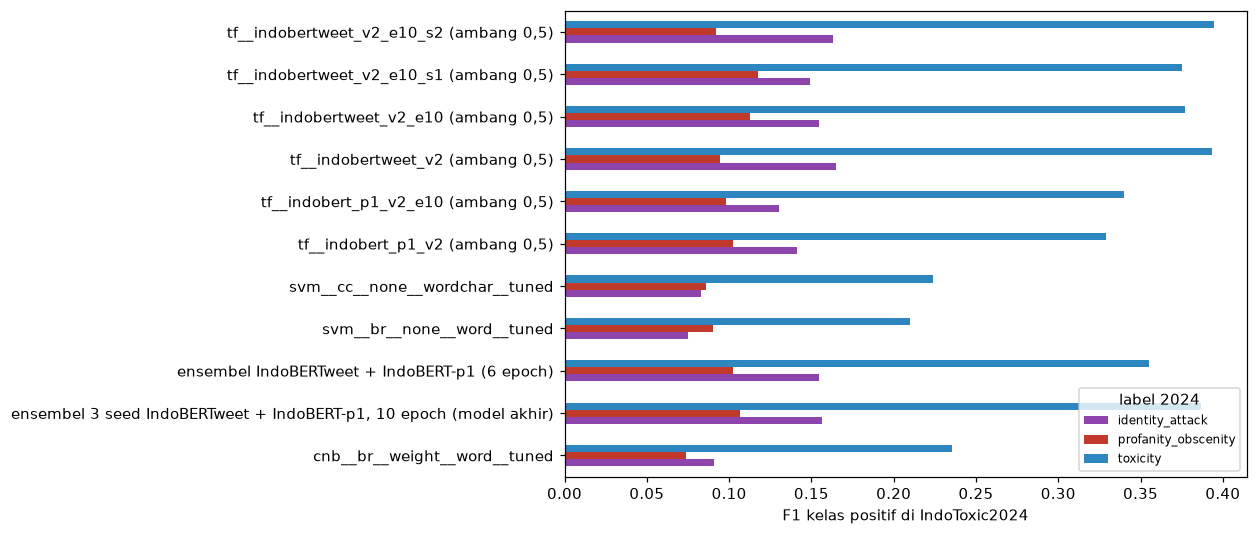

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,hamas,gibran,netanyahu,unhcr,odgj,prize,gencatan,taipei,penampungan,biden,bangladesh,agresi,hangzhou,dikutip,idntimes
frekuensi,2700,625,589,565,460,383,367,322,295,292,287,282,275,261,255


In [65]:
if RUN_CROSS:
    piv = cross.pivot_table(index="model", columns="label_2024", values="F1_pos")
    fig, ax = plt.subplots(figsize=(8, 5.5))
    piv.plot.barh(ax=ax, color=["#8e44ad", "#c0392b", "#2e86c1"])
    ax.set_xlabel("F1 kelas positif di IndoToxic2024"); ax.set_ylabel("")
    ax.legend(title="label 2024", loc="lower right", fontsize=8)
    fig.savefig(FIG / "crosscorpus_f1.png"); plt.show()
    display(oov_top.head(15).T)